# Bengaluru House Price Prediction
## Session 1: setup, load and first-pass cleaning

**Objective.** Load the raw Bengaluru house-price data, understand it, and reduce it to a clean frame that holds only the columns that can feed the model (`location`, `size`, `total_sqft`, `bath`, `price`) with no missing values.

**Target.** `price`, in **lakhs of INR** (1 lakh = 100,000 INR). The `price` column stays in lakhs throughout the project; nothing is converted in this session.

**Out of scope for this session.** Cleaning `total_sqft` (ranges and unit strings, Session 2), encoding, scaling and the train/test split.

## 1. Setup and load

`df_raw` holds the data exactly as loaded and is never modified; every cleaning step works on a new frame.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__}")

Python 3.13.18 | pandas 3.1.0


In [2]:
# Where the CSV can be: the notebook sits in model/, so the data folder is one level up
# (or just data/ if Jupyter was started from the repository root). Kaggle's own file name is
# Bengaluru_House_Data.csv; the same data also circulates as bengaluru_house_prices.csv.
locations = [
    Path("../data/bengaluru_house_prices.csv"),
    Path("../data/Bengaluru_House_Data.csv"),
    Path("data/bengaluru_house_prices.csv"),
    Path("data/Bengaluru_House_Data.csv"),
]

csv_path = None
for path in locations:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("No CSV found. Save the Kaggle file in the repository's data/ folder (see the README).")

df_raw = pd.read_csv(csv_path)
print(f"Loaded {csv_path}")

Loaded ../data/bengaluru_house_prices.csv


## 2. Inspect the raw data

In [3]:
print(df_raw.shape)
display(df_raw.head())
df_raw.dtypes

(13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64
dtype: object

Text columns appear as `object` in pandas below 3 and as `str` from pandas 3 on; either way they are non-numeric. `total_sqft` is one of them: it holds ranges and unit strings, so it stays untouched until Session 2.

In [4]:
null_counts = df_raw.isnull().sum()
pd.DataFrame({"nulls": null_counts, "pct_missing": (null_counts / len(df_raw) * 100).round(2)})

,nulls,pct_missing
area_type,0,0.00
availability,0,0.00
location,1,0.01
size,16,0.12
society,5502,41.31
total_sqft,0,0.00
bath,73,0.55
balcony,609,4.57
price,0,0.00


In [5]:
df_raw["area_type"].value_counts()

area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64

In [6]:
# Observation only: nothing is removed in this session.
n_repeats = int(df_raw.duplicated().sum())
print(f"Rows that exactly repeat an earlier row: {n_repeats:,} ({n_repeats / len(df_raw):.2%})")

Rows that exactly repeat an earlier row: 529 (3.97%)


### Findings

Every figure the brief expected holds: 13,320 rows and 9 columns; `society` is missing for 41.3% of the rows (5,502), `balcony` for 609, `bath` for 73, `size` for 16 and `location` for 1. `area_type`, `availability`, `total_sqft` and `price` have no nulls. `price` is numeric; `total_sqft` is text.

529 rows exactly repeat an earlier row (all nine raw columns). They are left in place; whether to remove them is decided in Session 4, before the train/test split (see the open items at the end).

## 3. Drop columns that cannot feed the model

Evidence for each decision, computed from the raw data:

In [7]:
DROP_COLS = ["area_type", "availability", "society", "balcony"]

evidence = pd.DataFrame({
    "dtype": df_raw[DROP_COLS].dtypes.astype(str),
    "pct_missing": (df_raw[DROP_COLS].isnull().mean() * 100).round(1),
    "n_unique": df_raw[DROP_COLS].nunique(),
    "top_values": pd.Series({c: df_raw[c].value_counts().head(3).to_dict() for c in DROP_COLS}),
})
with pd.option_context("display.max_colwidth", None):
    display(evidence)

,dtype,pct_missing,n_unique,top_values
area_type,str,0.0,4,"{'Super built-up Area': 8790, 'Built-up Area': 2418, 'Plot Area': 2025}"
availability,str,0.0,81,"{'Ready To Move': 10581, '18-Dec': 307, '18-May': 295}"
society,str,41.3,2688,"{'GrrvaGr': 80, 'PrarePa': 76, 'Sryalan': 59}"
balcony,float64,4.6,4,"{2.0: 5113, 1.0: 4897, 3.0: 1672}"


**Justification for each drop**

- **`area_type`**: it changes what `total_sqft` measures (super built-up, built-up, carpet or plot area), so it may well carry signal; it is left out of this first baseline as a judgment call, not because it is unusable, and it is logged in the README as a known limitation. Session 6 tested it and did not add it (its gain was below the decision rule).
- **`availability`**: it mixes the labels "Ready To Move" and "Immediate Possession" with possession-month strings such as "18-Dec" (81 distinct values in all), so it describes when a unit can be occupied rather than what the property is, and it cannot be used without parsing dates.
- **`society`**: 41.3% of its values are missing and the rest hold 2,688 distinct names, so it would be a sparse, high-cardinality categorical that cannot be encoded reliably.
- **`balcony`**: it is a minor amenity count with only four distinct values (0 to 3) and 609 missing entries, so dropping it avoids imputing values for otherwise complete rows and keeps the baseline on the core features.

In [8]:
df = df_raw.drop(columns=DROP_COLS)
assert len(df) == len(df_raw)  # dropping columns never removes rows
df.shape

(13320, 5)

## 4. Remaining nulls in `location`, `size` and `bath`

Count them, look at where they sit, and check that they do not cluster before dropping them.

In [9]:
CORE_NULL_COLS = ["location", "size", "bath"]

nulls_now = df.isnull().sum()
display(nulls_now.to_frame("nulls"))
assert set(nulls_now[nulls_now > 0].index) <= set(CORE_NULL_COLS), "unexpected nulls outside location/size/bath"

,nulls
location,1
size,16
total_sqft,0
bath,73
price,0


In [10]:
null_flags = df[CORE_NULL_COLS].isnull()
null_mask = null_flags.any(axis=1)
n_null_rows = int(null_mask.sum())

print(f"Rows with at least one null in {CORE_NULL_COLS}: {n_null_rows} "
      f"({n_null_rows / len(df):.2%} of {len(df):,})")

# Which of the three columns are null together? (True = null)
null_flags[null_mask].value_counts().rename("rows").reset_index()

Rows with at least one null in ['location', 'size', 'bath']: 74 (0.56% of 13,320)


,location,size,bath,rows
0,False,False,True,57
1,False,True,True,16
2,True,False,False,1


In [11]:
# Raw rows (dropped columns still visible) for the null `location` and `size` cases.
df_raw[df["location"].isnull() | df["size"].isnull()]

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
568,Super built-up Area,Ready To Move,NaN,3 BHK,Grare S,1600,3.0,2.0,86.000
579,Plot Area,Immediate Possession,Sarjapur Road,NaN,Asiss B,1200 - 2400,NaN,NaN,34.185
1775,Plot Area,Immediate Possession,IVC Road,NaN,Orana N,2000 - 5634,NaN,NaN,124.000
2264,Plot Area,Immediate Possession,Banashankari,NaN,NaN,2400,NaN,NaN,460.000
2809,Plot Area,Immediate Possession,Sarjapur Road,NaN,AsdiaAr,1200 - 2400,NaN,NaN,28.785
2862,Plot Area,Immediate Possession,Devanahalli,NaN,Ajleyor,1500 - 2400,NaN,NaN,46.800
5333,Plot Area,Immediate Possession,Devanahalli,NaN,Emngs S,2100 - 5405,NaN,NaN,177.115
6423,Plot Area,Immediate Possession,Whitefield,NaN,SRniaGa,2324,NaN,NaN,26.730
6636,Plot Area,Immediate Possession,Jigani,NaN,S2enste,1500,NaN,NaN,25.490
6719,Plot Area,Immediate Possession,Hoskote,NaN,SJowsn,800 - 2660,NaN,NaN,28.545


### What the null rows have in common

A read-only look: `total_sqft` is not modified here (cleaning it is Session 2); the cell only tests whether each value is written as a range such as "2100 - 2850".

In [12]:
is_range = df["total_sqft"].str.contains(r"\d\s*-\s*\d")

groups = {
    "all rows": pd.Series(True, index=df.index),
    "any null row": null_mask,
    "bath only": null_flags["bath"] & ~null_flags["size"] & ~null_flags["location"],
    "size and bath": null_flags["size"],
    "location only": null_flags["location"],
}
rows = []
for name, m in groups.items():
    rows.append({
        "group": name,
        "rows": int(m.sum()),
        "total_sqft is a range": int(is_range[m].sum()),
        "% range": round(is_range[m].mean() * 100, 1),
        "% balcony also missing": round(df_raw.loc[m, "balcony"].isnull().mean() * 100, 1),
        "% Plot Area": round(df_raw.loc[m, "area_type"].str.contains("Plot").mean() * 100, 1),
    })
pd.DataFrame(rows).set_index("group")

,rows,total_sqft is a range,% range,% balcony also missing,% Plot Area
group,,,,,
all rows,13320,201,1.5,4.6,15.2
any null row,74,57,77.0,98.6,21.6
bath only,57,49,86.0,100.0,0.0
size and bath,16,8,50.0,100.0,100.0
location only,1,0,0.0,0.0,0.0


### Do the null rows cluster?

The brief asks for a check by `location`: the table below lists the locations that hold the most null rows, with each location's null rate. The second table does the same by `area_type`, read from the raw frame because the column is already gone from `df`. Location names are not cleaned yet (that is the first job of Session 3), so spelling variants of one place count as separate locations here.

In [13]:
# Null rows per location, next to the number of listings the location has in total.
loc_null = df.loc[null_mask, "location"].value_counts()   # the one null location is skipped
by_location = pd.DataFrame({
    "null_rows": loc_null,
    "all_rows": df["location"].value_counts().loc[loc_null.index],
})
by_location["null_rate_%"] = (by_location["null_rows"] / by_location["all_rows"] * 100).round(1)

print(f"{loc_null.sum()} null rows have a known location, spread over {len(loc_null)} of the "
      f"{df['location'].nunique():,} locations in the data.")
by_location.head(10)

73 null rows have a known location, spread over 36 of the 1,305 locations in the data.


,null_rows,all_rows,null_rate_%
location,,,
Kanakpura Road,7,273,2.6
Sarjapur Road,7,399,1.8
Whitefield,6,540,1.1
Devanahalli,5,45,11.1
JP Nagar,5,72,6.9
Hennur,3,55,5.5
Yelahanka,3,213,1.4
Jakkur,3,71,4.2
KR Puram,3,91,3.3


In [14]:
# area_type is already dropped from df, but the raw frame still has it: diagnostic use only.
area_check = pd.DataFrame({
    "null_rows": df_raw.loc[null_mask, "area_type"].value_counts(),
    "all_rows": df_raw["area_type"].value_counts(),
}).fillna(0).astype(int)
area_check["null_rate_%"] = (area_check["null_rows"] / area_check["all_rows"] * 100).round(2)
exp_area = n_null_rows * area_check["all_rows"] / area_check["all_rows"].sum()  # expected if scattered at random
area_check["expected_if_random"] = exp_area.round(1)
area_check["lift"] = (area_check["null_rows"] / exp_area).round(2)
area_check.sort_values("null_rows", ascending=False)

,null_rows,all_rows,null_rate_%,expected_if_random,lift
area_type,,,,,
Super built-up Area,50,8790,0.57,48.8,1.02
Plot Area,16,2025,0.79,11.2,1.42
Built-up Area,8,2418,0.33,13.4,0.60
Carpet Area,0,87,0.00,0.5,0.00


### Findings: where the null rows sit

- **74 distinct rows are affected, not the 90 you get by adding the three column counts.** The nulls overlap: the 16 `size` nulls are all also `bath` nulls, 57 rows are null in `bath` only, and 1 row is null in `location` only.
- **Not one location.** 73 of the rows have a known location, spread over 36 of the 1,305 locations; the busiest two hold 7 each (9.6%). A few small locations have high null rates (Devanahalli 5 of 45 listings, JP Nagar 5 of 72, Hennur 3 of 55), but each rests on 3 to 5 rows, too few to say more.
- **The clearest pattern is listing type, not place.** The 16 `size` nulls are all Plot Area listings with availability "Immediate Possession". Of the 57 `bath`-only nulls, 49 (86%) have `total_sqft` written as a range, against 1.5% of all rows, and every `bath` null also lacks `balcony`.
- **By `area_type`** the null rate is 0.3% to 0.8% in each of the three large types (0 of 87 in Carpet Area). Plot Area is the only type clearly above its random share (16 null rows against about 11 expected): those are the 16 `size` nulls.

**Decision: drop these rows rather than impute them.** `location` has no sensible fill value, and `bath` is structurally tied to the bedroom count in `size`, so a median fill would invent data. The affected share is 0.56% of the rows. The drop also removes 57 of the 201 raw rows with a ranged `total_sqft`, so 144 remain for Session 2.

In [15]:
rows_before = len(df)
df = df.dropna()  # the index is deliberately not reset: it keeps each row traceable to its line in the raw CSV
rows_after = len(df)
assert rows_before - rows_after == n_null_rows  # exactly the rows flagged above

print(f"Rows before: {rows_before:,} | after: {rows_after:,} | removed: {rows_before - rows_after:,} "
      f"({(rows_before - rows_after) / rows_before:.2%})")

Rows before: 13,320 | after: 13,246 | removed: 74 (0.56%)


## 5. Final check of the Session 1 frame

In [16]:
assert list(df.columns) == ["location", "size", "total_sqft", "bath", "price"]
assert df.isnull().sum().sum() == 0

print(f"Final shape: {df.shape}")

null_summary = pd.DataFrame({"nulls_before": df_raw.isnull().sum()})
null_summary["nulls_after"] = df.isnull().sum()  # aligns on column name; a dropped column shows as <NA>
display(null_summary.astype("Int64"))
df.head()

Final shape: (13246, 5)


,nulls_before,nulls_after
area_type,0,<NA>
availability,0,<NA>
location,1,0
size,16,0
society,5502,<NA>
total_sqft,0,0
bath,73,0
balcony,609,<NA>
price,0,0


,location,size,total_sqft,bath,price
0,Electronic City Phase II,2 BHK,1056,2.0,39.07
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00
2,Uttarahalli,3 BHK,1440,2.0,62.00
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00
4,Kothanur,2 BHK,1200,2.0,51.00


## Session 2: feature engineering

**Objective.** Turn `size` and `total_sqft` into clean numeric features (`bhk`, and `total_sqft` as a float) and add `price_per_sqft`, so that Session 3 can start on `location`.

Each choice that changes which listings the model can see (the "RK" rows, the `total_sqft` ranges and unit strings) is argued from counts below and logged in the decision log at the end.

**Cautions for the whole session**

- `price_per_sqft` is built from the target (`price`). It must **never be a model input**; it exists only to spot outliers in Session 4.
- Nothing is removed because of an extreme value (`bhk`, `price_per_sqft` or anything else): extremes are reported and left in. The 529 repeated rows are left in too.

In [17]:
# Work on a copy: df (the Session 1 result) stays untouched, and df2 is its own frame.
df2 = df.copy()
df2.shape

(13246, 5)

### Step 1. `bhk` from `size`

`size` is text such as "2 BHK", "4 Bedroom" or "1 RK". The number in front is the bedroom count, so `str.extract` with the regular expression `^(\d+)` (digits at the start of the string) pulls it out. `extract` gives NaN for every row where the pattern does not match, so asserting that nothing is NaN proves that every row matched.

In [18]:
# What follows the number? (the brief says BHK, Bedroom and RK)
print(df2["size"].str.extract(r"^\d+\s*(\w+)", expand=False).value_counts().to_dict())

bhk_text = df2["size"].str.extract(r"^(\d+)", expand=False)
assert bhk_text.notna().all(), "some `size` values have no leading integer"
df2["bhk"] = bhk_text.astype(int)

print(f"bhk runs from {df2['bhk'].min()} to {df2['bhk'].max()}; "
      f"{(df2['bhk'] >= 10).sum()} rows have 10 or more; "
      f"2 and 3 BHK make up {df2['bhk'].isin([2, 3]).mean():.1%} of rows")
df2["bhk"].value_counts().sort_index().to_frame("rows").T

{'BHK': 10718, 'Bedroom': 2515, 'RK': 13}
bhk runs from 1 to 43; 26 rows have 10 or more; 2 and 3 BHK make up 78.2% of rows


bhk,1,2,3,4,5,6,7,8,9,10,11,12,13,14,16,18,19,27,43
rows,649,5527,4832,1395,353,221,100,89,54,14,4,1,1,1,1,1,1,1,1


**The 13 "RK" rows.** "1 RK" means one room plus a kitchen: there is no separate bedroom, so `bhk` has no obvious value for them. The evidence is the rows themselves and how they compare with 1 BHK flats.

In [19]:
is_rk = df2["size"].str.contains("RK")
is_1bhk = df2["size"].str.match(r"1\s*BHK")

for name, mask in [("1 RK", is_rk), ("1 BHK", is_1bhk)]:
    print(f"{name:<6}{mask.sum():>4} rows | median price {df2.loc[mask, 'price'].median():5.2f} lakh | "
          f"median bath {df2.loc[mask, 'bath'].median()}")

df2.loc[is_rk, ["location", "size", "total_sqft", "bath", "price"]]

1 RK    13 rows | median price 25.25 lakh | median bath 1.0
1 BHK  531 rows | median price 32.00 lakh | median bath 1.0


,location,size,total_sqft,bath,price
24,Thanisandra,1 RK,510,1.0,25.25
782,Thanisandra,1 RK,445,1.0,28.00
1363,Thanisandra,1 RK,510,1.0,25.25
2486,Bhoganhalli,1 RK,296,1.0,22.89
2557,Anekal,1 RK,351,1.0,16.00
2788,Rachenahalli,1 RK,440,1.0,28.00
4876,Electronic City,1 RK,435,1.0,19.50
5079,Whitefield,1 RK,905,1.0,52.00
5285,Rachenahalli,1 RK,385 - 440,1.0,19.80
6586,Electronics City Phase 1,1 RK,360,1.0,16.90


**Decision: keep the 13 "RK" rows and give them `bhk = 1`.** All 13 are "1 RK" with one bathroom and a small area (the largest is 905 sqft), and their median price (25.25 lakh) is below that of 1 BHK flats (32.00 lakh), so they belong at the bottom of the bedroom scale, next to 1 BHK. Dropping them would remove a whole listing type for 13 rows (0.10% of the data), and `bhk = 0` would create a value that occurs only 13 times. The cost is that the model cannot tell a 1 RK from a 1 BHK. Logged as decision 7.

### Step 2. `total_sqft` as a number

`total_sqft` is text. `pd.to_numeric(..., errors="coerce")` converts what is a plain number and turns everything else into NaN instead of raising an error. That sorts the column into three groups: plain numbers, ranges ("2100 - 2850") and unit strings ("34.46Sq. Meter"). Each group gets its own rule, and the rules for the ranges and the unit strings change which listings the model sees, so each is argued below.

In [20]:
as_number = pd.to_numeric(df2["total_sqft"], errors="coerce")   # plain numbers -> float; everything else -> NaN
is_plain = as_number.notna()
is_range = df2["total_sqft"].str.contains(r"\d\s*-\s*\d")
is_unit = ~is_plain & ~is_range
assert not (is_plain & is_range).any()                           # no row is counted twice

print(f"plain numbers {is_plain.sum():,} | ranges {is_range.sum()} | unit strings {is_unit.sum()} "
      f"| total {is_plain.sum() + is_range.sum() + is_unit.sum():,} of {len(df2):,} rows")

plain numbers 13,056 | ranges 144 | unit strings 46 | total 13,246 of 13,246 rows


**Ranges become their midpoint.** Split each range at the dash into a lower and an upper end, check that both ends are numbers, and average them. The midpoint is the usual convention, but it hides how wide a range is, so the widest ones are shown.

In [21]:
ends = df2.loc[is_range, "total_sqft"].str.split("-", expand=True)   # one column per end
assert ends.shape[1] == 2, "a range has more than one dash"
low = pd.to_numeric(ends[0], errors="coerce")
high = pd.to_numeric(ends[1], errors="coerce")
assert low.notna().all() and high.notna().all(), "a range end is not a number"
assert (high >= low).all(), "a range runs downwards"

midpoint = (low + high) / 2
spread = high - low
print(f"Median spread of the {len(spread)} ranges: {spread.median():.0f} sqft")

widest = pd.DataFrame({
    "total_sqft": df2.loc[is_range, "total_sqft"],
    "spread": spread,
    "upper / lower": (high / low).round(2),
})
widest.nlargest(5, "spread")

Median spread of the 144 ranges: 160 sqft


,total_sqft,spread,upper / lower
122,3067 - 8156,5089.00,2.66
5940,1349 - 3324,1975.00,2.46
672,3090 - 5002,1912.00,1.62
3174,2249.81 - 4112.19,1862.38,1.83
1694,4000 - 5249,1249.00,1.31


**Unit strings.** 46 rows give a number followed by a unit. The regular expression `^([\d.]+)\s*(.+)$` splits each of them into the number and the unit text, and the per-unit counts decide what to do with them.

In [22]:
units = df2.loc[is_unit, "total_sqft"].str.extract(r"^([\d.]+)\s*(.+)$")   # column 0: the number, column 1: the unit text
units.columns = ["value", "unit"]
assert units.notna().all().all(), "a unit string did not match number + unit"
units["value"] = pd.to_numeric(units["value"])

units.groupby("unit")["value"].agg(["count", "min", "max"]).sort_values("count", ascending=False)

,count,min,max
unit,,,
Sq. Meter,17,24.00,3040.0
Sq. Yards,15,45.00,2940.0
Acres,8,1.25,30.0
Guntha,2,24.00,38.0
Cents,2,3.00,1500.0
Grounds,1,1.00,1.0
Perch,1,4125.00,4125.0


In [23]:
CONVERT = {"Sq. Meter": 10.7639, "Sq. Yards": 9}    # square feet in one of each unit
converted = units[units["unit"].isin(CONVERT)]
left_out = units[~units["unit"].isin(CONVERT)]
print(f"convert {len(converted)} rows, leave out {len(left_out)} rows")

# The rows that would be left out:
df2.loc[left_out.sort_values("unit").index, ["location", "total_sqft", "bath", "price"]]

convert 32 rows, leave out 14 rows


,location,total_sqft,bath,price
1019,Marathi Layout,5.31Acres,1.0,110.0
1086,Narasapura,30Acres,2.0,29.5
6333,Harohalli,2.09Acres,2.0,200.0
7334,Kanakpura Road,2Acres,1.0,125.0
7607,Bommenahalli,15Acres,3.0,217.0
7726,Kanakpura Road,1.26Acres,1.0,125.0
10488,2 Bedroom Furnished Farm House in Kolar Road,1.25Acres,2.0,200.0
11615,arudi,6Acres,2.0,80.0
5453,Kannur,3Cents,6.0,75.0
7001,Thyagaraja Nagar,1500Cents,6.0,290.0


**Decision: convert Sq. Meter (× 10.7639) and Sq. Yards (× 9), and drop the other 14 rows.**

- Square metres and square yards have exact, universal conversion factors (1 m² = 10.7639 sq ft, 1 yd² = 9 sq ft), so these 32 rows (17 + 15) become square feet without guessing.
- The other 14 rows (8 Acres, 2 Cents, 2 Guntha, 1 Perch, 1 Grounds) are land-parcel units. Acres are farmland scale: the smallest listing here, 1.25 acres, is already 54,450 sq ft. Cents, guntha, perch and ground are defined differently from region to region. The rows also look like plots rather than flats ("4125Perch" with 9 bathrooms, "30Acres" for 29.5 lakh).
- The cost: 14 rows (0.11% of 13,246) go, so the model never sees listings quoted in those units.
- Alternatives not taken: dropping all 46 (0.35% of the rows) would also discard 32 ordinary listings; converting every unit needs regional definitions that are hard to defend.

In [24]:
# Fill each group of rows. .loc[row labels] = values lines the values up by row label.
sqft = as_number.copy()                                                           # plain numbers; the rest are NaN so far
sqft.loc[midpoint.index] = midpoint                                               # ranges -> midpoint
sqft.loc[converted.index] = converted["value"] * converted["unit"].map(CONVERT)   # Sq. Meter / Sq. Yards -> sq ft

# Whatever is still NaN must be exactly the unit rows that are deliberately left out.
assert set(sqft.index[sqft.isna()]) == set(left_out.index)

rows_before = len(df2)
# .copy() makes df2 its own frame; without it pandas can warn (SettingWithCopyWarning) when we assign to a filtered slice.
df2 = df2[sqft.notna()].copy()
df2["total_sqft"] = sqft[df2.index]
assert df2["total_sqft"].isna().sum() == 0

print(f"rows before {rows_before:,} | after {len(df2):,} | removed {rows_before - len(df2)}")

rows before 13,246 | after 13,232 | removed 14


### Step 3. `price_per_sqft`

`price` is in **lakhs** of INR and `total_sqft` is in square feet, so `price × 100,000 / total_sqft` is INR per square foot. Leaving out the × 100,000 would give lakhs per sqft, with typical values around 0.05. The arithmetic is vectorized: pandas applies it to whole columns at once, which gives the same numbers as `df2.apply(..., axis=1)` calling a Python function on every row, only much faster.

Reminder: this column is derived from the target, so it is never a model input.

In [25]:
df2["price_per_sqft"] = df2["price"] * 100_000 / df2["total_sqft"]

# Plausibility check on the first row, by hand.
row = df2.iloc[0]
print(f"{row['location']}: {row['price']} lakh x 100,000 / {row['total_sqft']:,.0f} sqft "
      f"= {row['price_per_sqft']:,.0f} INR per sqft")

# Same check for the rows converted from Sq. Meter / Sq. Yards: are they in line with the rest?
conv = df2.loc[converted.index, "price_per_sqft"]
print(f"{len(conv)} converted rows: median {conv.median():,.0f}, min {conv.min():,.0f}, max {conv.max():,.0f} "
      f"| all rows: median {df2['price_per_sqft'].median():,.0f}")

Electronic City Phase II: 39.07 lakh x 100,000 / 1,056 sqft = 3,700 INR per sqft
32 converted rows: median 4,855, min 405, max 98,765 | all rows: median 5,438


### Step 4. `describe()` and one histogram

The new columns, summarised and drawn. Nothing is cleaned on the basis of this step.

In [26]:
pps = df2["price_per_sqft"]
display(df2[["bhk", "total_sqft", "price_per_sqft"]].describe().round(1))
pps.quantile([0.01, 0.05, 0.95, 0.99]).round(0).to_frame("price_per_sqft").T

,bhk,total_sqft,price_per_sqft
count,13232.0,13232.0,13232.0
mean,2.8,1564.5,7922.8
std,1.3,1304.8,106601.3
min,1.0,1.0,267.8
25%,2.0,1100.0,4265.7
50%,3.0,1275.0,5437.9
75%,3.0,1675.0,7323.3
max,43.0,52272.0,12000000.0


,0.01,0.05,0.95,0.99
price_per_sqft,2546.0,3100.0,15321.0,23740.0


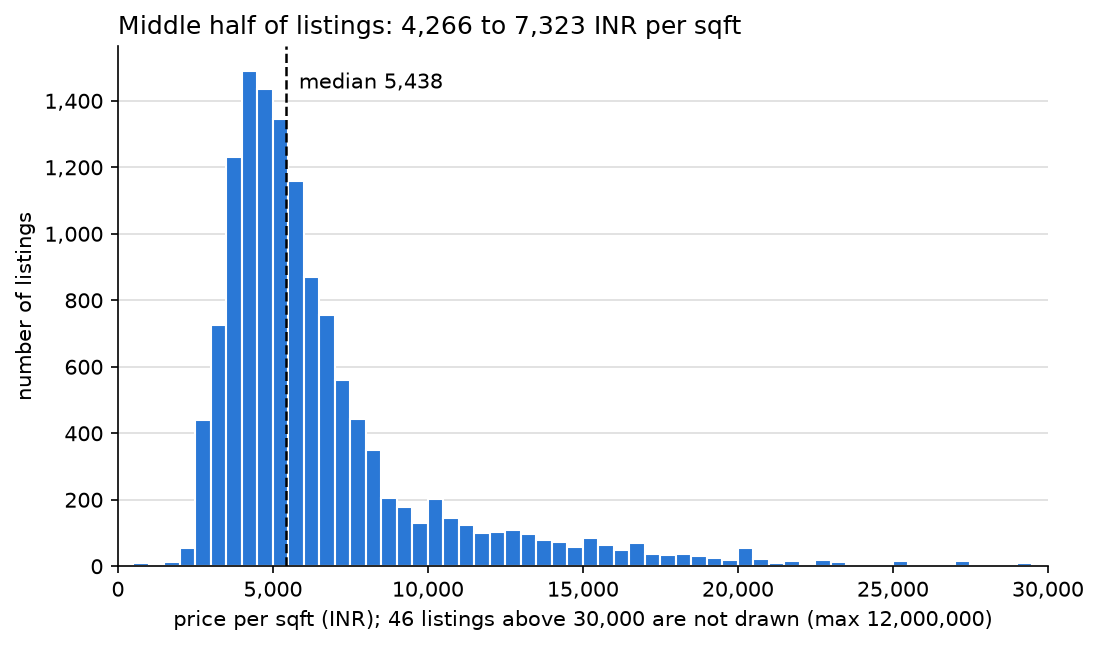

In [27]:
CAP = 30_000    # the x-axis stops here so the bulk of the data is readable; rows above it stay in the data
n_beyond = int((pps > CAP).sum())

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.hist(pps, bins=60, range=(0, CAP), color="#2a78d6", edgecolor="white")
ax.axvline(pps.median(), color="black", linestyle="--", linewidth=1.2)
ax.text(pps.median() + 400, ax.get_ylim()[1] * 0.95, f"median {pps.median():,.0f}", va="top")

ax.set_title(f"Middle half of listings: {pps.quantile(0.25):,.0f} to {pps.quantile(0.75):,.0f} INR per sqft", loc="left")
ax.set_xlabel(f"price per sqft (INR); {n_beyond} listings above {CAP:,} are not drawn (max {pps.max():,.0f})")
ax.set_ylabel("number of listings")
ax.set_xlim(0, CAP)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")   # thousands separators on the tick labels
ax.yaxis.set_major_formatter(lambda y, pos: f"{y:,.0f}")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#dddddd")
ax.set_axisbelow(True)
plt.show()

In [28]:
# Extreme values: reported, not removed.
cols = ["location", "total_sqft", "bath", "price", "bhk", "price_per_sqft"]
print("Highest price_per_sqft:")
display(df2.nlargest(5, "price_per_sqft")[cols].round(1))
print("Lowest price_per_sqft:")
display(df2.nsmallest(5, "price_per_sqft")[cols].round(1))
print("Highest bhk:")
display(df2.nlargest(5, "bhk")[cols].round(1))
print(f"price_per_sqft below 1,000: {(pps < 1000).sum()} rows | above 20,000: {(pps > 20000).sum()} rows")

Highest price_per_sqft:


,location,total_sqft,bath,price,bhk,price_per_sqft
4086,Sarjapur Road,1.0,4.0,120.0,4,12000000.0
4972,Srirampuram,5.0,7.0,115.0,7,2300000.0
349,Suragajakkanahalli,11.0,3.0,74.0,3,672727.3
1122,Grihalakshmi Layout,24.0,2.0,150.0,5,625000.0
11558,Whitefield,60.0,4.0,218.0,4,363333.3


Lowest price_per_sqft:


,location,total_sqft,bath,price,bhk,price_per_sqft
1894,Nelamangala,52272.0,2.0,140.0,3,267.8
674,Yelahanka,35000.0,3.0,130.0,3,371.4
7520,Doddaballapur,11840.3,2.0,48.0,3,405.4
5393,Doddabommasandra,42000.0,8.0,175.0,9,416.7
3228,Dodda Banaswadi,32722.3,5.0,140.0,5,427.8


Highest bhk:


,location,total_sqft,bath,price,bhk,price_per_sqft
4684,Munnekollal,2400.0,40.0,660.0,43,27500.0
1718,2Electronic City Phase II,8000.0,27.0,230.0,27,2875.0
3379,1Hanuman Nagar,2000.0,16.0,490.0,19,24500.0
11559,1Kasavanhalli,1200.0,18.0,200.0,18,16666.7
3609,Koramangala Industrial Layout,10000.0,16.0,550.0,16,5500.0


price_per_sqft below 1,000: 17 rows | above 20,000: 238 rows


**What this shows**

- **The × 100,000 conversion is right.** The median is 5,438 INR per sqft and the middle half runs from 4,266 to 7,323: thousands of INR, as a Bengaluru flat should be. Leaving out the × 100,000 would give values near 0.05.
- **Long right tail.** The mean (7,923) sits well above the median, and 238 rows are above 20,000 (the 99th percentile is 23,740).
- **Implausible values at both ends.** 17 rows are below 1,000 INR per sqft. Eleven of them are plot-sized (11,840 to 52,272 sqft). The other six span 1,798 to 10,961 sqft, and two of those are ordinary home sizes with prices that look too low (BTM Layout: 1,798 sqft at 10 lakh; Begur: 2,400 sqft at 12 lakh). That is a different problem from the plots, and a rule on area would not catch it. The highest values come from tiny `total_sqft` entries: 1, 5, 11, 24 and 60 sqft for homes with 3 to 7 bedrooms, such as 120 lakh for 1 sqft = 12,000,000 INR per sqft. A few rows like these are why the standard deviation (106,601) is more than 13 times the mean.
- **Extreme `bhk`.** 26 rows have 10 or more bedrooms; the top five are 43, 27, 19, 18 and 16. The 43-bedroom row has 2,400 sqft and 40 bathrooms. Three of the five locations begin with a digit ("2Electronic City Phase II", "1Hanuman Nagar", "1Kasavanhalli"), which is a location-cleaning question for Session 3.
- **Converted unit rows.** Their median (4,855) is close to the overall median, so the two factors look right. Two of the five lowest values are large Sq. Meter plots (1,100 and 3,040 sq m), and the highest of the 32 is a 45 Sq. Yards listing with 6 bathrooms (98,765).

All of these rows are left in. Deciding which ones are real outliers is Session 4's job.

### Step 5. Drop `size`, then check the final frame

`size` is replaced by `bhk`, so it goes last, once the assertion in Step 1 has confirmed that `bhk` is complete. The assertion is repeated just before the drop.

In [29]:
assert df2["bhk"].notna().all()            # bhk is complete, so `size` is no longer needed
df2 = df2.drop(columns="size")

assert list(df2.columns) == ["location", "total_sqft", "bath", "price", "bhk", "price_per_sqft"]
assert df2.isnull().sum().sum() == 0
assert pd.api.types.is_float_dtype(df2["total_sqft"]) and pd.api.types.is_integer_dtype(df2["bhk"])

print(f"Final Session 2 shape: {df2.shape}")
display(df2.dtypes.to_frame("dtype").T)
df2.head()

Final Session 2 shape: (13232, 6)


,location,total_sqft,bath,price,bhk,price_per_sqft
dtype,str,float64,float64,float64,int64,float64


,location,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,1200.0,2.0,51.00,2,4250.000000


## Session 3: location cleaning and dimensionality reduction

**Objective.** Reduce `location` from about 1,300 raw names to roughly 240 real locations plus one `other` bucket, with a documented threshold.

**Why.** One-hot encoding (Session 5) turns every distinct location into a column. With about 1,300 locations and 13,000 rows, most of those columns would be nearly empty and the model could not learn from them. Grouping rare locations keeps the feature matrix small.

**Cautions for the whole session**

- No rows are removed (asserted below); duplicates and outliers are still left in.
- `other` is a catch-all, not a place. It will hold about a fifth of the rows, and the website session decides how it is treated.
- The threshold is a convention. Session 6 tested 5 and 20 by cross-validation and kept 10.
- Listing counts are computed on all rows, before the train/test split. That is a known limitation (see the README).
- `price_per_sqft` stays out of the features.

In [30]:
# Work on a copy: df2 (the Session 2 result) stays untouched.
df3 = df2.copy()
df3.shape

(13232, 6)

### Step 1. Normalize the names

Three clean-ups, in this order:

1. **Whitespace.** `str.split()` cuts a name at every run of whitespace (and drops the ends), and `str.join(" ")` glues the words back with a single space. This fixes "Sarjapur  Road" (two spaces).
2. **Case.** A casefolded copy of each name is the key, so "JP Nagar" and "jp nagar" count as one place.
3. **Trailing punctuation.** Names such as "Kudlu Village," end in a comma. The cell below shows which characters actually end names, so the clean-up covers what is there.

Each key then gets its most frequent spelling as the clean name, so the website can later show readable names ("JP Nagar", not "jp nagar").

The whitespace and trailing-punctuation steps are the function `normalize_location` in `model/pricing.py`, which Session 6 wrote. The cell that applies the clean-up imports it, so the notebook and the API clean a name in the same way; the exploration above it still shows the steps one at a time.

In [31]:
# Strip and collapse whitespace: split() cuts at every run of whitespace and drops the ends,
# join(" ") glues the words back together with a single space.
ws = df3["location"].str.split().str.join(" ")

# Which characters end a name when they are not a letter or a digit? (counted in rows)
last_char = ws.str[-1]
last_char[~last_char.str.isalnum()].value_counts()

location
,    56
.     3
)     1
Name: count, dtype: int64

The commas (56 rows) and periods (3 rows) are trailing punctuation. The single `)` closes a bracket in "Kengeri Satellite Town ( BDA SITE)" and belongs to the name, so only commas, periods and the spaces in front of them are removed.

In [32]:
from pricing import normalize_location        # the function the API uses too (model/pricing.py, written in Session 6)

stripped = df3["location"].map(normalize_location)       # whitespace collapsed; trailing commas, periods and the spaces before them removed
assert (stripped == ws.str.rstrip(" ,.")).all()          # the same names as the step-by-step version above
assert (stripped.str.len() > 0).all()          # no name has become empty
key = stripped.str.casefold()                  # one key per place, whatever the capitalisation

# Each key gets its most frequent spelling as the clean name; transform() puts that spelling on every row of the key.
# If two spellings tie, mode() lists them in sorted order, so the pick is the same on every run.
df3["location"] = stripped.groupby(key).transform(lambda spellings: spellings.mode().iloc[0])
assert df3["location"].nunique() == key.nunique()      # exactly one clean name per key

n_spellings = stripped.groupby(key).nunique()          # how many spellings each key has
multi = n_spellings[n_spellings > 1].index
print(f"rows changed by the trailing-punctuation step: {(ws != stripped).sum()}")
print(f"{len(multi)} places are written in more than one way; the busiest has {key.value_counts().loc[multi].max()} listings")

rows changed by the trailing-punctuation step: 59
12 places are written in more than one way; the busiest has 9 listings


In [33]:
# Distinct names after each clean-up, and how the names split at 10 listings.
stages = {
    "raw": df2["location"],
    "strip + collapse whitespace": ws,
    "+ casefold": ws.str.casefold(),
    "+ trailing punctuation removed": key,
}
funnel = []
for step, names in stages.items():
    n = names.value_counts()                   # listings per name
    funnel.append({
        "step": step,
        "distinct names": len(n),
        "> 10: names": int((n > 10).sum()),
        "> 10: rows": int(n[n > 10].sum()),
        "<= 10: names": int((n <= 10).sum()),
        "<= 10: rows": int(n[n <= 10].sum()),
        "<= 10: % of rows": round(n[n <= 10].sum() / len(names) * 100, 1),
        "1 listing: names": int((n == 1).sum()),
    })
pd.DataFrame(funnel).set_index("step")

,distinct names,> 10: names,> 10: rows,<= 10: names,<= 10: rows,<= 10: % of rows,1 listing: names
step,,,,,,,
raw,1299,240,10334,1059,2898,21.9,476
strip + collapse whitespace,1288,240,10349,1048,2883,21.8,469
+ casefold,1276,240,10349,1036,2883,21.8,453
+ trailing punctuation removed,1266,240,10364,1026,2868,21.7,447


**What the clean-up did.** The distinct names fall from 1,299 to 1,288 (whitespace), 1,276 (case) and 1,266 (trailing punctuation). The number of locations with more than 10 listings stays at 240 at every stage, so the clean-up never changes which locations are named; it only moves rows into them, and the share of rows in locations with 10 or fewer listings goes from 21.9% to 21.7%. Case merging reduces the names but moves no rows across the threshold: the 12 places written in more than one way all have 9 or fewer listings.

Up to the case step the numbers are the brief's expected findings exactly: 240 locations with more than 10 listings covering 10,349 rows, 1,036 locations with 10 or fewer covering 2,883 rows (21.8%), and 453 locations with a single listing. The trailing-punctuation step moves 15 more rows into named locations (Sarjapur Road gains 8 and Whitefield 2), so the biggest locations below are Whitefield 537 and Sarjapur Road 400 where the brief had 535 and 392. The other three match: Electronic City 304, Kanakpura Road 264, Thanisandra 236.

### Step 2. Count listings per location

How many locations have 1, up to 5, up to 10 and up to 20 listings, and what share of the rows each threshold would move into `other`.

In [34]:
counts = df3["location"].value_counts()          # listings per clean location
print("Biggest locations:", counts.head(5).to_dict())

threshold_rows = []
for t in [1, 5, 10, 20]:
    small = counts[counts <= t]                  # the locations at or below the threshold
    threshold_rows.append({
        "threshold": f"<= {t}",
        "locations at or below": len(small),
        "named locations kept": len(counts) - len(small),
        "rows moved to other": int(small.sum()),
        "% of rows": round(small.sum() / len(df3) * 100, 1),
    })
pd.DataFrame(threshold_rows).set_index("threshold")

Biggest locations: {'Whitefield': 537, 'Sarjapur Road': 400, 'Electronic City': 304, 'Kanakpura Road': 264, 'Thanisandra': 236}


,locations at or below,named locations kept,rows moved to other,% of rows
threshold,,,,
<= 1,447,819,447,3.4
<= 5,880,386,1763,13.3
<= 10,1026,240,2868,21.7
<= 20,1123,143,4280,32.3


### Step 3. Pick a threshold and replace rare locations with `other`

**Decision: locations with 10 or fewer listings become `other`.** That is 1,026 of the 1,266 names and 2,868 rows (21.7%); the 240 locations with 11 or more listings keep their names, which makes 241 categories with `other`. A location with 10 listings gives the model at most 10 examples to learn from (fewer once rows are held out for testing), too few to estimate a location effect.

The alternatives in the table above: threshold 5 keeps 386 named locations (146 more columns once the locations are one-hot encoded) and moves 13.3% of the rows; threshold 20 keeps 143 and moves 32.3%, so nearly a third of the listings would lose their location; threshold 1 (only single listings) keeps 819 locations and moves 3.4%. Ten is the brief's default and a convention; Session 6 tested 5 and 20 by cross-validation and kept 10.

In [35]:
THRESHOLD = 10
OTHER = "other"
assert OTHER not in counts.index                         # no real location is called "other"

listings = df3["location"].map(counts)                   # listings of each row's location, repeated on every row
df3.loc[listings <= THRESHOLD, "location"] = OTHER

n_named = int((counts > THRESHOLD).sum())
n_other = int((df3["location"] == OTHER).sum())
assert len(df3) == 13_232                                # no rows removed
assert list(df3.columns) == list(df2.columns)            # columns unchanged
assert df3["location"].notna().all()
assert df3["location"].nunique() == n_named + 1          # the named locations plus "other"

print(f"threshold {THRESHOLD}: {n_named} named locations + '{OTHER}' = {df3['location'].nunique()} categories")
print(f"'{OTHER}' holds {n_other:,} of {len(df3):,} rows ({n_other / len(df3):.1%})")
df3["location"].value_counts().head(6).to_frame("rows")

threshold 10: 240 named locations + 'other' = 241 categories
'other' holds 2,868 of 13,232 rows (21.7%)


,rows
location,
other,2868
Whitefield,537
Sarjapur Road,400
Electronic City,304
Kanakpura Road,264
Thanisandra,236


### Step 4. `other` compared with the named locations

Median `price_per_sqft` (INR) of the rows in `other` against all rows in named locations, with the quartiles for the spread.

In [36]:
is_other = df3["location"] == OTHER
by_group = df3.groupby(is_other)["price_per_sqft"].describe()[["count", "25%", "50%", "75%"]].round(0).astype(int)
by_group.index = ["named locations", "other"]      # groupby sorts False before True
by_group

,count,25%,50%,75%
named locations,10364,4221,5333,6978
other,2868,4444,5908,10000


**What this shows.** The median `price_per_sqft` of `other` is 5,908 INR against 5,333 for the named locations (10.8% higher), and its spread is much wider: the middle half of `other` runs from 4,444 to 10,000, against 4,221 to 6,978. With 2,868 rows, `other` is also the largest category, more than five times the largest named location (Whitefield, 537). It is a catch-all of many unrelated places, not a place: knowing that a listing is in `other` says little about its price. The website session decides how it is treated.

### Step 5. Digit-glued names

Names such as "1Hanuman Nagar" and "2Electronic City Phase II" have a digit directly in front of a letter. Ordinals ("1st", "7th") also have that shape but are legitimate, so they are excluded. The names are listed, not edited.

In [37]:
# A digit directly followed by a letter, unless the letters are an ordinal suffix (1st, 2nd, 3rd, 7th).
# (?i) ignores case, \d is a digit, (?!...) means "not followed by", \b is a word boundary.
glued_pattern = r"(?i)\d(?!(?:st|nd|rd|th)\b)[a-z]"
glued = counts[counts.index.str.contains(glued_pattern)]       # clean name -> listings
print(f"{len(glued)} names match, covering {glued.sum()} rows ({glued.sum() / len(df3):.2%} of all rows)")
print(f"most listings of any of them: {glued.max()} (threshold {THRESHOLD}), so {int((glued > THRESHOLD).sum())} survive")

# Context: all names that start with a digit.
starts_with_digit = counts[counts.index.str.match(r"\d")]
ordinal = starts_with_digit.index.str.match(r"(?i)\d+(st|nd|rd|th)\b")
print(f"{len(starts_with_digit)} names start with a digit; {ordinal.sum()} are ordinals like '7th Phase JP Nagar'; "
      f"{int((starts_with_digit[ordinal] > THRESHOLD).sum())} of those survive the threshold")

# The matching rows. df3 now shows `other` in `location`, so the cleaned name is added as `name`.
glued_rows = df3.assign(name=stripped)[stripped.isin(glued.index)]
glued_rows[["name", "location", "bhk", "bath", "total_sqft", "price"]]

9 names match, covering 9 rows (0.07% of all rows)
most listings of any of them: 1 (threshold 10), so 0 survive
62 names start with a digit; 51 are ordinals like '7th Phase JP Nagar'; 10 of those survive the threshold


,name,location,bhk,bath,total_sqft,price
1718,2Electronic City Phase II,other,27,27.0,8000.0,230.0
3379,1Hanuman Nagar,other,19,16.0,2000.0,490.0
4105,Indranagar 100ft road defence colony,other,5,5.0,5800.0,80.0
4916,1Channasandra,other,14,15.0,1250.0,125.0
6034,1A Block Koramangala,other,4,4.0,2360.0,650.0
6621,BTM Layout 1stage 9th Main,other,7,6.0,600.0,138.0
7568,bsk 6th stage 2ad block near sri conversation ...,other,4,4.0,600.0,87.0
9935,1Hoysalanagar,other,13,13.0,5425.0,275.0
11559,1Kasavanhalli,other,18,18.0,1200.0,200.0


**What this shows**

- **Nine names match, covering 9 rows (0.07% of the data), with one listing each, so none survives the threshold.** All nine rows are in `other`, and no name was edited by hand.
- **Six of the nine start with a digit** (the pattern in the brief). Five of those six also have an extreme bedroom count: `bhk` 13 to 27 with a bathroom count close to it (for example "2Electronic City Phase II": 27 bedrooms, 27 bathrooms). Together with the digit glued to the name, these look like bad rows rather than just misnamed places; whether to remove them is a question for Session 4. The sixth, "1A Block Koramangala" (4 bedrooms), is a real block name.
- **The other three have a digit inside the name**: "100ft", "1stage" and "2ad". Their bedroom counts (4 to 7) are ordinary, and they look like free text with typos rather than leaked digits.
- **Digit-leading names in general.** 62 names start with a digit; 51 are ordinals such as "7th Phase JP Nagar", and 10 of those survive the threshold (the other 41 have 10 or fewer listings and go to `other`). The remaining 11 are the six glued names above plus five written with a space after the digit ("1 Giri Nagar", "1 Ramamurthy Nagar", "1 Annasandrapalya", "1 Immadihalli", "4 Bedroom Farm House in Bagalur"). Those five do not match the brief's rule, have one listing each, and also fall into `other`.

## Session 4: duplicates and outlier removal

**Objective.** Remove repeated listings and implausible rows with rules that each have a stated reason, a count and a look at the rows they remove, and finish with a frame that is fit for modeling.

**The rules, in this order**

1. **Repeats**: rows that repeat an earlier row on all nine raw columns.
2. **Domain rules**: fewer than 300 sqft per bedroom, and more than `bhk + 2` bathrooms.
3. **Per-location fences**: `log(price_per_sqft)` outside the IQR fences of its own location (locations with 10 or more rows).
4. **Pooled fence**: one IQR fence on `log(price_per_sqft)` for all the rows in places with fewer than 10 rows.

**Why this order.** Quartiles and fences are computed from whatever rows are present when a rule runs. A repeated row counts twice in every quartile, and a garbage row (120 lakh for 1 sqft) drags up the fences of its location. So the repeats go first, then the domain rules that remove impossible rows, and only then the fences. Rule 3 measures the effect.

**Cautions for the whole session**

- Every rule is counted, and 10 random removed rows per rule are printed so the rule can be checked by eye.
- Nothing is edited to rescue a row: a row is kept or removed.
- The fences use the cleaned location names (`location_clean`), never the grouped `location`: its `other` bucket mixes many unrelated places, so a fence over it would mean nothing.
- Rules 3 and 4 work on `log(price_per_sqft)`. The first version of this notebook used the raw values; its results are kept as a comparison ("Raw fences against log fences", after Rule 4).
- `price_per_sqft` stays in the frame until the first step of Session 5. It is built from the target, so it must never be a model input.
- The rules run on all rows before the train/test split, which is a known limitation (see the README).

In [38]:
import numpy as np

# Work on a copy: df3 (the Session 3 result) stays untouched, so "before" is still available for the figures.
df4 = df3.copy()
assert df4.shape == (13_232, 6)

SEED = 42          # every random sample below uses this seed, so the same rows come up on every run
MIN_ROWS = 10      # a location needs at least this many rows to get its own fences (Rule 3)

# The cleaned location names from before the rare ones became "other". Session 3 overwrote them in df3,
# so they are rebuilt here with the same function (`normalize_location`), as a separate Series aligned to the frame by row label.
# Fences and counts below use this Series, never the grouped df4["location"].
cleaned = df2["location"].map(normalize_location)
location_clean = cleaned.groupby(cleaned.str.casefold()).transform(lambda spellings: spellings.mode().iloc[0])

kept_name = df3["location"] != OTHER
assert location_clean.nunique() == 1_266                                            # the 1,266 names of Session 3
assert (location_clean[kept_name] == df3.loc[kept_name, "location"]).all()          # same name wherever Session 3 kept a name
print(f"'{OTHER}' mixes {location_clean[~kept_name].nunique():,} different places in {(~kept_name).sum():,} rows")

# How expensive is a row's neighbourhood? The median price_per_sqft of its location, over the 13,232 rows.
location_level = df3["price_per_sqft"].groupby(location_clean).transform("median")

'other' mixes 1,026 different places in 2,868 rows


In [39]:
R_REPEATS = "repeated rows (all nine raw columns)"
R_AREA = "fewer than 300 sqft per bedroom"
R_BATH = "more than bhk + 2 bathrooms"
R_LOCATION = "outside the log fences of its location"
R_POOLED = "outside the pooled log fence (small locations)"

steps = []       # one entry per rule; the waterfall table is built from it
removed = {}     # the rows each rule removes, kept for the samples and for the comparison with the survivors


def apply_rule(frame, rule, flag):
    """Remove the rows where `flag` is True. The rows go to `removed`, the counts to `steps`."""
    removed[rule] = frame[flag]
    steps.append({"rule": rule, "rows before": len(frame), "removed": int(flag.sum()), "rows after": int((~flag).sum())})
    return frame[~flag]


def look(rule, **extra):
    """10 random removed rows (all of them if the rule removed fewer). The clean name replaces the grouped location."""
    rows = removed[rule]
    rows = rows.sample(min(10, len(rows)), random_state=SEED).sort_index()
    return rows.assign(location=location_clean, location_median_pps=location_level, **extra).round(1)


def places_by_rows(rows):
    """The clean place names of these rows, most rows first. Equal counts stay in alphabetical order, so the order does not depend on the pandas version."""
    return location_clean[rows.index].value_counts().sort_index().sort_values(ascending=False, kind="stable")

### Rule 1. Repeated listings

**Reason.** A listing that appears twice would land on both sides of the train/test split, so the model would be scored on rows it has already seen, and every quartile below would count it twice.

**Test.** `df_raw.duplicated()` on all nine raw columns. With `keep="first"` the first copy stays and every later copy is flagged. The nine raw columns are the right test: on the five columns the frame kept, two different flats of the same size at the same price in the same place look identical, although `society`, `area_type`, `availability` or `balcony` can tell them apart. The drops in Sessions 1 and 2 kept the raw row labels, so the flags are matched to the frame by index.

In [40]:
repeat_flag = df_raw.duplicated()                                    # all nine raw columns; every copy after the first is True
assert (df3["price"] == df_raw.loc[df3.index, "price"]).all()        # df3 still carries the raw row labels, so matching by index is valid
is_repeat = repeat_flag.loc[df3.index]                               # match to our frame by row label

print(f"repeated rows in the raw data: {repeat_flag.sum()} | inside the Session 3 frame: {is_repeat.sum()}")
five = ["location", "total_sqft", "bath", "price", "bhk"]            # the five kept columns (location as it was before Session 3)
print(f"judged on those five columns the count would be {df2.duplicated(subset=five).sum()}, "
      f"which includes flats that differ in society, area_type, availability or balcony")

# How many copies does each repeated listing have?
rows_per_listing = df_raw.value_counts(dropna=False)                 # identical raw rows are counted together
rows_per_listing[rows_per_listing > 1].value_counts().sort_index().rename_axis("copies").to_frame("listings").T

repeated rows in the raw data: 529 | inside the Session 3 frame: 529
judged on those five columns the count would be 888, which includes flats that differ in society, area_type, availability or balcony


copies,2,3,4,5,6,7,9,10
listings,301,49,13,7,4,3,2,1


In [41]:
df4 = apply_rule(df4, R_REPEATS, is_repeat)
print(f"rows: {len(df3):,} -> {len(df4):,}")

# Look at what was removed: 10 random rows in their raw form, with the row label of the copy that stays
# and the number of identical rows in all (the kept one included).
by_listing = df_raw.reset_index().groupby(list(df_raw.columns), dropna=False)["index"]
first_copy = by_listing.transform("min")
n_copies = by_listing.transform("size")
assert first_copy.index.equals(df_raw.index)

sample = removed[R_REPEATS].sample(10, random_state=SEED).sort_index()
df_raw.loc[sample.index].assign(kept_copy=first_copy, copies=n_copies)

rows: 13,232 -> 12,703


,area_type,availability,location,size,society,total_sqft,bath,balcony,price,kept_copy,copies
1477,Super built-up Area,Ready To Move,Uttarahalli,3 BHK,Aklia R,1330,2.0,1.0,56.00,1096,2
5097,Super built-up Area,19-Jun,Hebbal,4 BHK,Raard B,2790,4.0,3.0,198.00,1840,3
5682,Super built-up Area,Ready To Move,Budigere,3 BHK,PrityTr,1820,3.0,2.0,93.00,4135,2
6513,Super built-up Area,19-Dec,Marathahalli,3 BHK,PrensKe,1469,3.0,1.0,89.00,1626,2
8607,Super built-up Area,19-Jul,Kanakpura Road,3 BHK,Soazak,1592,3.0,NaN,125.00,2248,2
10183,Super built-up Area,Ready To Move,HSR Layout,2 BHK,NRosete,1140,2.0,2.0,46.00,1052,9
10474,Super built-up Area,18-Sep,Chandapura,2 BHK,SunceEs,1015,2.0,2.0,25.88,887,2
11465,Super built-up Area,Ready To Move,7th Phase JP Nagar,3 BHK,Eladero,1575,2.0,2.0,110.00,2963,2
12853,Super built-up Area,Ready To Move,Yelahanka,3 BHK,Pyikad,1282,2.0,1.0,48.72,7601,2
13271,Super built-up Area,Ready To Move,Uttarahalli,2 BHK,Ayaya A,1075,2.0,1.0,46.76,7102,2


**What this shows**

- **All 529 repeats are in the frame, and 12,703 rows are left.** None had been dropped in Sessions 1 or 2: identical rows share the columns those drops looked at, so they were kept or dropped together.
- **Nine columns, not five.** On the five kept columns the count would be 888, which is 359 more. Those 359 rows match another row in location, area, bathrooms, price and bedrooms but differ in `society`, `area_type`, `availability` or `balcony`, so they can be different flats.
- **380 listings repeat**: 301 appear twice, 49 three times, and the most repeated has 10 copies. Each sampled row has an identical earlier row (`kept_copy`, always a lower row label).
- **What the rule cannot tell.** The data has no listing id, so one flat posted twice and two identical flats in one project at one price look the same. A few real flats may be lost; one copy of each always stays. Session 6 compared scores with and without the repeats (Part A there).
- **Who loses rows.** The comparison at the end of the session shows that the removed rows are ordinary for their location (price per sqft 0.99 times the location median) and a little cheaper than the survivors (median price 55 lakh against 69.5). They sit in a few places: Haralur Road 40, Uttarahalli 29, Kanakpura Road 24, Sarjapur Road 20.

### Rule 2. Domain rules

**Reason.** Two things no price can rescue. A bedroom needs floor area, so a listing with fewer than 300 sqft per bedroom (`total_sqft / bhk`) has a wrong area or a wrong bedroom count; this is the rule that catches the 1 to 60 sqft entries and the 43-bedroom row on 2,400 sqft. And a home does not have more than two bathrooms beyond its bedrooms (`bath > bhk + 2`).

Both thresholds are conventions, so the table shows what 250 and 350 would do. The rule looks at area and bedrooms, not at price, so it can remove a real home along with the wrong rows; the median `price_per_sqft` of the flagged rows is in the table for that reason.

In [42]:
too_many_baths = df4["bath"] > df4["bhk"] + 2

rows = []
for per_bedroom in [250, 300, 350]:
    too_small = df4["total_sqft"] / df4["bhk"] < per_bedroom
    flagged = too_small | too_many_baths                  # composing two masks: a row is flagged if either rule hits it
    rows.append({
        "sqft per bedroom below": per_bedroom,
        "area rule alone": int(too_small.sum()),
        "area or bathroom rule": int(flagged.sum()),
        "% of rows": round(flagged.mean() * 100, 1),
        "median price_per_sqft of the flagged rows": round(df4.loc[flagged, "price_per_sqft"].median()),
    })
display(pd.DataFrame(rows).set_index("sqft per bedroom below"))
print(f"median price_per_sqft of all {len(df4):,} rows: {df4['price_per_sqft'].median():,.0f}")

,area rule alone,area or bathroom rule,% of rows,median price_per_sqft of the flagged rows
sqft per bedroom below,,,,
250,605,616,4.8,13333
300,737,746,5.9,12500
350,1086,1095,8.6,11733


median price_per_sqft of all 12,703 rows: 5,484


In [43]:
# The brief measured its counts on all 13,232 rows, repeats still in. The same rules on that basis:
a = df3["total_sqft"] / df3["bhk"] < 300
b = df3["bath"] > df3["bhk"] + 2
print(f"all {len(df3):,} rows: {a.sum()} under 300 sqft per bedroom + {b.sum()} with more than bhk + 2 bathrooms "
      f"- {(a & b).sum()} in both = {(a | b).sum()} ({(a | b).mean():.1%})")

too_small = df4["total_sqft"] / df4["bhk"] < 300
print(f"after Rule 1 ({len(df4):,} rows): {too_small.sum()} + {too_many_baths.sum()} - {(too_small & too_many_baths).sum()} in both "
      f"= {(too_small | too_many_baths).sum()} ({(too_small | too_many_baths).mean():.1%})")

df4 = apply_rule(df4, R_AREA, too_small)
df4 = apply_rule(df4, R_BATH, df4["bath"] > df4["bhk"] + 2)    # recomputed: the rows the first rule did not already take
print(f"rows: {steps[0]['rows after']:,} -> {len(df4):,}")

print("\nRemoved by the area rule (10 random rows):")
display(look(R_AREA, sqft_per_bedroom=df3["total_sqft"] / df3["bhk"]))

area_rows = removed[R_AREA]
print(f"the area rule's {len(area_rows)} rows: {(area_rows['bhk'] >= 4).sum()} have 4 or more bedrooms (median {area_rows['bhk'].median():.0f}), "
      f"the median is {(area_rows['total_sqft'] / area_rows['bhk']).median():.0f} sqft per bedroom, {(area_rows['total_sqft'] <= 100).sum()} have 100 sqft or less")
print(f"exactly 1,200 sqft: {(area_rows['total_sqft'] == 1200).sum()} of them ({(area_rows['total_sqft'] == 1200).mean():.0%}), "
      f"against {(df3['total_sqft'] == 1200).mean():.1%} of all rows\n")

print("Removed by the bathroom rule (all of them, there are fewer than 10):")
display(look(R_BATH, bath_minus_bhk=df3["bath"] - df3["bhk"]))

all 13,232 rows: 747 under 300 sqft per bedroom + 16 with more than bhk + 2 bathrooms - 7 in both = 756 (5.7%)
after Rule 1 (12,703 rows): 737 + 16 - 7 in both = 746 (5.9%)
rows: 12,703 -> 11,957

Removed by the area rule (10 random rows):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps,sqft_per_bedroom
727,Jeevan bima nagar,1210.0,4.0,160.0,5,13223.1,12703.3,242.0
807,HBR Layout,675.0,3.0,59.0,4,8740.7,7938.2,168.8
3523,Jigani,1200.0,10.0,105.0,10,8750.0,5330.6,120.0
4714,Nagarbhavi,1200.0,4.0,240.0,5,20000.0,7619.0,240.0
9869,Bagalakunte,750.0,3.0,95.0,5,12666.7,8928.0,150.0
9909,Uttarahalli,1200.0,6.0,330.0,6,27500.0,4058.5,200.0
10327,Govindapura,702.0,4.0,65.0,4,9259.3,6717.6,175.5
10386,M V Extenstion,900.0,5.0,135.0,5,15000.0,13055.6,180.0
10981,Hosa Road,900.0,5.0,55.0,5,6111.1,5072.0,180.0
12215,Banaswadi,1200.0,6.0,220.0,6,18333.3,5397.9,200.0


the area rule's 737 rows: 600 have 4 or more bedrooms (median 5), the median is 200 sqft per bedroom, 7 have 100 sqft or less
exactly 1,200 sqft: 173 of them (23%), against 6.4% of all rows

Removed by the bathroom rule (all of them, there are fewer than 10):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps,bath_minus_bhk
1078,BTM 1st Stage,3300.0,14.0,500.0,9,15151.5,14166.7,5.0
2620,Sathya Sai Layout,11338.0,9.0,1000.0,6,8819.9,9370.9,3.0
6838,Rajaji Nagar,7500.0,8.0,1700.0,5,22666.7,13980.9,3.0
7709,Chikkabanavar,2460.0,7.0,80.0,4,3252.0,4041.7,3.0
9974,Sector 1 HSR Layout,2400.0,6.0,775.0,3,32291.7,9104.3,3.0
11366,Nagasandra,7000.0,8.0,450.0,4,6428.6,6247.6,4.0
12103,Thanisandra,1806.0,6.0,116.0,3,6423.0,5706.6,3.0
12443,Dollars Colony,4350.0,8.0,2600.0,4,59770.1,11209.7,4.0
13067,Defence Colony,7150.0,13.0,3600.0,10,50349.7,13543.3,3.0


**What this shows**

- **The counts match the brief's measurement.** On all 13,232 rows the area rule flags 747 rows and the bathroom rule 16; 7 rows fail both, so 756 (5.7%) fail at least one. With the repeats gone the counts are 737, 16 and 746 (5.9% of 12,703). The bathroom rule adds only 9 rows to what the area rule takes.
- **300 sits on a slope, not at a boundary in the data.** 250 would keep 132 of the 737 rows; 350 would remove 349 more (1,095 rows, 8.6%). The flagged rows have a much higher `price_per_sqft` than the rest at every threshold (median 13,333, 12,500 and 11,733 against 5,484), so even the extra rows at 350 are unusual. The threshold stays at 300, the brief's value.
- **The area rule mostly removes many-bedroom houses.** 600 of its 737 rows have 4 or more bedrooms (median 5, with a median of 200 sqft per bedroom), and only 7 have 100 sqft or less. 173 of them (23%) are exactly 1,200 sqft, against 6.4% of all rows. 1,200 sqft is the size of a 30 × 40 ft site, which suggests that for many of these houses `total_sqft` is the site and not the floor area. They are probably real homes whose area does not mean what it means for a flat. The cost is that the model sees fewer large houses.
- **The bathroom rule takes 9 rows, mostly large, expensive homes.** The median price is 775 lakh and the median area 4,350 sqft; 7 of the 9 cost 300 lakh or more, and the dearest is 3,600 lakh. It is a small cut (0.07% of the rows), but it is a rule that can remove a real home.

### Rule 3. Per-location fences on `log(price_per_sqft)`

**Reason.** A price per sqft that is far outside what its own neighbourhood charges is more likely a data error than a home: a "price" that is really a rent, a "total_sqft" that is really a plot. What counts as far depends on the place, so each location gets its own fences, `Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR`, where Q1 and Q3 are the quartiles of the location's values and IQR = Q3 − Q1.

**Why the logarithm.** `price_per_sqft` is right-skewed, and an error usually scales a value (a price in the wrong unit, an area off by a factor) instead of adding a fixed number of rupees. Fences on the raw values are symmetric in rupees, so where a place's cheap rows sit close to zero the lower fence falls below zero and can never flag anything; in those places the fences can only cut the top of the market. The first version of this notebook used the raw values, and its review found exactly that. On `log(price_per_sqft)` the same 1.5 × IQR rule gives fences that are symmetric in ratio, positive once converted back to INR per sqft, and able to flag cheap rows too. The raw version is kept as a what-if in the comparison after Rule 4.

**Why quartiles and not the mean and standard deviation.** The mean and the SD are pulled by the very outliers the fence is meant to find, and a cut at mean ± 1 SD removes about a third of the rows of any normal distribution by construction. Quartiles hardly move when a few extreme rows are added. The cell after the rule counts what mean ± 1 SD would flag on the same rows.

**Which locations.** Only cleaned names with 10 or more rows left at this point get their own fences: quartiles from fewer rows say little. (Session 3 asked for more than 10 listings to keep a name; here 10 rows are enough to estimate quartiles, as the brief says.) The rows of all other places are handled by the pooled fence (Rule 4). The fences use `location_clean`, and the rows counted are the ones left after Rules 1 and 2.

In [44]:
def iqr_fences(values, log):
    """Lower and upper IQR fences (1.5 x IQR) of a group of price_per_sqft values, in INR per sqft.
    With log=True the quartiles are taken on log(price_per_sqft) and the fences are turned back with np.exp."""
    x = np.log(values) if log else values
    q1, q3 = x.quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return (np.exp(lower), np.exp(upper)) if log else (lower, upper)


def location_fences(frame, loc, log):
    """For every row: its clean location, whether that location has MIN_ROWS rows or more, and the IQR fences of the location."""
    loc = loc.loc[frame.index]
    values = np.log(frame["price_per_sqft"]) if log else frame["price_per_sqft"]
    # transform() computes one number per location and repeats it on every row of that location
    q1 = values.groupby(loc).transform(lambda s: s.quantile(0.25))
    q3 = values.groupby(loc).transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    if log:
        lower, upper = np.exp(lower), np.exp(upper)       # back to INR per sqft, so a row is compared with its fences as before
    return pd.DataFrame({
        "location": loc,
        "tested": loc.map(loc.value_counts()) >= MIN_ROWS,
        "lower": lower,
        "upper": upper,
    })


after_rule_2 = df4                                           # the rows left after Rules 1 and 2; Rules 3 and 4 are both measured on them
price_sqft = after_rule_2["price_per_sqft"]
fences = location_fences(after_rule_2, location_clean, log=True)
below = fences["tested"] & (price_sqft < fences["lower"])
above = fences["tested"] & (price_sqft > fences["upper"])
flag_location = below | above                                # rows of locations that are not tested can never be flagged here

n_tested = int(fences["tested"].sum())
print(f"locations with {MIN_ROWS} or more rows: {fences.loc[fences['tested'], 'location'].nunique()} ({n_tested:,} of {len(df4):,} rows); "
      f"the other {len(df4) - n_tested:,} rows go to the pooled fence")
print(f"rows flagged: {flag_location.sum()} ({flag_location.sum() / len(df4):.1%} of all rows, {flag_location.sum() / n_tested:.1%} of the rows tested): "
      f"{below.sum()} below the lower fence, {above.sum()} above the upper fence")

# The same fences on the raw values, for the comparison after Rule 4 (not used by the pipeline)
raw_fences = location_fences(after_rule_2, location_clean, log=False)
raw_below = raw_fences["tested"] & (price_sqft < raw_fences["lower"])
raw_above = raw_fences["tested"] & (price_sqft > raw_fences["upper"])
raw_flag_location = raw_below | raw_above
per_location = fences[fences["tested"]].groupby("location")[["lower", "upper"]].first()               # one row of fences per tested location
raw_per_location = raw_fences[raw_fences["tested"]].groupby("location")[["lower", "upper"]].first()
print(f"\non the raw values the fences would flag {raw_flag_location.sum()} rows: {raw_below.sum()} below, {raw_above.sum()} above")
print(f"locations whose lower fence is below zero, so no row there can fall under it: {(raw_per_location['lower'] < 0).sum()} of {len(raw_per_location)} "
      f"on the raw values, {(per_location['lower'] < 0).sum()} on the log scale (the lowest lower fence there is {per_location['lower'].min():,.0f} INR per sqft)")

locations with 10 or more rows: 230 (9,368 of 11,957 rows); the other 2,589 rows go to the pooled fence
rows flagged: 447 (3.7% of all rows, 4.8% of the rows tested): 118 below the lower fence, 329 above the upper fence



on the raw values the fences would flag 575 rows: 56 below, 519 above
locations whose lower fence is below zero, so no row there can fall under it: 28 of 230 on the raw values, 0 on the log scale (the lowest lower fence there is 975 INR per sqft)


In [45]:
# Why not mean +/- 1 SD? What it would flag on the same rows:
group_mean = price_sqft.groupby(fences["location"]).transform("mean")
group_sd = price_sqft.groupby(fences["location"]).transform("std")
flag_sd = fences["tested"] & ((price_sqft < group_mean - group_sd) | (price_sqft > group_mean + group_sd))
print(f"mean +/- 1 SD would flag {flag_sd.sum()} rows ({flag_sd.sum() / len(df4):.1%}); the IQR fences flag {flag_location.sum()} ({flag_location.sum() / len(df4):.1%})")

# Why the order matters: the same fences computed straight on the 13,232 rows, before Rules 1 and 2.
fences_all_rows = location_fences(df3, location_clean, log=True)
upper_before = fences_all_rows[fences_all_rows["tested"]].groupby("location")["upper"].first()
upper_after = fences[fences["tested"]].groupby("location")["upper"].first()
both = upper_before.index.intersection(upper_after.index)           # locations that are tested both times
change = (upper_after[both] / upper_before[both] - 1) * 100
print(f"\nlocations with their own fences: {len(upper_before)} on the 13,232 rows, {len(upper_after)} after Rules 1 and 2")
print(f"of the {len(both)} locations tested both times, the upper fence moves by less than 1% in {(change.abs() < 1).sum()} "
      f"and falls by more than 10% in {(change < -10).sum()}. The five largest falls:")
pd.DataFrame({"upper fence before": upper_before[both], "upper fence after": upper_after[both], "change %": change}).nsmallest(5, "change %").round(0)

mean +/- 1 SD would flag 1805 rows (15.1%); the IQR fences flag 447 (3.7%)



locations with their own fences: 254 on the 13,232 rows, 230 after Rules 1 and 2
of the 230 locations tested both times, the upper fence moves by less than 1% in 87 and falls by more than 10% in 47. The five largest falls:


,upper fence before,upper fence after,change %
location,,,
Banashankari Stage VI,78176.0,5998.0,-92.0
OMBR Layout,44876.0,12065.0,-73.0
Munnekollal,19438.0,6081.0,-69.0
Vidyaranyapura,37750.0,11931.0,-68.0
HRBR Layout,51267.0,16743.0,-67.0


In [46]:
df4 = apply_rule(df4, R_LOCATION, flag_location)
print(f"rows: {steps[-1]['rows before']:,} -> {len(df4):,}")
print("\nRemoved by the per-location fences (10 random rows, with the fences of their location):")
look(R_LOCATION, lower_fence=fences["lower"], upper_fence=fences["upper"])

rows: 11,957 -> 11,510

Removed by the per-location fences (10 random rows, with the fences of their location):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps,lower_fence,upper_fence
1163,Frazer Town,1625.0,2.0,75.0,2,4615.4,9963.6,5709.2,16714.0
2382,Kanakpura Road,2200.0,2.0,62.0,2,2818.2,5001.8,3036.2,8687.6
2739,Giri Nagar,4500.0,5.0,250.0,7,5555.6,16287.9,8104.6,27755.8
3696,Akshaya Nagar,1410.0,4.0,160.0,4,11347.5,5144.4,3506.8,7603.0
5779,Yelahanka,1800.0,4.0,180.0,4,10000.0,5075.0,2708.0,9286.6
8436,Narayanapura,2400.0,5.0,85.0,5,3541.7,5727.6,3670.5,9827.2
9615,8th Phase JP Nagar,1800.0,4.0,230.0,4,12777.8,4499.4,2440.1,9110.6
10833,Ambedkar Nagar,5000.0,4.0,536.0,4,10720.0,6587.5,5119.6,9458.1
11192,Raja Rajeshwari Nagar,1560.0,4.0,160.0,4,10256.4,4225.4,1899.8,8901.4
11658,Whitefield,1575.0,4.0,250.0,4,15873.0,5609.0,2341.5,13041.8


**What this shows**

- **230 locations qualify and 447 rows are flagged.** The 230 locations hold 9,368 of the 11,957 rows left. The flagged rows are 3.7% of all rows (4.8% of the rows tested): 329 above the upper fence and 118 below. On the raw values the same rule would flag 575 rows, 519 above and 56 below. The brief's 237 locations, about 9,900 rows and about 650 flagged (5.2%) were measured on the raw values before the repeats were removed; the cross-check cell after Rule 4 reproduces them on that basis (237, 9,923 and 650).
- **The log scale gives every location a lower fence.** On the raw values Q1 − 1.5 × IQR is negative in 28 of the 230 locations, so no row there could be flagged as too cheap. On the log scale the lowest lower fence of any location is 975 INR per sqft, so cheap rows can be flagged everywhere: 118 are, against 56 on the raw values.
- **IQR against standard deviation.** Mean ± 1 SD would flag 1,805 rows (15.1%), about four times as many. On a normal distribution mean ± 1 SD flags about 32% of the rows by construction, while the IQR fences flag 0.7%. The mean and the SD are also pulled by the very rows the fence is looking for; quartiles hardly move. Mean ± 1 SD is not used.
- **The order matters, for some locations a lot.** Without Rules 1 and 2, 254 locations would have 10 rows or more instead of 230. Of the 230 tested both times, the upper fence barely moves (less than 1%) in 87 but falls by more than 10% in 47 once the repeats and impossible rows are gone: Banashankari Stage VI from 78,176 to 5,998, OMBR Layout from 44,876 to 12,065. Quartiles are robust, yet in a place with several garbage rows or repeats the fence becomes wide enough to let outliers through.
- **The flagged rows are far from their place's usual price.** The median flagged row costs 1.83 times its location's median price per sqft, and 116 of the 447 cost 300 lakh or more (185 of 575 on the raw values). Some are plainly wrong (718 lakh for 1,496 sqft in Whitefield: 47,995 INR per sqft), others may be real homes. Rule 3 still cuts into the top of the market; the comparison after Rule 4 puts a number on it.

### Rule 4. One pooled fence for the small locations, on `log(price_per_sqft)`

**Reason.** A place with fewer than 10 rows is too small for its own quartiles, but it can still hold a row that is plainly wrong. All such rows are treated as one group, with one pair of fences from their pooled quartiles of `log(price_per_sqft)`. The group mixes many places, so the fence is blunt: one pair of limits for all of them.

In [47]:
small_rows = ~fences["tested"]                           # rows of locations with fewer than MIN_ROWS rows (Rule 3 did not test them)
pool = price_sqft[small_rows]                            # Rule 3 removes no row of these places, so the group is the same before and after it
pool_lower, pool_upper = iqr_fences(pool, log=True)

flag_pooled = small_rows & ((price_sqft < pool_lower) | (price_sqft > pool_upper))
print(f"pooled group: {len(pool):,} rows from {location_clean[pool.index].nunique()} places | fences {pool_lower:,.0f} to {pool_upper:,.0f} INR per sqft (on log(price_per_sqft))")
print(f"rows flagged: {flag_pooled.sum()} ({flag_pooled.sum() / len(pool):.1%} of the pooled rows): "
      f"{(flag_pooled & (price_sqft < pool_lower)).sum()} below the lower fence, {(flag_pooled & (price_sqft > pool_upper)).sum()} above the upper fence")

df4 = apply_rule(df4, R_POOLED, flag_pooled.loc[df4.index])
print(f"rows: {steps[-1]['rows before']:,} -> {len(df4):,}")
print("\nRemoved by the pooled fence (10 random rows):")
look(R_POOLED)

pooled group: 2,589 rows from 956 places | fences 1,625 to 22,224 INR per sqft (on log(price_per_sqft))
rows flagged: 80 (3.1% of the pooled rows): 14 below the lower fence, 66 above the upper fence
rows: 11,510 -> 11,430

Removed by the pooled fence (10 random rows):


,location,total_sqft,bath,price,bhk,price_per_sqft,location_median_pps
775,Basavanagara,10763.9,2.0,93.0,1,864.0,3333.3
1044,Binnamangala,3968.0,5.0,900.0,6,22681.5,22681.5
2286,Kathreguppe,3200.0,4.0,1200.0,4,37500.0,29166.7
2421,Basavanagara,2000.0,3.0,25.0,4,1250.0,3333.3
3459,Banagiri Nagar,1350.0,3.0,380.0,3,28148.1,8000.0
3976,Chikkathoguru,1500.0,1.0,19.5,1,1300.0,4076.1
4655,Richmond Town,1800.0,5.0,500.0,4,27777.8,10168.1
5393,Doddabommasandra,42000.0,8.0,175.0,9,416.7,4603.2
5695,Langford Gardens,2777.3,5.0,650.0,3,23404.1,23386.1
12726,Vasanth nagar,2295.0,3.0,650.0,6,28322.4,21319.2


In [48]:
# Where do the pooled removals come from? The places that lose 3 or more rows, and how expensive each place is overall.
by_place = places_by_rows(removed[R_POOLED])
lost_most = by_place[by_place >= 3]
level_by_place = location_level.groupby(location_clean).first()          # one median price_per_sqft per place
pd.DataFrame({"rows removed": lost_most,
              "median price_per_sqft of the place": level_by_place[lost_most.index].round(0),
              "median above the upper fence": level_by_place[lost_most.index] > pool_upper})

,rows removed,median price_per_sqft of the place,median above the upper fence
location,,,
HAL 2nd Stage,4,24167.0,True
Vasanth nagar,4,21319.0,False
Basavanagara,3,3333.0,False


In [49]:
# What the fences leave at the two ends: the three lowest and the three highest price_per_sqft still in the frame.
ends = pd.concat([df4.nsmallest(3, "price_per_sqft"), df4.nlargest(3, "price_per_sqft")])
display(ends.assign(location=location_clean).round(1))
print(f"rows below 1,000 INR per sqft still in the frame: {(df4['price_per_sqft'] < 1_000).sum()}; above 30,000: {(df4['price_per_sqft'] > 30_000).sum()}")

,location,total_sqft,bath,price,bhk,price_per_sqft
8922,Electronic City,1200.0,2.0,20.0,2,1666.7
132,Electronic City,880.0,1.0,16.5,2,1875.0
8541,AMS Layout,1000.0,1.0,19.0,1,1900.0
5193,Rajaji Nagar,2790.0,3.0,950.0,3,34050.2
3440,Indira Nagar,2480.0,4.0,750.0,6,30241.9
2863,BTM 2nd Stage,1500.0,2.0,450.0,4,30000.0


rows below 1,000 INR per sqft still in the frame: 0; above 30,000: 2


In [50]:
# Cross-check with the brief's expected findings. They are on the raw values and were measured before removing the repeats, so: raw fences, domain rules only, repeats kept.
basis = df3[~((df3["total_sqft"] / df3["bhk"] < 300) | (df3["bath"] > df3["bhk"] + 2))]
b_fences = location_fences(basis, location_clean, log=False)
b_price = basis["price_per_sqft"]
b_flag = b_fences["tested"] & ((b_price < b_fences["lower"]) | (b_price > b_fences["upper"]))
b_mean = b_price.groupby(b_fences["location"]).transform("mean")
b_sd = b_price.groupby(b_fences["location"]).transform("std")
b_flag_sd = b_fences["tested"] & ((b_price < b_mean - b_sd) | (b_price > b_mean + b_sd))

b_small = ~b_fences["tested"]
b_lower, b_upper = iqr_fences(b_price[b_small], log=False)
b_pool_flag = b_small & ((b_price < b_lower) | (b_price > b_upper))
b_log_lower, b_log_upper = iqr_fences(b_price[b_small], log=True)
b_pool_flag_log = b_small & ((b_price < b_log_lower) | (b_price > b_log_upper))
b_extreme = b_small & ((b_price < 1_000) | (b_price > 30_000))

print(f"{len(basis):,} rows | {b_fences.loc[b_fences['tested'], 'location'].nunique()} locations with {MIN_ROWS} or more rows "
      f"({b_fences['tested'].sum():,} rows) | IQR fences flag {b_flag.sum()} ({b_flag.mean():.1%}) | mean +/- 1 SD flags {b_flag_sd.sum()} ({b_flag_sd.mean():.1%})")
print(f"rows of small locations below 1,000 or above 30,000 INR per sqft: {b_extreme.sum()} "
      f"({(b_small & (b_price < 1_000)).sum()} below, {(b_small & (b_price > 30_000)).sum()} above); "
      f"the pooled fence flags {(b_extreme & b_pool_flag).sum()} of them on the raw values and {(b_extreme & b_pool_flag_log).sum()} on the log scale")

12,476 rows | 237 locations with 10 or more rows (9,923 rows) | IQR fences flag 650 (5.2%) | mean +/- 1 SD flags 1910 (15.3%)
rows of small locations below 1,000 or above 30,000 INR per sqft: 27 (9 below, 18 above); the pooled fence flags 18 of them on the raw values and 27 on the log scale


**What this shows**

- **80 rows are flagged: 14 below the lower fence and 66 above the upper fence.** The pooled group has 2,589 rows from 956 places. On the log scale its fences are 1,625 and 22,224 INR per sqft (on the raw values they were −1,667 and 14,333); 3.1% of the pooled rows go.
- **It removes what the brief expected.** On the brief's basis 27 rows in small locations sit below 1,000 or above 30,000 INR per sqft (cross-check cell: 9 below, 18 above). The raw pooled fence flags the 18 above and none of the 9 below; the log fence flags all 27. After all four rules no row is below 1,000 INR per sqft and the minimum `price_per_sqft` is 1,666.7 (267.8 with the raw fences). The highest is 34,050, and 2 rows are above 30,000; both sit in locations with their own fences (Rajaji Nagar and Indira Nagar).
- **The pooled fence is still blunt.** One pair of limits applies to 956 different places, and only three places lose 3 or more rows (the table above): HAL 2nd Stage and Vasanth nagar, whose median price per sqft is 24,167 and 21,319, and Basavanagara, where the rows removed are the cheap ones (the place's median is 3,333). Over all 80 rows the places they come from have a median of 12,234 INR per sqft against 5,456 for the survivors (the median, over the rows, of the median of each row's own location; the removed rows themselves have a median of 26,200 against 5,275), so this is still the rule that removes mostly high-priced locations, but it removes 80 rows instead of 235. Their median price is 572.5 lakh, and 63 of them cost 300 lakh or more.

### Raw fences against log fences

The first version of Rules 3 and 4 used the raw values, and its review asked for the log versions as the pipeline rules. The table runs three versions on the same rows, the 11,957 left after Rules 1 and 2, so that the reasoning stays on record: both rules on the raw values (the first version), the raw Rule 3 with the log Rule 4, and both rules on the log scale (the version used).

In [51]:
raw_pool_lower, raw_pool_upper = iqr_fences(pool, log=False)
raw_flag_pooled = small_rows & ((price_sqft < raw_pool_lower) | (price_sqft > raw_pool_upper))
print(f"pooled fence on the raw values: {raw_pool_lower:,.0f} to {raw_pool_upper:,.0f}; on the log scale: {pool_lower:,.0f} to {pool_upper:,.0f}")

expensive = int((df3["price"] >= 300).sum())                 # rows priced 300 lakh or more before any rule


def outcome(flag_location_rule, flag_pooled_rule):
    """What the frame looks like if Rules 3 and 4 flag these rows, on top of Rules 1 and 2."""
    kept = after_rule_2[~(flag_location_rule | flag_pooled_rule)]
    expensive_removed = expensive - int((kept["price"] >= 300).sum())          # removed by any of the four rules
    return {
        "Rule 3 removes": int(flag_location_rule.sum()),
        "Rule 4 removes": int(flag_pooled_rule.sum()),
        "rows left": len(kept),
        "rows priced 300 lakh or more removed": expensive_removed,
        f"... as % of the {expensive}": round(expensive_removed / expensive * 100, 1),
        "price_per_sqft: min": round(kept["price_per_sqft"].min(), 1),
        "price_per_sqft: max": round(kept["price_per_sqft"].max(), 1),
        "price_per_sqft: standard deviation": round(kept["price_per_sqft"].std(), 1),
        "rows below 1,000 INR per sqft left": int((kept["price_per_sqft"] < 1_000).sum()),
    }


versions = {
    "raw fences (first version)": outcome(raw_flag_location, raw_flag_pooled),
    "raw Rule 3, log Rule 4": outcome(raw_flag_location, flag_pooled),
    "log fences (used)": outcome(flag_location, flag_pooled),
}
assert versions["log fences (used)"]["rows left"] == len(df4)             # the version used is the pipeline result
pd.DataFrame(list(versions.values()), index=list(versions)).astype(object).T     # one column per version; object keeps the counts as integers

pooled fence on the raw values: -1,667 to 14,333; on the log scale: 1,625 to 22,224


,raw fences (first version),"raw Rule 3, log Rule 4",log fences (used)
Rule 3 removes,575,575,447
Rule 4 removes,235,80,80
rows left,11147,11302,11430
rows priced 300 lakh or more removed,373,285,216
... as % of the 779,47.9,36.6,27.7
price_per_sqft: min,267.8,405.4,1666.7
price_per_sqft: max,29166.7,29166.7,34050.2
price_per_sqft: standard deviation,2507.2,2858.8,3006.1
"rows below 1,000 INR per sqft left",11,2,0


**What this shows**

- **The raw fences cut the top of the market.** Both rules on the raw values remove 373 of the 779 listings priced 300 lakh or more (47.9%), against 15.8% of all rows (2,085 of 13,232). Their lower fences are below zero in 28 of the 230 locations and in the pooled group (−1,667), so 11 rows under 1,000 INR per sqft stay and the minimum is still 267.8.
- **The log fences remove less of the top, and cut the bottom too.** They flag 447 + 80 rows instead of 575 + 235 and remove 216 of the 779 expensive listings (27.7%), against 13.6% of all rows (1,802 of 13,232). No row under 1,000 INR per sqft stays, the minimum is 1,667 and the maximum 34,050. The standard deviation is higher (3,006 against 2,507) because more of the dear rows stay.
- **Both rules have to change.** Moving only Rule 4 to the log scale gives 11,302 rows, removes 285 expensive listings (36.6%) and leaves 2 rows under 1,000; moving Rule 3 as well brings the share to 27.7%. Both rules use the log scale.
- **What this does not fix.** Expensive listings are still removed at about twice the rate of all rows (27.7% against 13.6%). Some of them are errors, but a model trained on this frame still sees fewer expensive homes than the market has and will probably under-predict them (see the README).

### Report-only check: 3 BHK below the 2 BHK average

Count the 3 BHK rows whose `price_per_sqft` is below the average of the 2 BHK rows in the same (clean) location. This check **removes nothing**: larger homes can legitimately cost less per sqft, so a 3 BHK below the 2 BHK average is not an error by itself. The count says how common the pattern is.

In [52]:
def three_below_two(frame):
    """3 BHK rows, those in a location that also has 2 BHK rows, and those priced per sqft below that location's 2 BHK average."""
    loc = location_clean.loc[frame.index]
    is_two = frame["bhk"] == 2
    mean_two = frame.loc[is_two, "price_per_sqft"].groupby(loc[is_two]).mean()      # one 2 BHK average per location
    three = frame[frame["bhk"] == 3]
    reference = loc[three.index].map(mean_two)                                       # NaN where the location has no 2 BHK row
    below = three["price_per_sqft"] < reference                                      # a comparison with NaN is False
    return len(three), int(reference.notna().sum()), int(below.sum())


for label, frame in [("before the rules (13,232 rows)", df3), (f"after the rules ({len(df4):,} rows)", df4)]:
    n_three, n_comparable, n_below = three_below_two(frame)
    print(f"{label}: {n_three:,} rows with 3 BHK, {n_comparable:,} in a location that also has 2 BHK rows, "
          f"{n_below:,} of those below the 2 BHK average ({n_below / n_comparable:.1%})")

before the rules (13,232 rows): 4,830 rows with 3 BHK, 4,411 in a location that also has 2 BHK rows, 1,759 of those below the 2 BHK average (39.9%)
after the rules (11,430 rows): 4,386 rows with 3 BHK, 3,974 in a location that also has 2 BHK rows, 1,570 of those below the 2 BHK average (39.5%)


**What this shows.** The pattern is common: 1,570 of the 3,974 comparable 3 BHK rows (39.5%) are below the 2 BHK average of their location, and 1,759 of 4,411 (39.9%) were before the rules. A rule on it would remove nearly four 3 BHK rows in ten, so it is not a signal of error, and nothing is removed.

### What was removed, rule by rule

The waterfall: each rule works on the rows the previous rules left, so a row is counted once, under the first rule that removes it.

In [53]:
waterfall = pd.DataFrame(steps)
total = {"rule": "total", "rows before": len(df3), "removed": len(df3) - len(df4), "rows after": len(df4)}
waterfall = pd.concat([waterfall, pd.DataFrame([total])], ignore_index=True)
waterfall["% of the 13,232 rows"] = (waterfall["removed"] / len(df3) * 100).round(1)
assert waterfall["removed"].iloc[:-1].sum() == total["removed"]          # the rules add up to the total
waterfall.set_index("rule")

,rows before,removed,rows after,"% of the 13,232 rows"
rule,,,,
repeated rows (all nine raw columns),13232,529,12703,4.0
fewer than 300 sqft per bedroom,12703,737,11966,5.6
more than bhk + 2 bathrooms,11966,9,11957,0.1
outside the log fences of its location,11957,447,11510,3.4
outside the pooled log fence (small locations),11510,80,11430,0.6
total,13232,1802,11430,13.6


In [54]:
# Do the rules cut one kind of listing? The removed rows of each rule next to the survivors and the starting frame.
def profile(rows):
    return {
        "rows": len(rows),
        "median price (lakh)": rows["price"].median(),
        "rows priced 300 lakh or more": int((rows["price"] >= 300).sum()),
        "median total_sqft": rows["total_sqft"].median(),
        "median bhk": rows["bhk"].median(),
        "median price_per_sqft": rows["price_per_sqft"].median(),
        "median of the rows' location medians": location_level[rows.index].median(),
        "median price_per_sqft / its location's median": (rows["price_per_sqft"] / location_level[rows.index]).median(),
    }


profiles = {rule: profile(rows) for rule, rows in removed.items()}
profiles["survivors"] = profile(df4)
profiles["all 13,232 rows"] = profile(df3)
display(pd.DataFrame(profiles).T.round(2).astype({"rows": int, "rows priced 300 lakh or more": int}))

print("Places with the most rows removed, per rule:")
for rule, rows in removed.items():
    top = places_by_rows(rows).head(4)
    print(f"  {rule}: " + ", ".join(f"{place} {n}" for place, n in top.items()))

,rows,median price (lakh),rows priced 300 lakh or more,median total_sqft,median bhk,median price_per_sqft,median of the rows' location medians,median price_per_sqft / its location's median
repeated rows (all nine raw columns),529,55.0,3,1216.0,2.0,4484.30,5144.44,0.99
fewer than 300 sqft per bedroom,737,110.0,27,936.0,5.0,12500.00,6333.33,1.64
more than bhk + 2 bathrooms,9,775.0,7,4350.0,4.0,15151.52,9370.86,1.13
outside the log fences of its location,447,155.0,116,1550.0,3.0,9299.28,5229.14,1.83
outside the pooled log fence (small locations),80,572.5,63,2400.0,4.0,26200.28,12233.56,1.36
survivors,11430,69.5,563,1300.0,3.0,5274.61,5456.26,1.00
"all 13,232 rows",13232,72.0,779,1275.0,3.0,5437.93,5466.67,1.00


Places with the most rows removed, per rule:
  repeated rows (all nine raw columns): Haralur Road 40, Uttarahalli 29, Kanakpura Road 24, Sarjapur Road 20
  fewer than 300 sqft per bedroom: Vidyaranyapura 14, Nagarbhavi 12, 2nd Stage Nagarbhavi 11, Ramamurthy Nagar 11
  more than bhk + 2 bathrooms: BTM 1st Stage 1, Chikkabanavar 1, Defence Colony 1, Dollars Colony 1
  outside the log fences of its location: Whitefield 18, Jakkur 12, Akshaya Nagar 9, Bannerghatta Road 9
  outside the pooled log fence (small locations): HAL 2nd Stage 4, Vasanth nagar 4, Basavanagara 3, 3rd Block Banashankari 2


**What this shows**

- **The repeats are ordinary rows**: their price per sqft is 0.99 times the median of their location, and they are a little cheaper than the survivors (median price 55 lakh against 69.5). They sit in a few places (Haralur Road 40, Uttarahalli 29, Kanakpura Road 24).
- **The area rule removes larger, dearer homes**: median 5 bedrooms, 110 lakh and 12,500 INR per sqft (1.64 times the median of their location).
- **The location fences mostly take the high end of ordinary places** (329 of the 447 rows are above their upper fence): the places they come from have a median of 5,229 INR per sqft, close to the survivors' 5,456, and the median removed row costs 1.83 times the median of its own location. Whitefield loses the most rows (18).
- **The pooled fence is the one that removes mostly high-priced locations**: the places its rows come from have a median of 12,234 INR per sqft against 5,456 for the survivors (the median, over the rows, of the median of each row's own location; the removed rows themselves have a median of 26,200 against 5,275). For the repeats, the area rule and the location fences those medians are 5,144, 6,333 and 5,229. It removes only 80 rows, but their median price is 572.5 lakh.
- **Together the rules take expensive listings about twice as often as others.** Of the 779 rows priced 300 lakh or more, 216 are removed (27.7%), against 13.6% of all rows: 116 by the location fences, 63 by the pooled fence, 27 by the area rule, 7 by the bathroom rule and 3 as repeats. The dearest listing falls from 3,600 to 2,340 lakh. Some of these are errors, but a model trained on this frame sees fewer expensive homes than the market has and will probably under-predict them. Session 5 measures the errors by price band (its Step 9).

### Figures

Area against price for the two largest locations, split by 2 BHK and 3 BHK, before and after the rules; then the `price_per_sqft` histogram before and after. Both use the axes of the "before" picture, so what disappears is visible.

Whitefield: 406 listings -> 387; removed 19: {'repeated rows (all nine raw columns)': 16, 'outside the log fences of its location': 3}
  median price_per_sqft 5,208 -> 5,199; dearest removed:


,total_sqft,bhk,price,price_per_sqft,rule
9195,1496.0,3,718.0,47995.0,outside the log fences of its location
6567,3000.0,3,400.0,13333.0,outside the log fences of its location
8706,1500.0,3,250.0,16667.0,outside the log fences of its location


Sarjapur Road: 325 listings -> 306; removed 19: {'repeated rows (all nine raw columns)': 19}
  median price_per_sqft 5,523 -> 5,582; dearest removed:


,total_sqft,bhk,price,price_per_sqft,rule
9290,1826.0,3,130.0,7119.0,repeated rows (all nine raw columns)
10894,1691.0,3,119.0,7037.0,repeated rows (all nine raw columns)
12898,1691.0,3,119.0,7037.0,repeated rows (all nine raw columns)


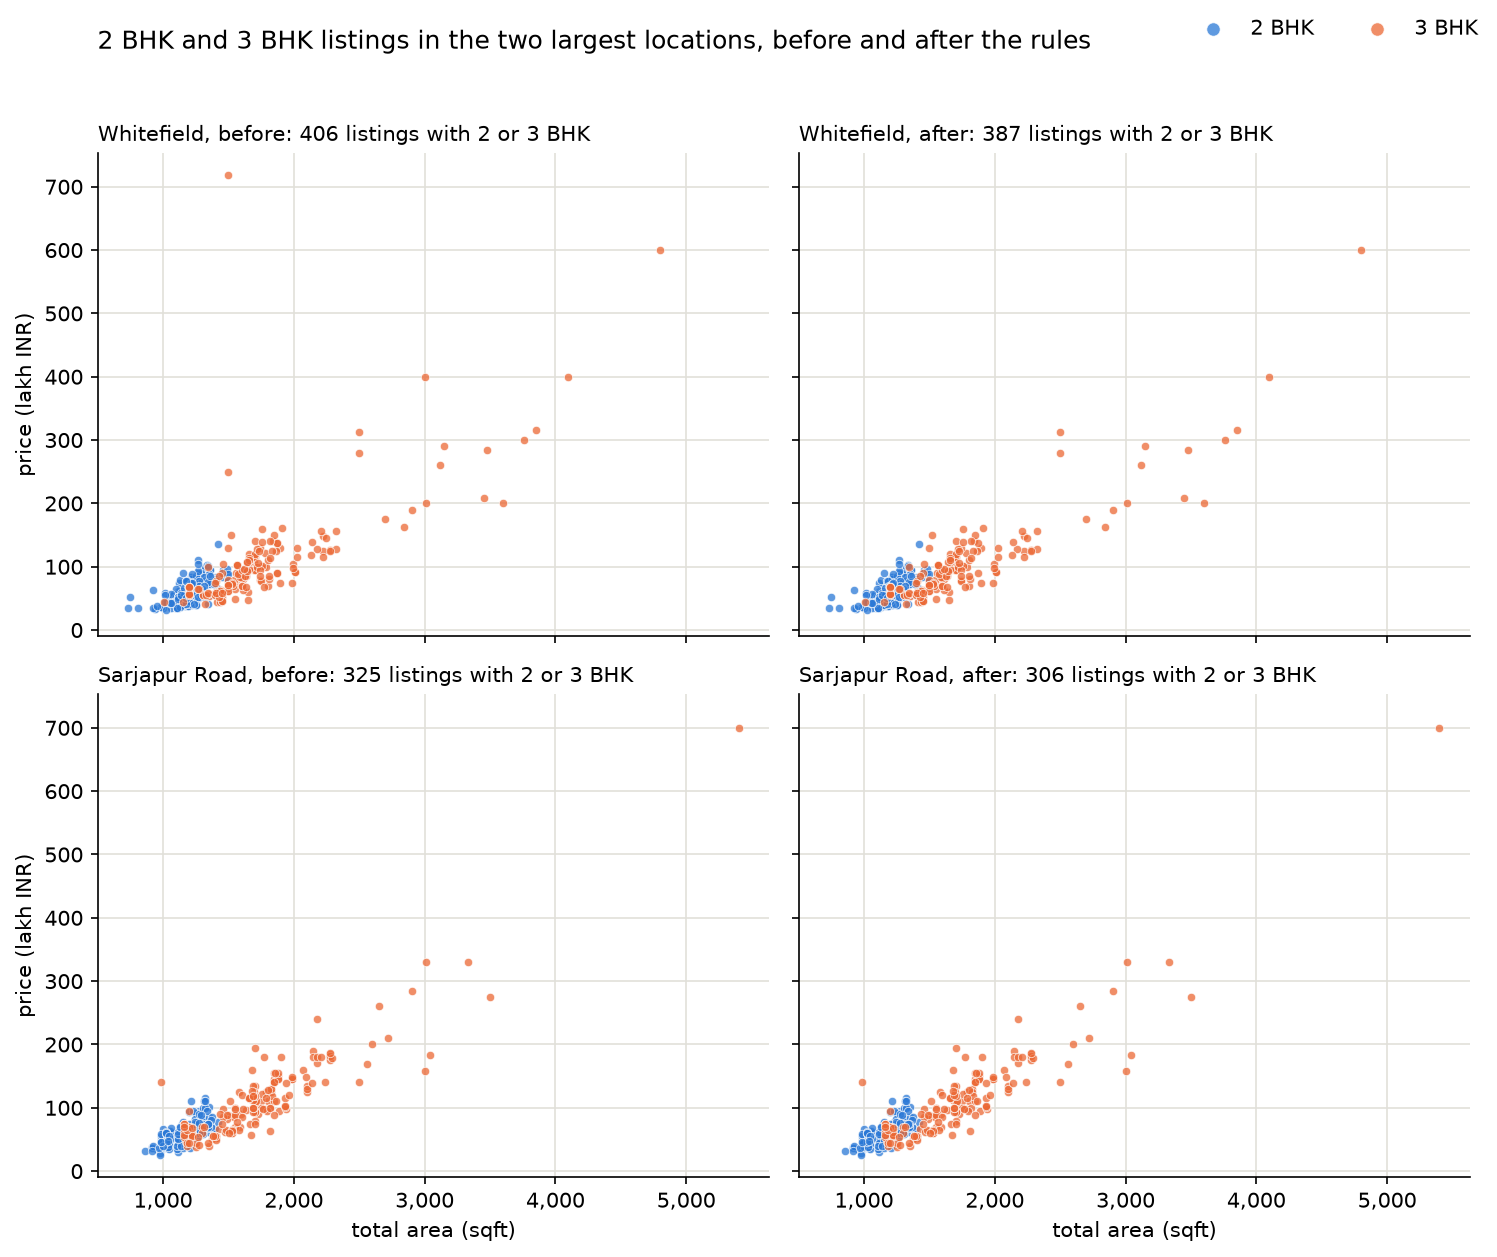

In [55]:
BLUE, ORANGE = "#2a78d6", "#eb6834"                      # categorical slots 1 and 2 of the validated palette
top_two = location_clean.value_counts().index[:2]        # the two largest locations (clean names)

# Which rule removed the 2 and 3 BHK listings that are missing from the "after" pictures, and which are the dearest of them?
rule_of = {label: rule for rule, rows in removed.items() for label in rows.index}      # row label -> the rule that removed it
for place in top_two:
    before = df3[(location_clean == place) & df3["bhk"].isin([2, 3])]
    gone = before.index.difference(df4.index)
    after = before.drop(gone)
    print(f"{place}: {len(before)} listings -> {len(after)}; removed {len(gone)}: {pd.Series([rule_of[i] for i in gone]).value_counts().to_dict()}")
    print(f"  median price_per_sqft {before['price_per_sqft'].median():,.0f} -> {after['price_per_sqft'].median():,.0f}; dearest removed:")
    display(before.loc[gone].nlargest(3, "price")[["total_sqft", "bhk", "price", "price_per_sqft"]].assign(rule=lambda t: t.index.map(rule_of)).round(0))

fig, axes = plt.subplots(2, 2, figsize=(10, 8.4), dpi=150, sharex=True, sharey=True)
for r, place in enumerate(top_two):
    for c, (when, frame) in enumerate([("before", df3), ("after", df4)]):
        ax = axes[r, c]
        in_place = frame[(location_clean.loc[frame.index] == place) & frame["bhk"].isin([2, 3])]
        for bhk, color in [(2, BLUE), (3, ORANGE)]:
            part = in_place[in_place["bhk"] == bhk]
            ax.scatter(part["total_sqft"], part["price"], s=16, color=color, alpha=0.75, edgecolor="white", linewidth=0.4, label=f"{bhk} BHK")
        ax.set_title(f"{place}, {when}: {len(in_place)} listings with 2 or 3 BHK", loc="left", fontsize=10)
        ax.grid(color="#e1e0d9", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")
        if c == 0:
            ax.set_ylabel("price (lakh INR)")
        if r == 1:
            ax.set_xlabel("total area (sqft)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, markerscale=1.6)
fig.suptitle("2 BHK and 3 BHK listings in the two largest locations, before and after the rules", x=0.07, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

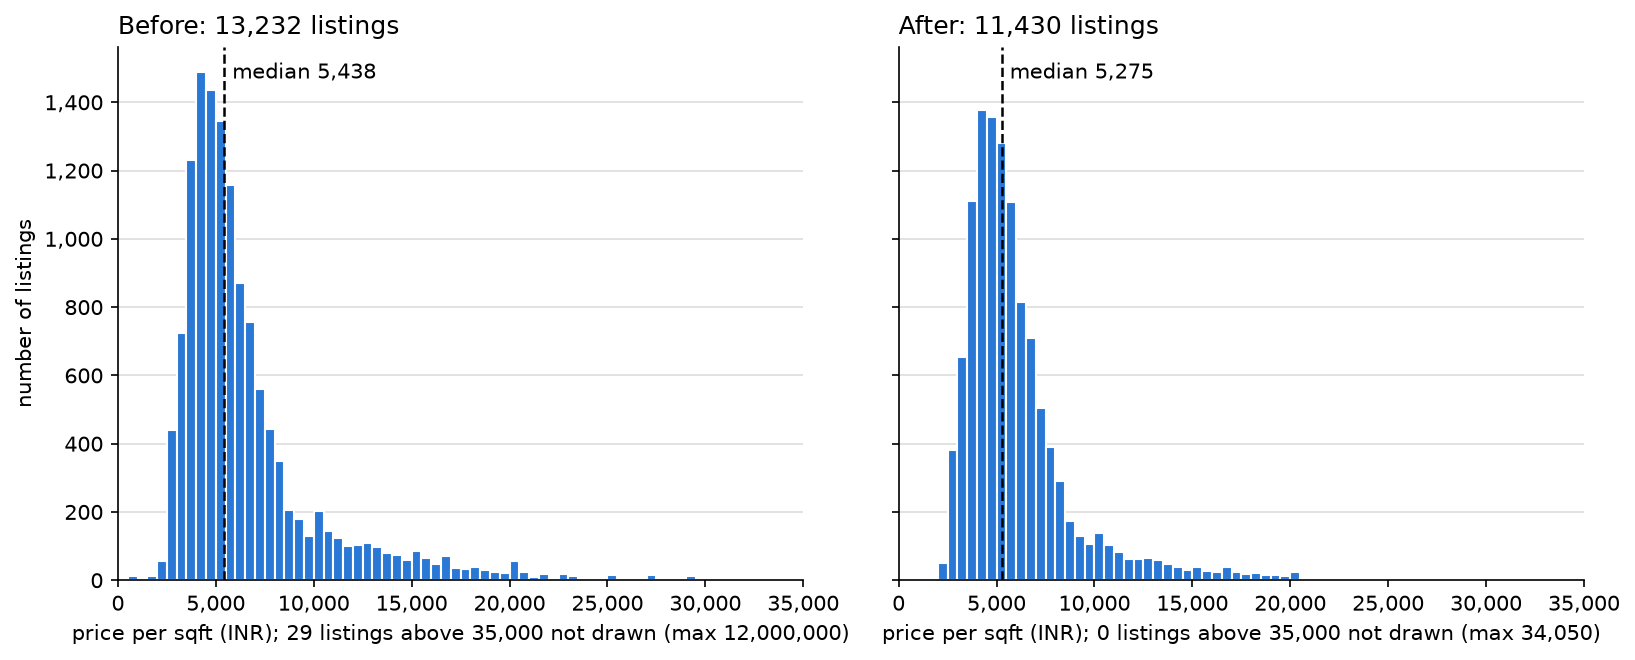

In [56]:
CAP = 35_000                                             # the Session 2 cap of 30,000 would hide the largest values left (the highest is above it); the bins stay 500 wide
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=150, sharex=True, sharey=True)
for ax, (when, frame) in zip(axes, [("Before", df3), ("After", df4)]):
    values = frame["price_per_sqft"]
    n_beyond = int((values > CAP).sum())
    ax.hist(values, bins=CAP // 500, range=(0, CAP), color="#2a78d6", edgecolor="white")
    ax.axvline(values.median(), color="black", linestyle="--", linewidth=1.2)
    ax.text(values.median() + 400, 0.97, f"median {values.median():,.0f}", va="top", transform=ax.get_xaxis_transform())
    ax.set_title(f"{when}: {len(frame):,} listings", loc="left")
    ax.set_xlabel(f"price per sqft (INR); {n_beyond} listings above {CAP:,} not drawn (max {values.max():,.0f})")
    ax.set_xlim(0, CAP)
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")
    ax.yaxis.set_major_formatter(lambda y, pos: f"{y:,.0f}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#dddddd")
    ax.set_axisbelow(True)
axes[0].set_ylabel("number of listings")
fig.tight_layout(w_pad=2.5)
plt.show()

**What the figures show**

- **Scatter.** Most of the removed 2 and 3 BHK listings are repeats (16 of 19 in Whitefield, all 19 in Sarjapur Road), which sit exactly on top of their first copy, so they are not visible. In Whitefield the log fences remove three listings: the 718 lakh one on 1,496 sqft and large homes at 400 lakh (3,000 sqft) and 250 lakh (1,500 sqft). In Sarjapur Road they remove none, and the 5,400 sqft listing at 700 lakh stays. The middle of each cloud does not move (median price per sqft 5,208 before and 5,199 after in Whitefield, 5,523 and 5,582 in Sarjapur Road) and the band from small, cheap 2 BHK homes up to large, dear 3 BHK ones is still there. The raw fences had removed more of the top: the 4,800 sqft home at 600 lakh in Whitefield and the 700 lakh home in Sarjapur Road.
- **Histogram.** The bulk is unchanged (median 5,438 before, 5,275 after) and the long right tail is mostly gone: 44 of the 46 rows above 30,000 INR per sqft (the highest 12,000,000) are removed, and 189 of the 238 above 20,000 (the highest left is 34,050). The standard deviation falls from 106,601 to 3,006. The left end is cut too: all 17 rows below 1,000 INR per sqft are removed (the lowest left is 1,667), among them the two ordinary-size homes that a rule on area would not catch (BTM Layout, 1,798 sqft at 10 lakh; Begur, 2,400 sqft at 12 lakh). The axis of this histogram stops at 35,000, not 30,000 as in Session 2, so that the highest value left is drawn.

### The final frame

Checks, then the problems the session started from, before and after.

In [57]:
assert df4.isnull().sum().sum() == 0                                        # no nulls
assert list(df4.columns) == list(df3.columns)                               # same six columns; price_per_sqft stays until Session 5
assert df4.index.is_unique and df4.index.isin(df3.index).all()
assert repeat_flag.loc[df4.index].sum() == 0                                # no repeat left
assert len(df3) - len(df4) == sum(len(rows) for rows in removed.values())   # every missing row is accounted for
print(f"Final shape: {df4.shape}")


def problems(frame):
    return {
        "rows": len(frame),
        "repeated rows (nine raw columns)": int(repeat_flag.loc[frame.index].sum()),
        "smallest total_sqft": frame["total_sqft"].min(),
        "most bedrooms (bhk)": frame["bhk"].max(),
        "rows with 10 or more bedrooms": int((frame["bhk"] >= 10).sum()),
        "dearest listing (lakh)": frame["price"].max(),
        "rows priced 300 lakh or more": int((frame["price"] >= 300).sum()),
        "price_per_sqft: min": frame["price_per_sqft"].min(),
        "price_per_sqft: max": frame["price_per_sqft"].max(),
        "price_per_sqft: standard deviation": frame["price_per_sqft"].std(),
        "price_per_sqft: mean": frame["price_per_sqft"].mean(),
        "price_per_sqft: rows below 1,000": int((frame["price_per_sqft"] < 1_000).sum()),
        "price_per_sqft: rows above 20,000": int((frame["price_per_sqft"] > 20_000).sum()),
        "price_per_sqft: rows above 30,000": int((frame["price_per_sqft"] > 30_000).sum()),
    }


display(pd.DataFrame({"Session 3 frame": problems(df3), "Session 4 frame": problems(df4)}).round(1))
df4[["total_sqft", "bath", "price", "bhk", "price_per_sqft"]].describe().round(1)

Final shape: (11430, 6)


,Session 3 frame,Session 4 frame
rows,13232.0,11430.0
repeated rows (nine raw columns),529.0,0.0
smallest total_sqft,1.0,300.0
most bedrooms (bhk),43.0,16.0
rows with 10 or more bedrooms,26.0,8.0
dearest listing (lakh),3600.0,2340.0
rows priced 300 lakh or more,779.0,563.0
price_per_sqft: min,267.8,1666.7
price_per_sqft: max,12000000.0,34050.2
price_per_sqft: standard deviation,106601.3,3006.1


,total_sqft,bath,price,bhk,price_per_sqft
count,11430.0,11430.0,11430.0,11430.0,11430.0
mean,1555.0,2.5,103.4,2.6,6044.6
std,951.2,1.0,119.5,1.0,3006.1
min,300.0,1.0,9.0,1.0,1666.7
25%,1110.0,2.0,49.0,2.0,4232.3
50%,1300.0,2.0,69.5,3.0,5274.6
75%,1692.0,3.0,110.0,3.0,6774.0
max,30400.0,16.0,2340.0,16.0,34050.2


In [58]:
categories = df4["location"].value_counts()
named = categories.drop(OTHER)
print(f"{len(categories)} categories | '{OTHER}' holds {categories[OTHER]:,} rows ({categories[OTHER] / len(df4):.1%}; "
      f"before the rules {(df3['location'] == OTHER).mean():.1%})")
print(f"named locations with {THRESHOLD} or fewer rows left: {(named <= THRESHOLD).sum()} of {len(named)}; the smallest has {named.min()}")

# Session 3 left the nine digit-glued names in place and passed the question of the bad rows among them to this session.
glued_gone = glued_rows.index.difference(df4.index)
print(f"\nof the {len(glued_rows)} digit-glued rows, {len(glued_gone)} were removed: {pd.Series([rule_of[i] for i in glued_gone]).value_counts().to_dict()}")
print("the ones that stay:")
glued_rows.loc[glued_rows.index.isin(df4.index), ["name", "bhk", "bath", "total_sqft", "price"]]

241 categories | 'other' holds 2,442 rows (21.4%; before the rules 21.7%)
named locations with 10 or fewer rows left: 36 of 240; the smallest has 5

of the 9 digit-glued rows, 8 were removed: {'fewer than 300 sqft per bedroom': 6, 'outside the pooled log fence (small locations)': 2}
the ones that stay:


,name,bhk,bath,total_sqft,price
9935,1Hoysalanagar,13,13.0,5425.0,275.0


**Result.** The frame went from 13,232 to **11,430 rows** (1,802 removed, 13.6%). It keeps its six columns and has no nulls and no repeats: 529 rows went as repeats, 746 to the domain rules (737 and 9), 447 to the location fences and 80 to the pooled fence. The brief expected roughly 11,000 to 11,500 rows.

**What is still in the frame, and what to carry into Session 5**

- **`price_per_sqft` is still there** and goes first in Session 5, since it is built from the target.
- **Both ends are cut.** The minimum `price_per_sqft` is 1,666.7 and no row is below 1,000 INR per sqft. The highest is 34,050, and 2 rows are above 30,000, both in locations with their own fences.
- **8 rows still have 10 or more bedrooms** (26 before; the most is 16). Of the 9 digit-glued rows Session 3 passed on, 8 were removed (6 by the area rule, 2 by the pooled fence); the one that stays is "1Hoysalanagar" (13 bedrooms and 13 bathrooms on 5,425 sqft).
- **Expensive homes are still under-represented**: 563 rows are priced 300 lakh or more, against 779 before (27.7% fewer).
- **`location` was not touched.** `other` now holds 2,442 rows (21.4%, against 21.7% before), and 36 of the 240 named locations have 10 or fewer rows left (the smallest has 5), because the rules removed rows after the threshold was applied. They keep their names. Session 6 tested thresholds 5 and 20 by counting listings on the 13,232 rows, as in Session 3.

## Session 5: model building and selection

**Objective.** Build leakage-safe preprocessing, compare four candidate models by cross-validation against two baselines, choose one, and evaluate it once on a held-out test set, including where it fails.

**Start.** The 11,430 × 6 frame from Session 4. A copy of this notebook as it stood at the end of Session 4b is saved next to it as `price_prediction_2026-11-04_session4b.ipynb`.

**Steps**

1. Drop `price_per_sqft`; features and target.
2. The 80/20 split, with its seed written down.
3. Two baselines, scored on the test set.
4. A Pipeline for every model, and why.
5. Cross-validation on the training set: four models, small grids, the same five folds.
6. A `log(price)` target.
7. The final model and the reason for it.
8. The final test-set evaluation (one cell).
9. Where the model fails: named locations against `other`, four price bands, one figure.
10. Three sanity predictions.

**Cautions for the whole session**

- The test rows are used in three places only: the two baselines (allowed) and, once, the final model. No choice of model, hyperparameter or feature uses them.
- Every choice is made by 5-fold cross-validation on the training rows and scored by MAE. R² is shown for reference. All models are scored on the same folds, so they can be compared fold by fold.
- No feature is built from `price` or `price_per_sqft`, and no more outliers are removed to improve a score.
- The Session 4 rules and the `other` grouping were computed on all rows before the split (see the README), so the scores below describe listings that passed those rules.

### Step 1. Features and target

Features: `location` (241 categories, `other` among them), `total_sqft`, `bath` and `bhk`. Target: `price`, in lakh. `price_per_sqft` is dropped and its absence is asserted: it is `price × 100,000 / total_sqft`, so a model that saw it would be reading the answer. The price bands are the ones used for the error breakdown in Step 9.

In [59]:
import pickle

import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import make_scorer, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

SEED = 10                                           # one seed for the split, the CV folds and the forests; any fixed value would do
BAND_EDGES = [0, 75, 150, 300, np.inf]              # price bands in lakh: under 75, 75 to 150, 150 to 300, 300 and above
BAND_LABELS = ["under 75", "75-150", "150-300", "300+"]
BLUE, ORANGE = "#2a78d6", "#eb6834"                 # the two categorical colours of the Session 4 figures
print(f"scikit-learn {sklearn.__version__}")

scikit-learn 1.9.1


In [60]:
df5 = df4.drop(columns="price_per_sqft")            # built from the target, so it must never be a model input
assert "price_per_sqft" not in df5.columns

FEATURES = ["location", "total_sqft", "bath", "bhk"]
X = df5[FEATURES]
y = df5["price"]                                    # lakh INR
band = pd.cut(y, bins=BAND_EDGES, right=False, labels=BAND_LABELS)       # a price of exactly 75 falls in "75-150"

print(f"X {X.shape}, y {y.shape}; features {list(X.columns)}")
print(f"price (lakh): min {y.min():.0f}, median {y.median():.1f}, max {y.max():,.0f}")
display(band.value_counts().sort_index().rename("rows").to_frame().T)

X (11430, 4), y (11430,); features ['location', 'total_sqft', 'bath', 'bhk']
price (lakh): min 9, median 69.5, max 2,340


price,under 75,75-150,150-300,300+
rows,6199,3410,1258,563


**What this shows.** The four bands hold 6,199, 3,410, 1,258 and 563 rows: 54% of the homes are under 75 lakh, and the 563 homes at 300 lakh or more (4.9%) reach 2,340. That thin, long top end is what the rest of the session keeps running into.

### Step 2. The 80/20 split

`train_test_split(test_size=0.2, random_state=10)`: 80% of the rows are used to fit and compare models, 20% are kept back. The seed is written down (`SEED = 10`) so that the split can be reproduced; any fixed value would do. The split is random. A split stratified on price band would give a steadier mix of expensive homes in the test set, but it is not needed here: the counts below say what the test set holds.

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
assert len(X_train) + len(X_test) == len(X) and X_train.index.intersection(X_test.index).empty      # every row on exactly one side

split = pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "other rows": [(X_train["location"] == OTHER).sum(), (X_test["location"] == OTHER).sum()],
    "300+ lakh rows": [(y_train >= 300).sum(), (y_test >= 300).sum()],
}, index=["train", "test"])
split["other share"] = (split["other rows"] / split["rows"]).map("{:.1%}".format)
split["300+ share"] = (split["300+ lakh rows"] / split["rows"]).map("{:.1%}".format)
display(split)
print("test rows by price band:", pd.cut(y_test, bins=BAND_EDGES, right=False, labels=BAND_LABELS).value_counts().sort_index().to_dict())

,rows,other rows,300+ lakh rows,other share,300+ share
train,9144,1942,440,21.2%,4.8%
test,2286,500,123,21.9%,5.4%


test rows by price band: {'under 75': 1242, '75-150': 685, '150-300': 236, '300+': 123}


**What this shows.** The split gives 9,144 training rows and **2,286 test rows**. The test set holds **500 `other` rows** (21.9%, against 21.2% of the training rows) and **123 rows priced 300 lakh or more** (5.4%, against 4.8%). Everything said later about the 300+ band rests on those 123 rows, and the 150-300 band on 236, so those numbers carry wide error bars: a handful of homes can move a band's mean error by several lakh.

### Step 3. Two baselines, scored on the test set

A model is only useful if it beats something simple. Both baselines use the training rows only and are scored on the test rows, the one use of the test set before the final model:

1. **`DummyRegressor(strategy="median")`** predicts the median training price for every home.
2. **Median INR per sqft × `total_sqft`** applies one price per sqft to every home's area. The median is computed on the training rows only.

Three metrics are used everywhere below:

- **MAE (lakh)**: the average size of the error, in the unit of the target. An error on an expensive home counts in full.
- **Median % error**: the median of |predicted − actual| / actual, the typical error relative to the home's price. A few wild rows cannot move it.
- **R²**: the share of the variation of price around its mean that the model explains. 0 is no better than always predicting the mean and a negative value is worse. It works on squared errors, so the largest prices dominate it (Step 5).

In [62]:
def median_ape(actual, predicted):
    """Median absolute percentage error, as a fraction: the typical error relative to the price of the home."""
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return float(np.median(np.abs(predicted - actual) / actual))


def metrics(actual, predicted):
    return {
        "MAE (lakh)": mean_absolute_error(actual, predicted),
        "median % error": 100 * median_ape(actual, predicted),
        "R²": r2_score(actual, predicted),
    }


dummy = DummyRegressor(strategy="median").fit(X_train, y_train)               # always the median training price
median_pps = (y_train * 100_000 / X_train["total_sqft"]).median()              # median INR per sqft of the TRAINING rows only
pps_prediction = median_pps * X_test["total_sqft"] / 100_000                    # INR back to lakh

baseline_test = pd.DataFrame({
    "DummyRegressor(median)": metrics(y_test, dummy.predict(X_test)),
    "median INR per sqft x total_sqft": metrics(y_test, pps_prediction),
}).T
print(f"the dummy predicts {y_train.median():.1f} lakh for every home (the training mean is {y_train.mean():.1f}); "
      f"the median price per sqft of the training rows is {median_pps:,.0f} INR")
display(baseline_test.round({"MAE (lakh)": 2, "median % error": 1, "R²": 3}))

the dummy predicts 69.1 lakh for every home (the training mean is 103.4); the median price per sqft of the training rows is 5,272 INR


,MAE (lakh),median % error,R²
DummyRegressor(median),54.17,38.2,-0.103
median INR per sqft x total_sqft,35.43,22.9,0.454


**What this shows.**

- **The median baseline** is wrong by 54.2 lakh on average, 38.2% for the typical home, and its R² is −0.10: slightly worse than predicting the mean. A negative R² is possible because the median (69.1 lakh) lies well below the mean (103.4 lakh) of this right-skewed target.
- **Median INR per sqft × area** (5,272 INR per sqft) is wrong by 35.4 lakh on average and 22.9% for the typical home, with R² 0.454. Knowing only the area explains close to half of the variation in price. This is the number every model has to beat.

### Step 4. A Pipeline for every model, and why

Every model is wrapped in a `Pipeline` of two steps:

1. A **`ColumnTransformer`** that one-hot encodes `location` with `OneHotEncoder(handle_unknown="ignore")` and passes `total_sqft`, `bath` and `bhk` through unchanged. The 241 locations become 241 columns of 0 and 1.
2. The **model**.

**Why a Pipeline.** The encoder learns which locations exist from the rows it is fitted on. In cross-validation it has to be fitted on the four training folds only, and the fifth fold has to be encoded with what those four taught it, exactly as a new listing will be on the website. `cross_validate` and `GridSearchCV` clone and fit the whole Pipeline on each training fold, so nothing about the validation fold, or about the test set, reaches the encoder. Encoding all the rows first and cross-validating afterwards would let the encoder see the rows that are meant to be unseen. For a one-hot encoder the leak is mild (it only decides which columns exist), but the same habit protects scalers, target encoders and imputers, where the leak is real. The Pipeline is also one object, with one `predict`, which is what the pickle file and the API will need.

**`handle_unknown="ignore"`.** A location the encoder has never seen gets all-zero columns instead of an error. It does not happen in this project's folds or test set (all 241 categories are in the training rows), but it will on the website, when someone types a place that is not in the list.

**What is not done.** The numeric columns are not scaled: trees do not need it, and the brief keeps the preprocessing to the encoder. For Lasso this means the penalty acts unevenly: a coefficient per sqft is tiny, a coefficient per location is tens of lakh. The alpha grid is chosen by cross-validation, so the effect is handled by the data; a scaler would be a variant to test, not a fix.

In [63]:
def build_pipeline(model):
    """One-hot encode `location`, let the three numeric columns through unchanged, then fit the model."""
    encode = ColumnTransformer(
        [("location", OneHotEncoder(handle_unknown="ignore"), ["location"])],
        remainder="passthrough",                    # total_sqft, bath and bhk go on as they are
    )
    return Pipeline([("encode", encode), ("model", model)])


encoded = build_pipeline(LinearRegression())[:-1].fit_transform(X_train)       # only to look at the matrix; each model fits its own copy
print(f"encoded training matrix: {encoded.shape[0]:,} rows x {encoded.shape[1]} columns ({encoded.shape[1] - 3} location columns + 3 numbers), "
      f"a sparse {type(encoded).__name__} with {encoded.nnz / (encoded.shape[0] * encoded.shape[1]):.1%} non-zero cells")

encoded training matrix: 9,144 rows x 244 columns (241 location columns + 3 numbers), a sparse csr_matrix with 1.6% non-zero cells


### Step 5. Cross-validation on the training set

Four models: `LinearRegression`, `Lasso`, `DecisionTreeRegressor` and `RandomForestRegressor`. Each has a small grid of 2 or 3 values per hyperparameter (none for linear regression), and `GridSearchCV` picks the combination with the lowest mean MAE (`neg_mean_absolute_error`). The folds are 5-fold shuffled `KFold` with the fixed seed, and one splitter object is used for every model, so every model, and both baselines, is scored on the same five folds. The tables report the mean ± the standard deviation over the five folds (the standard deviation as `scikit-learn` computes it, over the five values). The test set is not touched.

| Model | Grid |
|:--|:--|
| `LinearRegression` | none |
| `Lasso` | `alpha`: 0.01, 0.1, 1 |
| `DecisionTreeRegressor` | `max_depth`: 5, 10, 20; `min_samples_leaf`: 1, 5, 20 |
| `RandomForestRegressor` | 100 trees; `max_depth`: 10, 20, None; `min_samples_leaf`: 1, 5 |

In [64]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)      # one splitter: every model is scored on the same five folds
scoring = {
    "mae": "neg_mean_absolute_error",                         # scikit-learn maximizes scores, so an error comes back negative
    "median_pe": make_scorer(median_ape, greater_is_better=False),
    "r2": "r2",
}


def baseline_folds():
    """Both baselines on the five folds of the training set; their medians come from the other four folds only."""
    scores = {"DummyRegressor(median)": [], "median INR per sqft x total_sqft": []}
    for fit_rows, val_rows in cv.split(X_train):
        X_fit, y_fit = X_train.iloc[fit_rows], y_train.iloc[fit_rows]
        X_val, y_val = X_train.iloc[val_rows], y_train.iloc[val_rows]
        scores["DummyRegressor(median)"].append(metrics(y_val, np.full(len(y_val), y_fit.median())))
        fold_pps = (y_fit * 100_000 / X_fit["total_sqft"]).median()
        scores["median INR per sqft x total_sqft"].append(metrics(y_val, fold_pps * X_val["total_sqft"] / 100_000))
    return {name: pd.DataFrame(rows) for name, rows in scores.items()}        # name -> 5 x 3 table of fold scores


def run_search(pipe, grid):
    """Cross-validate every hyperparameter combination on the training set and keep the one with the lowest mean MAE."""
    return GridSearchCV(pipe, grid, cv=cv, scoring=scoring, refit="mae", n_jobs=-1).fit(X_train, y_train)


def fold_scores(search):
    """The five fold scores of the winning combination, in the metrics' own units."""
    i, r = search.best_index_, search.cv_results_
    return pd.DataFrame({
        "MAE (lakh)": [-r[f"split{k}_test_mae"][i] for k in range(5)],
        "median % error": [-100 * r[f"split{k}_test_median_pe"][i] for k in range(5)],
        "R²": [r[f"split{k}_test_r2"][i] for k in range(5)],
    })


candidates = {
    "LinearRegression": (build_pipeline(LinearRegression()), {}),
    "Lasso": (build_pipeline(Lasso()), {"model__alpha": [0.01, 0.1, 1.0]}),
    "DecisionTree": (build_pipeline(DecisionTreeRegressor(random_state=SEED)),
                     {"model__max_depth": [5, 10, 20], "model__min_samples_leaf": [1, 5, 20]}),
    "RandomForest": (build_pipeline(RandomForestRegressor(n_estimators=100, random_state=SEED)),
                     {"model__max_depth": [10, 20, None], "model__min_samples_leaf": [1, 5]}),
}

folds = baseline_folds()
searches = {name: run_search(pipe, grid) for name, (pipe, grid) in candidates.items()}
for name, search in searches.items():
    folds[name] = fold_scores(search)
print("done:", ", ".join(f"{name} ({len(s.cv_results_['params'])} combination(s) x 5 folds)" for name, s in searches.items()))

done: LinearRegression (1 combination(s) x 5 folds), Lasso (3 combination(s) x 5 folds), DecisionTree (9 combination(s) x 5 folds), RandomForest (6 combination(s) x 5 folds)


In [65]:
def params_text(search):
    params = {key.split("__")[-1]: value for key, value in search.best_params_.items()}
    return ", ".join(f"{key}={value}" for key, value in params.items()) or "none to tune"


def comparison_table(folds, params):
    rows = {}
    for name, f in folds.items():
        mean, sd = f.mean(), f.std(ddof=0)                    # mean and standard deviation over the five folds
        rows[name] = {
            "best hyperparameters": params.get(name, ""),
            "CV MAE (lakh)": f"{mean['MAE (lakh)']:,.2f} ± {sd['MAE (lakh)']:,.2f}",
            "CV median % error": f"{mean['median % error']:.1f} ± {sd['median % error']:.1f}",
            "CV R²": f"{mean['R²']:,.3f} ± {sd['R²']:,.3f}",
        }
    return pd.DataFrame(rows).T


best_params = {name: params_text(search) for name, search in searches.items()}
display(comparison_table(folds, best_params))

,best hyperparameters,CV MAE (lakh),CV median % error,CV R²
DummyRegressor(median),,55.29 ± 1.04,39.5 ± 0.8,-0.080 ± 0.011
median INR per sqft x total_sqft,,35.85 ± 0.71,23.4 ± 0.6,0.464 ± 0.045
LinearRegression,none to tune,31.34 ± 1.38,22.5 ± 0.4,0.703 ± 0.037
Lasso,alpha=0.01,31.09 ± 1.35,22.4 ± 0.5,0.703 ± 0.036
DecisionTree,"max_depth=20, min_samples_leaf=1",29.97 ± 0.62,18.9 ± 0.6,0.626 ± 0.057
RandomForest,"max_depth=None, min_samples_leaf=1",26.39 ± 1.22,15.2 ± 0.7,0.710 ± 0.065


In [66]:
def grid_table(search):
    """Every hyperparameter combination of a search with its CV scores, best MAE first."""
    r = pd.DataFrame(search.cv_results_)
    table = r.filter(like="param_").rename(columns=lambda c: c.split("__")[-1])
    table["CV MAE (lakh)"] = -r["mean_test_mae"]
    table["MAE sd"] = r["std_test_mae"]
    table["CV median % error"] = -100 * r["mean_test_median_pe"]
    table["CV R²"] = r["mean_test_r2"]
    return table.sort_values("CV MAE (lakh)").round(3).reset_index(drop=True)


for name in ["Lasso", "DecisionTree", "RandomForest"]:
    print(f"\n{name}: every combination, best MAE first")
    display(grid_table(searches[name]))

lasso_coef = searches["Lasso"].best_estimator_[-1].coef_
print(f"\nthe winning Lasso keeps {(lasso_coef != 0).sum()} of its {len(lasso_coef)} coefficients")


Lasso: every combination, best MAE first


,alpha,CV MAE (lakh),MAE sd,CV median % error,CV R²
0,0.01,31.089,1.349,22.351,0.703
1,0.10,31.932,1.248,23.803,0.689
2,1.00,34.221,1.185,26.540,0.630



DecisionTree: every combination, best MAE first


,max_depth,min_samples_leaf,CV MAE (lakh),MAE sd,CV median % error,CV R²
0,20,1,29.971,0.619,18.908,0.626
1,10,1,29.987,0.837,20.583,0.659
2,10,5,30.998,1.429,20.570,0.633
3,20,5,31.045,1.635,19.249,0.623
4,5,1,32.060,1.260,22.327,0.634
5,10,20,32.260,1.640,21.499,0.635
6,20,20,32.293,1.602,21.506,0.634
7,5,5,32.410,1.533,22.157,0.626
8,5,20,32.469,1.665,22.143,0.635



RandomForest: every combination, best MAE first


,max_depth,min_samples_leaf,CV MAE (lakh),MAE sd,CV median % error,CV R²
0,None,1,26.386,1.221,15.165,0.710
1,20,1,27.382,1.236,18.004,0.713
2,10,1,28.740,1.353,20.173,0.713
3,20,5,29.799,1.452,19.250,0.672
4,None,5,29.816,1.451,19.211,0.672
5,10,5,30.045,1.382,20.510,0.673



the winning Lasso keeps 179 of its 244 coefficients


In [67]:
# The same MAE fold by fold: the models are compared on identical folds, so the gap on each fold is a paired difference
per_fold = pd.DataFrame({name: f["MAE (lakh)"].to_numpy() for name, f in folds.items()}, index=[f"fold {k}" for k in range(1, 6)]).T
display(per_fold.assign(mean=per_fold.mean(axis=1)).round(2))
rivals = per_fold.drop(index="RandomForest").min()          # on each fold, the lowest MAE of any other model
lead = rivals - per_fold.loc["RandomForest"]
print(f"folds on which RandomForest has the lowest MAE: {(lead > 0).sum()} of 5; its smallest lead over the best other model on a fold: {lead.min():.2f} lakh")

lasso_lead = per_fold.loc["LinearRegression"] - per_fold.loc["Lasso"]
print(f"Lasso against LinearRegression on the five folds: {lasso_lead.round(2).tolist()} lakh (mean {lasso_lead.mean():.2f})")

# What R² is measured against: how much of the variation around the mean sits in each price band (training rows)
around_mean = (y_train - y_train.mean()) ** 2
band_train = pd.cut(y_train, bins=BAND_EDGES, right=False, labels=BAND_LABELS)
variation = pd.DataFrame({
    "share of the rows": band_train.value_counts(normalize=True).sort_index(),
    "share of the variation around the mean": around_mean.groupby(band_train, observed=True).sum() / around_mean.sum(),
})
display(variation.map("{:.1%}".format))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean
DummyRegressor(median),55.32,55.75,55.37,53.42,56.58,55.29
median INR per sqft x total_sqft,35.20,36.76,35.45,35.19,36.65,35.85
LinearRegression,33.40,30.81,30.17,29.82,32.52,31.34
Lasso,32.99,30.71,29.89,29.55,32.31,31.09
DecisionTree,29.95,30.19,28.97,29.85,30.90,29.97
RandomForest,27.08,26.17,24.84,25.51,28.32,26.39


folds on which RandomForest has the lowest MAE: 5 of 5; its smallest lead over the best other model on a fold: 2.57 lakh
Lasso against LinearRegression on the five folds: [0.4, 0.11, 0.29, 0.28, 0.21] lakh (mean 0.26)


,share of the rows,share of the variation around the mean
price,,
under 75,54.2%,11.0%
75-150,29.8%,0.8%
150-300,11.2%,8.4%
300+,4.8%,79.8%


**What this shows**

- **The forest has the lowest typical error, on every fold.** Its CV MAE is 26.39 ± 1.22 lakh, against 29.97 for the decision tree, 31.09 for Lasso, 31.34 for linear regression, 35.85 for the area baseline and 55.29 for the median baseline. It has the lowest MAE on all five folds, by at least 2.6 lakh over the best other model on that fold, about twice the fold standard deviation. Its median % error, 15.2%, is also the lowest (tree 18.9%, linear models 22.4% and 22.5%, area baseline 23.4%).
- **R² cannot separate the models, so it does not choose.** The forest's 0.710 and linear regression's 0.703 differ by far less than the fold standard deviations (0.04 to 0.07). The decision tree, whose MAE beats both linear models, has the lowest R² (0.626). The last table shows why: the homes priced 300 lakh or more are 4.8% of the training rows but hold 79.8% of the variation around the mean, which is what R² is measured against. R² is mostly a score on about 5% of the homes; MAE and median % error describe the typical listing.
- **The linear models are barely better than the area baseline in relative terms.** Their median % error (22.4% and 22.5%) is close to the baseline's 23.4%, while their MAE is 4.5 to 4.8 lakh lower, which suggests the gain is in the larger errors rather than in the typical listing.
- **Lasso against linear regression.** The lowest alpha in the grid wins (0.01) and plain linear regression, which is alpha 0, is slightly worse, so the best penalty lies near the low end of the grid; the winning Lasso keeps 179 of its 244 coefficients. It beats linear regression on every fold, by 0.26 lakh on average (0.11 to 0.40), about a fifth of the fold standard deviation (1.35 and 1.38): the two count as tied.
- **The tree.** Depth 10 and depth 20 tie on MAE (29.99 and 29.97; the grid picks depth 20 by 0.02 lakh). A single tree is 3.6 lakh behind the forest, which averages many of them.
- **The forest's best setting is the most flexible one in the grid** (no depth limit, leaves of one row). Limiting the depth costs MAE (28.74 at depth 10, 27.38 at depth 20) while R² stays at 0.71, so R² would not have told these apart.
- **A caution on the scores.** The score of a grid's winner is slightly optimistic, because the same folds picked it. With grids of 3 to 9 combinations the effect is small next to the gaps above. The unbiased number is the test score of the final model (Step 8). The last decimals also depend on the solver: `LinearRegression` on a sparse matrix is solved iteratively and stops a little short of the exact least-squares fit, and a fully grown tree depends on how ties between equal splits are visited, so another scikit-learn version, or a dense matrix, can move them. The choice of the forest does not depend on those digits (its smallest lead on a fold is 2.6 lakh).

### Step 6. A `log(price)` target

Prices are right-skewed and an error in a price tends to be proportional to it, so a common remedy is to fit `log(price)` and turn the predictions back with `exp`. `TransformedTargetRegressor` does that around a whole Pipeline, so every metric below is still in lakh. The brief asks for it on the best linear model and on the random forest. The two linear models are tied (Step 5), so both are tried. The Lasso grid is rescaled, because `log(price)` has a far smaller spread than `price`, so the same `alpha` is a much stronger penalty on it (0.0001, 0.001 and 0.01 instead of 0.01, 0.1 and 1). The forest keeps its Step 5 hyperparameters. Same folds, same metrics, training set only.

In [68]:
def with_log_target(pipe):
    """Fit on log(price) and turn the predictions back with exp, so every metric is still in lakh."""
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)


forest_params = {key.split("__")[-1]: value for key, value in searches["RandomForest"].best_params_.items()}       # the Step 5 winner
log_candidates = {
    "LinearRegression, log target": (with_log_target(build_pipeline(LinearRegression())), {}),
    "Lasso, log target": (with_log_target(build_pipeline(Lasso())), {"regressor__model__alpha": [0.0001, 0.001, 0.01]}),
    "RandomForest, log target": (with_log_target(build_pipeline(RandomForestRegressor(n_estimators=100, random_state=SEED, **forest_params))), {}),
}
log_searches = {name: run_search(pipe, grid) for name, (pipe, grid) in log_candidates.items()}

log_folds = {name: folds[name] for name in ["LinearRegression", "Lasso", "RandomForest"]}
log_params = {name: best_params[name] for name in log_folds}
for name, search in log_searches.items():
    log_folds[name] = fold_scores(search)
    log_params[name] = params_text(search)

order = ["LinearRegression", "LinearRegression, log target", "Lasso", "Lasso, log target", "RandomForest", "RandomForest, log target"]
display(comparison_table({name: log_folds[name] for name in order}, log_params))
print("\nfold by fold, LinearRegression with the log target:")
display(log_folds["LinearRegression, log target"].rename(index=lambda k: f"fold {k + 1}").round(2))

,best hyperparameters,CV MAE (lakh),CV median % error,CV R²
LinearRegression,none to tune,31.34 ± 1.38,22.5 ± 0.4,0.703 ± 0.037
"LinearRegression, log target",none to tune,360.42 ± 433.95,20.1 ± 0.4,"-35,334.842 ± 53,811.871"
Lasso,alpha=0.01,31.09 ± 1.35,22.4 ± 0.5,0.703 ± 0.036
"Lasso, log target",alpha=0.0001,399.92 ± 486.84,20.2 ± 0.4,"-44,485.996 ± 67,932.791"
RandomForest,"max_depth=None, min_samples_leaf=1",26.39 ± 1.22,15.2 ± 0.7,0.710 ± 0.065
"RandomForest, log target",none to tune,26.62 ± 0.92,15.3 ± 0.6,0.697 ± 0.039



fold by fold, LinearRegression with the log target:


,MAE (lakh),median % error,R²
fold 1,1122.83,20.48,-138912.73
fold 2,43.75,20.53,-17.85
fold 3,571.26,19.76,-37743.83
fold 4,29.91,19.84,0.61
fold 5,34.34,19.78,-0.42


In [69]:
# Why did R² fall? Out-of-fold predictions of the two linear models on the same folds, training rows only
oof = {
    "LinearRegression": cross_val_predict(build_pipeline(LinearRegression()), X_train, y_train, cv=cv),
    "LinearRegression, log target": cross_val_predict(with_log_target(build_pipeline(LinearRegression())), X_train, y_train, cv=cv),
}
area_group = pd.cut(X_train["total_sqft"], bins=[0, 1_500, 3_000, 5_000, 10_000, np.inf],
                    labels=["up to 1,500", "1,500-3,000", "3,000-5,000", "5,000-10,000", "above 10,000"])


def by_area(values):
    return values.groupby(area_group, observed=True)


for name, prediction in oof.items():
    error = pd.Series(prediction - y_train.to_numpy(), index=y_train.index)       # signed: predicted - actual, in lakh
    table = pd.DataFrame({
        "rows": by_area(error).size(),
        "mean signed error (lakh)": by_area(error).mean(),
        "MAE (lakh)": by_area(error.abs()).mean(),
        "share of the squared error": by_area(error ** 2).sum() / (error ** 2).sum(),
    })
    table["share of the squared error"] = table["share of the squared error"].map("{:.1%}".format)
    print(f"\n{name}: out-of-fold errors by total_sqft (largest prediction {prediction.max():,.0f} lakh; the single worst row holds {(error ** 2).max() / (error ** 2).sum():.1%} of the squared error)")
    display(table.round(1))

log_linear = with_log_target(build_pipeline(LinearRegression())).fit(X_train, y_train)
plain_linear = build_pipeline(LinearRegression()).fit(X_train, y_train)
log_coef = pd.Series(log_linear.regressor_[-1].coef_, index=log_linear.regressor_[:-1].get_feature_names_out())
plain_coef = pd.Series(plain_linear[-1].coef_, index=plain_linear[:-1].get_feature_names_out())
print(f"\nfitted on all training rows, the log-linear model multiplies the price by {np.exp(1_000 * log_coef['remainder__total_sqft']):.2f} "
      f"for every extra 1,000 sqft, by {np.exp(log_coef['remainder__bhk']):.2f} for every extra bedroom and by {np.exp(log_coef['remainder__bath']):.2f} "
      f"for every extra bathroom; for 30,000 extra sqft that is a factor of {np.exp(30_000 * log_coef['remainder__total_sqft']):,.0f}")
print(f"the plain linear model adds {plain_coef['remainder__total_sqft']:.3f} lakh for every extra sqft, a straight line")

log_prediction = pd.Series(oof["LinearRegression, log target"], index=y_train.index)
worst = (log_prediction - y_train).abs().nlargest(5).index
print("\nthe five worst out-of-fold predictions of the log-linear model:")
display(X_train.loc[worst].assign(actual=y_train.loc[worst], predicted=log_prediction.loc[worst].round(0)))


LinearRegression: out-of-fold errors by total_sqft (largest prediction 3,049 lakh; the single worst row holds 5.0% of the squared error)


,rows,mean signed error (lakh),MAE (lakh),share of the squared error
total_sqft,,,,
"up to 1,500",6017,-0.5,19.3,12.7%
"1,500-3,000",2577,3.3,37.1,21.7%
"3,000-5,000",477,1.9,98.8,21.6%
"5,000-10,000",63,-47.9,307.5,23.6%
"above 10,000",10,-235.5,851.7,20.4%



LinearRegression, log target: out-of-fold errors by total_sqft (largest prediction 1,954,432 lakh; the single worst row holds 79.6% of the squared error)


,rows,mean signed error (lakh),MAE (lakh),share of the squared error
total_sqft,,,,
"up to 1,500",6017,0.4,15.2,0.0%
"1,500-3,000",2577,-23.1,40.2,0.0%
"3,000-5,000",477,-40.9,130.8,0.0%
"5,000-10,000",63,580.0,819.2,0.0%
"above 10,000",10,298524.4,298711.7,100.0%



fitted on all training rows, the log-linear model multiplies the price by 1.34 for every extra 1,000 sqft, by 1.11 for every extra bedroom and by 1.13 for every extra bathroom; for 30,000 extra sqft that is a factor of 6,937
the plain linear model adds 0.095 lakh for every extra sqft, a straight line

the five worst out-of-fold predictions of the log-linear model:


,location,total_sqft,bath,bhk,actual,predicted
12987,other,30400.0,4.0,6,1824.0,1954432.0
2623,other,30000.0,4.0,4,2100.0,990751.0
3609,other,10000.0,16.0,16,550.0,21680.0
3096,other,12000.0,12.0,10,525.0,17185.0
605,Malleshwaram,12000.0,7.0,7,2200.0,14265.0


**What this shows**

- **The forest barely changes.** MAE 26.62 ± 0.92 lakh against 26.39 ± 1.22, median % error 15.3% against 15.2%, R² 0.697 against 0.710: all inside the fold standard deviations. A forest averages the prices in its leaves and has no reason to prefer the log scale, so the extra step buys nothing.
- **For the linear models the median % error improves and everything else collapses.** Linear regression goes from 22.5% to 20.1% median % error, but its MAE goes from 31 to 360 lakh and its R² from 0.70 to −35,335. The R² is below zero on four of the five folds (down to −138,913); the fourth fold, the only one that holds none of the ten training listings above 10,000 sqft, gives 0.61. Lasso behaves the same way. A mean and standard deviation of such fold scores say little: a few rows decide each fold.
- **The log model is better for small homes and worse for large ones** (the tables above). Up to 1,500 sqft (6,017 rows) its MAE is 15.2 lakh against 19.3. It under-predicts the homes of 1,500 to 5,000 sqft by 23 and 41 lakh on average (plain linear: +3 and +2). Above 5,000 sqft it over-predicts wildly: by 580 lakh on average for the 63 rows of 5,000 to 10,000 sqft, and by 298,524 lakh on average for the ten rows above 10,000.
- **The mechanism is the multiplication.** A model on `log(price)` is multiplicative: each extra 1,000 sqft multiplies the predicted price by 1.34, each bedroom by 1.11 and each bathroom by 1.13, so 30,000 extra sqft multiply it 6,937 times. The 30,400 sqft listing that sold for 1,824 lakh is predicted, out of fold, at 1,954,432 lakh. The plain linear model adds 0.095 lakh per sqft, a straight line, so its worst errors stay bounded. The exact digits of the huge numbers depend on the solver (the model is fitted iteratively on a sparse matrix); an exact least-squares fit gives the same pattern.
- **So R² fell for a real reason, not by chance.** All of the log model's squared error (100.0%, 79.6% from the single worst row) comes from the ten training rows above 10,000 sqft, and R² is measured on squared lakh. A log target moves the fit toward relative accuracy and away from accuracy in lakh. A forest does not face the trade-off: its predictions are averages of training prices, so they cannot leave the range of the training prices.
- **The usual repair is a `log(total_sqft)` feature**, so that price grows with a power of the area instead of exponentially. It is not tried: the brief fixes the four features, and it is listed in the README as an open item.
- **Outcome.** The target stays `price` in lakh. The linear models with a log target are rejected.

### Step 7. The final model

**Choice: `RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1)` on the plain price, inside the Step 4 Pipeline.** The reasons come from the cross-validation of the training set only:

1. **It has the lowest typical error, on every fold.** CV MAE 26.4 ± 1.2 lakh against 30.0 for the decision tree, 31.1 for Lasso, 31.3 for linear regression and 35.9 for the area baseline. It has the lowest MAE on all five folds, by at least 2.6 lakh. Its median % error, 15.2%, is also the lowest (the next is 18.9%).
2. **R² does not decide.** The forest's 0.710 and the linear models' 0.703 are tied, given fold standard deviations of 0.04 to 0.07, and R² is mostly a score on the 5% of homes priced 300 lakh or more (Step 5). MAE and median % error are the criteria.
3. **The target needs no transform.** `log(price)` left the forest unchanged (MAE 26.62, R² 0.697) and broke the linear models (Step 6), so the price stays in lakh and the Pipeline stays simple.
4. **Its predictions cannot run away.** A forest predicts an average of training prices, so every prediction stays inside the range of the training prices, while the log-linear model predicted over a million lakh for one listing. The other side of the same property: a forest cannot predict above what it has seen, so the dearest homes are pulled toward the average. That is the under-prediction at the top of the market that Step 9 measures.

**What it costs.** It is the least transparent of the four: there are no coefficients to read. The fitted Pipeline is 62.3 MB when pickled, which matters for the pickle export and for the repository (GitHub warns above 50 MB and refuses files above 100 MB). Each prediction runs 100 trees. Its best setting is at the edge of the grid (no depth limit, one row per leaf), so a wider grid might find a slightly better forest; the gain would be small next to its 3.6 lakh lead over the next model.

**Not chosen.** The decision tree is 3.6 lakh behind in MAE: it is the forest without the averaging. Lasso and linear regression are simple and fast, but their median % error (22%) is barely better than the area baseline's (23%).

The cell below fits the chosen forest on all 9,144 training rows. It is the same forest as the one `GridSearchCV` refitted, which the assertion confirms on training rows.

In [70]:
final_model = build_pipeline(RandomForestRegressor(n_estimators=100, random_state=SEED, **forest_params))
final_model.fit(X_train, y_train)                            # all training rows, the hyperparameters chosen in Step 5

# the same forest as the one GridSearchCV refitted (checked on training rows only)
assert np.allclose(final_model.predict(X_train.iloc[:200]), searches["RandomForest"].best_estimator_.predict(X_train.iloc[:200]))
chosen = {name: final_model[-1].get_params()[name] for name in ["n_estimators", "max_depth", "min_samples_leaf", "random_state"]}
print("final model: RandomForestRegressor with", chosen)
print(f"fitted on {len(X_train):,} rows; pickled size {len(pickle.dumps(final_model)) / 1e6:.1f} MB")

final model: RandomForestRegressor with {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'random_state': 10}
fitted on 9,144 rows; pickled size 62.3 MB


### Step 8. The final test-set evaluation

One cell, run once: the final model predicts the test rows and the result is set beside the two baselines. Nothing after this cell changes the model, its hyperparameters or its features; the next two steps only read these predictions.

In [71]:
test_prediction = final_model.predict(X_test)               # the first and only time the final model sees the test rows

final_test = pd.concat([baseline_test, pd.DataFrame({"RandomForest (final model)": metrics(y_test, test_prediction)}).T])
display(final_test.round({"MAE (lakh)": 2, "median % error": 1, "R²": 3}))

cv_mae = folds["RandomForest"]["MAE (lakh)"]
test_mae = final_test.loc["RandomForest (final model)", "MAE (lakh)"]
print(f"cross-validation expected an MAE of {cv_mae.mean():.2f} ± {cv_mae.std(ddof=0):.2f} lakh; the test set gives {test_mae:.2f}")

,MAE (lakh),median % error,R²
DummyRegressor(median),54.17,38.2,-0.103
median INR per sqft x total_sqft,35.43,22.9,0.454
RandomForest (final model),25.92,14.9,0.695


cross-validation expected an MAE of 26.39 ± 1.22 lakh; the test set gives 25.92


**What this shows**

- **The final model beats both baselines on every metric.** MAE 25.92 lakh against 35.43 for the area baseline and 54.17 for the median baseline; median % error 14.9% against 22.9% and 38.2%; R² 0.695 against 0.454 and −0.103.
- **The test score agrees with cross-validation.** The folds expected an MAE of 26.39 ± 1.22 lakh and an R² of 0.710 ± 0.065; the test set gives 25.92 and 0.695, both inside one fold standard deviation. A leak would show as a cross-validation score better than the test score; here the test score is slightly better, within the noise.
- **What it means for a listing.** The typical home is predicted within about 15% of its price (the median % error), and the average miss is 26 lakh. An R² near 0.7 is what this data supports, because a few very expensive homes dominate it (Step 5); it is not a reason to remove more outliers.

### Step 9. Where the model fails

The same test predictions, split by the kind of location (named or `other`) and by the actual price band. For each group: the number of rows, the mean actual price (for scale), the MAE, the median % error and the **mean signed error** (predicted − actual). A positive mean signed error means the model over-predicts on average and a negative one that it under-predicts, so it shows bias where the MAE shows size. The 300+ band holds only 123 test rows and the 150-300 band 236, so their numbers are rough.

In [72]:
results = pd.DataFrame({"actual": y_test, "predicted": test_prediction}, index=y_test.index)
results["error"] = results["predicted"] - results["actual"]                 # signed: positive = over-prediction
results["abs error"] = results["error"].abs()
results["% error"] = 100 * results["abs error"] / results["actual"]
results["locations"] = np.where(X_test["location"] == OTHER, "other", "named")
results["price band"] = pd.cut(results["actual"], bins=BAND_EDGES, right=False, labels=BAND_LABELS)


def breakdown(by):
    g = results.groupby(by, observed=True)
    return pd.DataFrame({
        "rows": g.size(),
        "mean actual price (lakh)": g["actual"].mean(),
        "MAE (lakh)": g["abs error"].mean(),
        "median % error": g["% error"].median(),
        "mean signed error (lakh)": g["error"].mean(),
    })


overall = pd.DataFrame({
    "rows": [len(results)],
    "mean actual price (lakh)": [results["actual"].mean()],
    "MAE (lakh)": [results["abs error"].mean()],
    "median % error": [results["% error"].median()],
    "mean signed error (lakh)": [results["error"].mean()],
}, index=["all test rows"])
error_table = pd.concat([overall, breakdown("locations"), breakdown("price band")],
                        keys=["all", "locations", "actual price band (lakh)"])
display(error_table.round({"mean actual price (lakh)": 1, "MAE (lakh)": 2, "median % error": 1, "mean signed error (lakh)": 2}))

rows  mean actual price (lakh)  \
all                      all test rows  2286                     103.3   
locations                named          1786                      96.7   
                         other           500                     126.9   
actual price band (lakh) under 75       1242                      51.0   
                         75-150          685                     101.2   
                         150-300         236                     202.7   
                         300+            123                     453.2   

                                        MAE (lakh)  median % error  \
all                      all test rows       25.92            14.9   
locations                named               19.31            12.7   
                         other               49.53            26.9   
actual price band (lakh) under 75            10.65            13.9   
                         75-150              21.93            13.1   
                         150-300             56.42            20.8   
                         300+               143.80            26.3   

                                        mean signed error (lakh)  
all                      all test rows                     -1.15  
locations                named                             -2.99  
                         other                              5.45  
actual price band (lakh) under 75                           5.26  
                         75-150                             0.22  
                         150-300                           -6.43  
                         300+                             -63.35

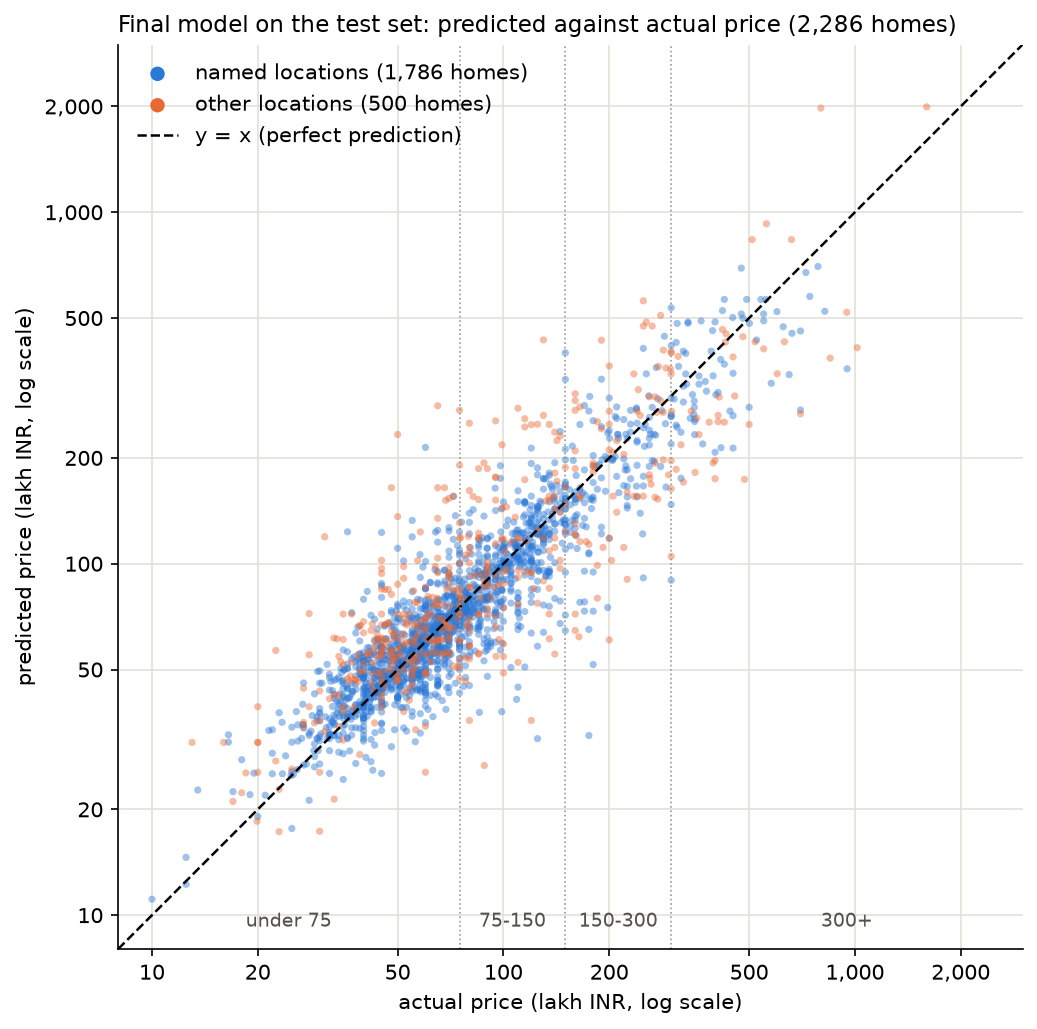

In [73]:
fig, ax = plt.subplots(figsize=(7, 7), dpi=150)
for kind, color in [("named", BLUE), ("other", ORANGE)]:
    part = results[results["locations"] == kind]
    ax.scatter(part["actual"], part["predicted"], s=12, color=color, alpha=0.45, edgecolor="none", label=f"{kind} locations ({len(part):,} homes)")

low, high = 8, 3_000
ax.plot([low, high], [low, high], color="black", linewidth=1.2, linestyle="--", label="y = x (perfect prediction)")
for edge in BAND_EDGES[1:-1]:
    ax.axvline(edge, color="#9a9990", linewidth=0.8, linestyle=":")
for left, right, label in zip([low] + BAND_EDGES[1:-1], BAND_EDGES[1:-1] + [high], BAND_LABELS):
    ax.text(np.sqrt(left * right), 0.02, label, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, color="#52514b")

ticks = [10, 20, 50, 100, 200, 500, 1_000, 2_000]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.xaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")
ax.minorticks_off()
ax.set_xlabel("actual price (lakh INR, log scale)")
ax.set_ylabel("predicted price (lakh INR, log scale)")
ax.set_title(f"Final model on the test set: predicted against actual price ({len(results):,} homes)", loc="left", fontsize=11)
ax.set_aspect("equal")
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
legend = ax.legend(frameon=False, loc="upper left", markerscale=2)
for handle in legend.legend_handles:
    handle.set_alpha(1)                                      # the points are translucent; the legend marks should not be
fig.tight_layout()
plt.show()

**What this shows**

- **`other` has about twice the error of the named locations.** Its MAE is 49.53 lakh against 19.31 (2.6 times) and its median % error 26.9% against 12.7% (2.1 times), on 21.9% of the test rows. Part of the MAE gap is scale, because `other` homes are dearer on average (127 lakh against 97), but the median % error is relative to each home's price and is still twice as high. The model also over-predicts in `other` (+5.45 lakh on average) and under-predicts in named locations (−2.99). A listing in `other` could be anywhere, so the model has no neighbourhood to learn from. Session 6 tests whether another threshold helps.
- **The bias depends on the price.** The model over-predicts the cheapest homes (+5.26 lakh under 75), is nearly unbiased at 75-150 (+0.22), under-predicts at 150-300 (−6.43) and under-predicts badly at 300+: **−63.35 lakh on average**, on homes that average 453 lakh, with an MAE of 143.80 lakh and a median % error of 26.3%. In the figure, the dearest homes sit below the line. Three things contribute. A forest predicts an average of training prices, so it cannot go above the prices it has seen and pulls the extremes toward the middle (Step 7). The Session 4 rules removed 27.7% of the listings priced 300 lakh or more, so there are fewer of them to learn from (4.8% of the training rows). And the bands are made from the actual price: grouping by the answer selects the homes that cost more than their features suggest, so any model looks like it under-predicts the top band and over-predicts the bottom one. The notebook does not separate the three.
- **A few homes carry a large part of the error.** The 123 test homes priced 300 lakh or more are 5.4% of the rows but about 30% of all the absolute error (123 × 143.80 lakh of 2,286 × 25.92), and the 500 `other` rows are 21.9% of the rows and about 42% of it. With 123 rows the band's numbers are rough, but the sign is not in doubt: the mean signed error of the 300+ band is −63 lakh.
- **Elsewhere the model is consistent.** The median % error is 13% to 14% in the two bands under 150 lakh (84% of the test rows) and 12.7% in the named locations; it rises to 20.8% at 150-300 and 26.3% at 300+.

### Step 10. Three sanity predictions

Hand-made listings, one in each kind of place: a 2 BHK of 1,200 sqft in Whitefield, a 3 BHK of 1,600 sqft on Sarjapur Road, and the same 2 BHK in `other`. The bathroom counts are the usual ones for those sizes (2, 3 and 2). For each, the first table shows the median price of the **training** listings with the same location and bedrooms and an area within 15% of the case, which is the number a prediction should land near, and the listings at exactly the same area. These listings are not the test rows. The second table shows how the prediction moves when the area changes by a little.

In [74]:
cases = pd.DataFrame([
    {"location": "Whitefield", "total_sqft": 1200.0, "bath": 2.0, "bhk": 2},
    {"location": "Sarjapur Road", "total_sqft": 1600.0, "bath": 3.0, "bhk": 3},
    {"location": OTHER, "total_sqft": 1200.0, "bath": 2.0, "bhk": 2},
])
cases["predicted price (lakh)"] = final_model.predict(cases[FEATURES]).round(1)


def similar_listings(case, tolerance):
    """Training listings with the same location and bedrooms and an area within `tolerance` of the case (0 means exactly the same area)."""
    low, high = case["total_sqft"] * (1 - tolerance), case["total_sqft"] * (1 + tolerance)
    same = (X_train["location"] == case["location"]) & (X_train["bhk"] == case["bhk"]) & X_train["total_sqft"].between(low, high)
    return y_train[same]


context = []
for case in cases.to_dict("records"):
    near, exact = similar_listings(case, 0.15), similar_listings(case, 0)
    context.append({
        "within 15% of the area: listings": len(near),
        "their median (lakh)": near.median(),
        "their middle half (lakh)": f"{near.quantile(0.25):.0f} to {near.quantile(0.75):.0f}",
        "at exactly this area: listings": len(exact),
        "their median": exact.median(),
        "their mean": exact.mean(),
    })
display(pd.concat([cases, pd.DataFrame(context)], axis=1).round(1))

# The same cases with the area moved a little: how much does the prediction change?
offsets = [-50, -1, 0, 1, 50]
nearby = {}
for case in cases.to_dict("records"):
    moved = pd.DataFrame([{**{name: case[name] for name in FEATURES}, "total_sqft": case["total_sqft"] + shift} for shift in offsets])
    nearby[f"{case['location']}, {case['bhk']} BHK, {case['total_sqft']:,.0f} sqft"] = final_model.predict(moved)
display(pd.DataFrame(nearby, index=[f"{shift:+d} sqft" for shift in offsets]).T.round(1))

,location,total_sqft,bath,bhk,predicted price (lakh),within 15% of the area: listings,their median (lakh),their middle half (lakh),at exactly this area: listings,their median,their mean
0,Whitefield,1200.0,2.0,2,48.0,156,58.0,45 to 73,10,45.8,48.1
1,Sarjapur Road,1600.0,3.0,3,103.2,69,95.0,65 to 110,2,102.5,102.5
2,other,1200.0,2.0,2,71.9,510,55.0,46 to 68,66,61.5,71.6


,-50 sqft,-1 sqft,+0 sqft,+1 sqft,+50 sqft
"Whitefield, 2 BHK, 1,200 sqft",47.8,49.4,48.0,48.8,74.5
"Sarjapur Road, 3 BHK, 1,600 sqft",90.5,103.1,103.2,103.2,105.9
"other, 2 BHK, 1,200 sqft",84.5,60.1,71.9,67.5,60.7


**What this shows**

- **Sarjapur Road lands where it should.** 103.2 lakh against a median of 95.0 for the 69 similar listings, inside their middle half (65 to 110). It is also the steadiest of the three when the area moves: 90.5 at 1,550 sqft, 103.2 at 1,600 and 105.9 at 1,650.
- **Whitefield is inside the middle half, at its low end.** 48.0 lakh against a median of 58.0 (middle half 45 to 73). In Whitefield the price climbs steeply with the area around 1,200 sqft: the model gives 48.0 at 1,200 sqft and 74.5 at 1,250, so a window of ±15% mixes cheaper and dearer listings. The 10 listings at exactly 1,200 sqft have a median of 45.8 and a mean of 48.1, which is where the prediction sits. 1,200 sqft is a heaped value (5.1% of the training rows have exactly that area; it is the size of a 30 × 40 ft site, and Session 4 found it over-represented among the rows the area rule removed), so a prediction for exactly 1,200 sqft follows the listings that report exactly 1,200.
- **`other` does not land near the median, and it is unstable.** 71.9 lakh against a median of 55.0 (middle half 46 to 68), so it is 31% above the median and above the middle half. The 66 `other` listings at exactly 1,200 sqft have a mean of 71.6, which is where the forest sits. Moving the area by a little moves the prediction a lot: 84.5 at 1,150 sqft, 60.1 at 1,199, 71.9 at 1,200, 67.5 at 1,201 and 60.7 at 1,250. A forest with no depth limit fits single listings, and `other` mixes many places, so its predictions there are noisy; this goes with its doubled error in Step 9.
- **Verdict.** Two of the three predictions are inside the middle half of comparable listings. The third, in `other`, is not, and it shows why `other` is the weak spot. Nothing is changed in response: these are sanity checks, not a basis for tuning.

### What Session 5 found

- **Final model:** a random forest (100 trees, no depth limit, one row per leaf) on the plain price. Cross-validation on the training rows gave an MAE of 26.4 ± 1.2 lakh; the test set gives an MAE of 25.9 lakh, a median % error of 14.9% and an R² of 0.695, against 35.4 lakh, 22.9% and 0.454 for the area baseline.
- **R² is the wrong yardstick for choosing here.** The 300+ lakh homes are 4.8% of the training rows and 79.8% of the variation R² is measured against. Models with very different typical errors tie on R² (a tree and a forest differ by 3.6 lakh of MAE and 0.08 of R²; the forest and linear regression differ by 5 lakh of MAE and 0.01 of R²).
- **A log target does not help.** It improves the linear models' median % error and ruins their R² and MAE, because a model of `log(price)` multiplies the price by 1.34 for every extra 1,000 sqft and explodes on the ten listings above 10,000 sqft. The forest does not change.
- **Where it fails:** `other` (MAE 49.5 lakh against 19.3 for named locations, and unstable predictions) and the dearest homes (300+ lakh: mean signed error −63 lakh, MAE 144 lakh, on 123 rows).
- **Caveats:** the scores describe listings that passed the Session 4 rules, which used the price through `price_per_sqft` and all rows; the test numbers come from one random split with one seed; the pickled forest is 62.3 MB.

## Session 6: robustness checks, predict function and export

**Objective.** Test whether three earlier choices matter beyond noise, then turn the model into artifacts that load without the notebook.

**Start.** The Session 5 final model. A copy of this notebook as it stood at the end of Session 5 is saved next to it as `price_prediction_2026-11-06_session5.ipynb`.

**Steps**

*Part A. Robustness checks*

1. Helpers: the location threshold as a function, the Session 4 rules as a function with a switch for the repeats, and one cross-validation function for the forest.
2. Five runs on the same five folds: the current setup, location thresholds 5 and 20, repeats left in, and `area_type` as a feature. One table, with a decision for each.

*Part B. The predict function and the export*

3. `model/pricing.py`: `normalize_location`, `load_artifacts`, `predict_price`.
4. Refit the final configuration on all 11,430 rows and compare its sanity predictions with the Session 5 model.
5. Export `house_price_model.pkl`, `locations.json` and `metadata.json` to `model/artifacts/`.
6. Tests, written as plain asserts.
7. One prediction from a fresh Python process.

**Cautions for the whole session**

- The test set is not used for any decision. Part A is cross-validation on the training rows, with the forest settings of Session 5 and the same five folds. The only test-set numbers in the artifacts are the Session 5 ones, labeled as coming from the model fit on 80% of the rows.
- **The decision rule was fixed before the runs:** a setting changes only if it lowers the mean CV MAE by at least 1 lakh **and** wins on at least 4 of the 5 folds. The repeats run uses different rows, so it is a diagnostic, not a selection: repeats stay removed whatever it shows.
- A pickle runs code when it is loaded, so `house_price_model.pkl` must only be loaded from a source you trust, and only with the scikit-learn version recorded in `metadata.json`.

## Part A. Robustness checks

### Step 1. Helpers

- `grouped_location(threshold)` rebuilds the `location` column for another threshold, counting listings per cleaned name on the 13,232 rows of Session 3, exactly as before. Threshold 10 must reproduce Session 3, and the cell asserts it.
- `clean_rows(frame, remove_repeats)` is the four Session 4 rules in one function: repeats, then the two domain rules, then the per-location fences and the pooled fence (both measured on the rows left after the domain rules). With the repeats removed it must give back the 11,430 rows of the final frame, and the cell asserts that too. With `remove_repeats=False` it is the only change: the fences are measured on the rows that are then present.
- `forest_cv(...)` cross-validates the Session 5 forest (100 trees, no depth limit, one row per leaf, `random_state=10`) inside the same kind of Pipeline, on the same `KFold` object as Session 5, and returns the five fold MAEs.

In [75]:
from sklearn.model_selection import cross_validate


def grouped_location(threshold):
    """The `location` column for a threshold: names with `threshold` or fewer listings become `other`.
    Listings are counted per cleaned name on the 13,232 rows of Session 3, as in Session 3."""
    listings = location_clean.map(location_clean.value_counts())
    return location_clean.where(listings > threshold, OTHER)


assert (grouped_location(10) == df3["location"]).all()           # threshold 10 is the Session 3 result


def clean_rows(frame, remove_repeats=True):
    """The four Session 4 rules. Returns the rows that are kept, in their original order."""
    kept = frame
    if remove_repeats:                                           # rule 1
        kept = kept[~is_repeat.loc[kept.index]]
    kept = kept[~((kept["total_sqft"] / kept["bhk"] < 300) | (kept["bath"] > kept["bhk"] + 2))]      # rule 2
    fences = location_fences(kept, location_clean, log=True)     # rules 3 and 4, both measured on the rows left after rule 2
    price_sqft = kept["price_per_sqft"]
    flag_location = fences["tested"] & ((price_sqft < fences["lower"]) | (price_sqft > fences["upper"]))
    small = ~fences["tested"]
    pool_lower, pool_upper = iqr_fences(price_sqft[small], log=True)
    flag_pooled = small & ((price_sqft < pool_lower) | (price_sqft > pool_upper))
    return kept[~(flag_location | flag_pooled)]


assert clean_rows(df3).index.equals(df4.index)                   # with the repeats removed, the 11,430 rows of Session 4


def forest_cv(X_fit, y_fit, categorical):
    """Five fold MAEs (lakh) of the Session 5 forest on the same folds as Session 5; `categorical` columns are one-hot encoded."""
    encode = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), categorical)], remainder="passthrough")
    forest = RandomForestRegressor(n_estimators=100, random_state=SEED, **forest_params)
    scores = cross_validate(Pipeline([("encode", encode), ("model", forest)]), X_fit, y_fit, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    return -scores["test_score"]

### Step 2. Five runs, one table

- **Current**: the Session 5 setup. Its fold MAEs must equal the Session 5 ones (asserted), which shows that this helper and the Session 5 Pipeline are the same thing.
- **Threshold 5 and threshold 20**: only the `location` column changes. The rows and the training rows are the Session 5 ones, so the folds are identical and the comparison is paired.
- **`area_type`**: reloaded from the raw CSV by row label and one-hot encoded next to `location`. Same rows, same folds.
- **Repeats left in**: rule 1 is switched off and nothing else, so the frame has more rows and the 80% training split is a different set of rows. Its folds cannot be paired with the others. Copies of one listing can sit in the training part and the validation part of a fold, so a lower MAE is expected: it measures the leak.

"Folds won" counts the folds where the variant's MAE is below the current setup's on the same fold.

In [76]:
def run_variant(features, target, categorical, same_rows=True):
    """Cross-validate one variant on its training rows. The test part of the data is not used."""
    if same_rows:
        X_fit, y_fit = features.loc[X_train.index], target.loc[X_train.index]                           # the Session 5 training rows
    else:
        X_fit, _, y_fit, _ = train_test_split(features, target, test_size=0.2, random_state=SEED)       # the 20% part is thrown away unused
    return {"rows": len(features), "categories": features["location"].nunique(),
            "in other": (features["location"] == OTHER).mean(), "fold MAEs": forest_cv(X_fit, y_fit, categorical)}


repeats_kept = clean_rows(df3, remove_repeats=False)
runs = {
    "current (threshold 10)": run_variant(X, y, ["location"]),
    "threshold 5": run_variant(X.assign(location=grouped_location(5).loc[X.index]), y, ["location"]),
    "threshold 20": run_variant(X.assign(location=grouped_location(20).loc[X.index]), y, ["location"]),
    "area_type added": run_variant(X.assign(area_type=df_raw.loc[X.index, "area_type"]), y, ["location", "area_type"]),
    "repeats left in (diagnostic)": run_variant(repeats_kept[FEATURES], repeats_kept["price"], ["location"], same_rows=False),
}

current = runs["current (threshold 10)"]["fold MAEs"]
assert np.allclose(current, folds["RandomForest"]["MAE (lakh)"])                 # the Session 5 fold scores of the winning forest

table = []
for name, run in runs.items():
    maes = run["fold MAEs"]
    paired = name != "repeats left in (diagnostic)"
    gain = current.mean() - maes.mean()                                           # positive = the variant is better
    wins = int((maes < current).sum())
    if name.startswith("current"):
        decision = "baseline"
    elif not paired:
        decision = "diagnostic only: repeats stay removed"
    else:
        decision = "adopt" if gain >= 1 and wins >= 4 else "keep the current setup"
    table.append({
        "variant": name, "rows": f"{run['rows']:,}", "categories": run["categories"], "rows in other": f"{run['in other']:.1%}",
        "CV MAE ± std (lakh)": f"{maes.mean():.2f} ± {maes.std(ddof=0):.2f}",
        "lower than current by": f"{gain:+.2f}" if not name.startswith("current") else "",
        "folds won": f"{wins} of 5" if paired and not name.startswith("current") else "",
        "decision": decision,
    })
robustness = pd.DataFrame(table).set_index("variant")
display(robustness)

print("\nMAE (lakh) on each fold:")
display(pd.DataFrame({name: run["fold MAEs"] for name, run in runs.items()}, index=[f"fold {k}" for k in range(1, 6)]).T.round(2))

,rows,categories,rows in other,CV MAE ± std (lakh),lower than current by,folds won,decision
variant,,,,,,,
current (threshold 10),"11,430",241,21.4%,26.39 ± 1.22,,,baseline
threshold 5,"11,430",387,13.1%,25.62 ± 1.03,+0.77,4 of 5,keep the current setup
threshold 20,"11,430",144,31.5%,27.65 ± 1.29,-1.27,0 of 5,keep the current setup
area_type added,"11,430",241,21.4%,25.96 ± 1.37,+0.43,5 of 5,keep the current setup
repeats left in (diagnostic),"11,878",241,20.7%,25.30 ± 1.32,+1.09,,diagnostic only: repeats stay removed



MAE (lakh) on each fold:


,fold 1,fold 2,fold 3,fold 4,fold 5
current (threshold 10),27.08,26.17,24.84,25.51,28.32
threshold 5,26.24,25.22,25.06,24.29,27.27
threshold 20,29.06,27.58,26.66,25.85,29.12
area_type added,26.98,25.65,24.27,24.88,28.02
repeats left in (diagnostic),26.00,23.57,27.12,24.00,25.79


**What this shows**

- **The current setup reproduces Session 5:** CV MAE 26.39 ± 1.22 lakh, fold by fold.
- **Threshold 5 is better by 0.77 lakh and wins on 4 of the 5 folds, but not by the 1 lakh the rule asks for.** It keeps 387 categories instead of 241 and moves 13.1% of the rows to `other` instead of 21.4%. The direction is consistent, so a smaller threshold is worth remembering, but a gain of 0.77 lakh is under the fold standard deviation of about 1.2 and the rule was fixed in advance. The threshold stays at 10.
- **Threshold 20 is worse by 1.27 lakh and wins on none of the folds.** It keeps 144 categories and moves 31.5% of the rows to `other`, so a third of the listings lose their location. The threshold stays at 10.
- **`area_type` helps by 0.43 lakh and wins on all 5 folds, again below the rule.** The gain is small and consistent, but adopting it would add an input to the API and to the website for less than half a lakh. It is not added.
- **Leaving the repeats in lowers the MAE by about 1.1 lakh (25.30 ± 1.32 on 11,878 rows), and that is the leak:** copies of one listing are in the training part and the validation part of a fold, so the model is scored on homes it has seen. This run is a diagnostic: the repeats stay removed. It also shows how large the optimism of an unnoticed repeat is next to the gaps between the variants above.
- **No setting changes.** The final configuration is the Session 5 one: threshold 10, no `area_type`, repeats removed, a forest of 100 trees with no depth limit and one row per leaf.

## Part B. The predict function and the export

### Step 3. `model/pricing.py`

The logic that the API needs lives in a module, not in the notebook. It has three functions:

- **`normalize_location(name)`** collapses runs of whitespace to one space and removes trailing commas and periods, keeping the capitalisation. It is the cleaning of Session 3, and the notebook now imports it, so the notebook and the API clean a name in the same way (the cell in Session 3 asserts that it gives what the inline code gave, and Session 4 uses it too).
- **`load_artifacts()`** reads `house_price_model.pkl`, `locations.json` and `metadata.json` once, and warns if the installed scikit-learn is not the one the model was fitted with.
- **`predict_price(location, total_sqft, bath, bhk)`** checks the inputs with the cleaning rules (below), looks the location up by its casefolded normalized name (an unknown name becomes `other`), and returns the price in lakh rounded to one decimal, the location used, and whether it is `named` or `other`.

The checks raise `ValueError` with a readable message, so Session 7 can turn them into an HTTP 422. They reject what the Session 4 rules would have removed (fewer than 300 sqft per bedroom, more than `bhk + 2` bathrooms), a `bhk` below 1, a `bath` below 1, values that are not whole numbers or not numbers, and a `total_sqft` outside the range of the training data. The model only saw homes that passed those rules, so a price for one that would not pass them is a guess.

The limits are read from `metadata.json`, so they come from the data. The file is printed below.

In [77]:
from pathlib import Path

print(Path("pricing.py").read_text(encoding="utf-8"))

"""Price prediction for a Bengaluru listing (Session 6).

Three things that the notebook and the API (Session 7) share:

    normalize_location(name)                          clean a raw or typed location name
    load_artifacts()                                  load the model, the location list and the metadata
    predict_price(location, total_sqft, bath, bhk)    check the inputs, return the price in lakh INR

The files are read from model/artifacts/, which the notebook writes at the end of Session 6.
A pickle runs code when it is loaded: load house_price_model.pkl only from a source you trust,
and only with the scikit-learn version recorded in metadata.json.

    from pricing import predict_price
    predict_price("Whitefield", 1200, 2, 2)
"""
import json
import math
import warnings
from pathlib import Path

import joblib
import pandas as pd

ARTIFACTS = Path(__file__).resolve().parent / "artifacts"
OTHER = "other"
_loaded = {}                      # artifacts already read from dis

### Step 4. Refit on all rows

The configuration is final (Part A changed nothing), so it is refitted on all 11,430 rows. That is the model the API will use: it has seen the 20% that Session 5 held out, which is 25% more data than the model that was tested. The cost is that **it has no held-out score of its own**: the test numbers belong to the model fitted on 80% of the rows, and the artifacts say so. The two models should predict much alike, and the cell shows the three sanity inputs for both.

In [78]:
deploy_model = build_pipeline(RandomForestRegressor(n_estimators=100, random_state=SEED, **forest_params))
deploy_model.fit(X, y)                                                  # all 11,430 rows, the Session 5 hyperparameters
assert len(X) == 11_430

sanity_inputs = pd.DataFrame([
    {"location": "Whitefield", "total_sqft": 1200.0, "bath": 2.0, "bhk": 2},
    {"location": "Sarjapur Road", "total_sqft": 1600.0, "bath": 3.0, "bhk": 3},
    {"location": OTHER, "total_sqft": 1200.0, "bath": 2.0, "bhk": 2},
])
display(sanity_inputs.assign(**{
    "fit on 80% (Session 5)": final_model.predict(sanity_inputs).round(1),
    "fit on all rows": deploy_model.predict(sanity_inputs).round(1),
}))

,location,total_sqft,bath,bhk,fit on 80% (Session 5),fit on all rows
0,Whitefield,1200.0,2.0,2,48.0,48.0
1,Sarjapur Road,1600.0,3.0,3,103.2,97.4
2,other,1200.0,2.0,2,71.9,73.0


### Step 5. Export

Three files in `model/artifacts/`:

- **`house_price_model.pkl`**, written with `joblib.dump(..., compress=3)`. Compression changes the file and not the model; the next step proves that the predictions are identical.
- **`locations.json`**: the 240 display names plus `other`, and a mapping from the normalized, casefolded name to the display name, which is what `predict_price` looks names up in.
- **`metadata.json`**: library versions, date, seed, rows, feature names, the validation limits, the location threshold, and the Session 5 metrics, labeled as coming from the model fitted on 80% of the rows. It carries the typical error for named locations and for `other`, because predictions in `other` are about twice as uncertain as the named ones.

In [79]:
import datetime
import json
import pickle
import platform

import joblib
import sklearn

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

# 1. the model
joblib.dump(deploy_model, ARTIFACT_DIR / "house_price_model.pkl", compress=3)

# 2. the locations: display names and the normalized (casefolded) key of each
named = sorted(set(X["location"]) - {OTHER})
key_to_name = {name.casefold(): name for name in named}
assert len(named) == 240 and len(key_to_name) == 240                    # every display name has its own key
assert all(normalize_location(name) == name for name in named)         # the names are already normalized
locations = {"display_names": named + [OTHER], "key_to_name": key_to_name}
(ARTIFACT_DIR / "locations.json").write_text(json.dumps(locations, indent=1, ensure_ascii=False), encoding="utf-8")

# 3. the metadata
session5 = final_test.loc["RandomForest (final model)"]
metadata = {
    "created": datetime.date.today().isoformat(),
    "model": "Pipeline: one-hot encoded location + total_sqft, bath, bhk -> RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1)",
    "target": "price, in lakh INR",
    "seed": SEED,
    "rows_fitted": len(X),
    "features": FEATURES,
    "location_threshold": 10,
    "named_locations": len(named),
    "libraries": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                  "numpy": np.__version__, "joblib": joblib.__version__},
    "validation": {
        "min_bhk": 1, "min_bath": int(X["bath"].min()),
        "min_sqft_per_bedroom": 300, "max_baths_over_bhk": 2,
        "min_total_sqft": float(X["total_sqft"].min()), "max_total_sqft": float(X["total_sqft"].max()),
    },
    "metrics_from_the_model_fit_on_80_percent_of_rows": {
        "test_rows": len(X_test),
        "test_mae_lakh": round(float(session5["MAE (lakh)"]), 2),
        "test_median_percentage_error": round(float(session5["median % error"]), 1),
        "test_r2": round(float(session5["R²"]), 3),
        "cv_mae_lakh_mean": round(float(current.mean()), 2),
        "cv_mae_lakh_std": round(float(current.std(ddof=0)), 2),
        "typical_error_percent": {
            "named": round(float(error_table.loc[("locations", "named"), "median % error"]), 1),
            "other": round(float(error_table.loc[("locations", "other"), "median % error"]), 1),
        },
    },
    "notes": [
        "Predictions for locations in 'other' are about twice as uncertain as for named locations.",
        "The model was trained only on listings that passed the Session 4 cleaning rules; predict_price rejects inputs those rules would remove.",
        "The model underestimates the most expensive homes (300 lakh and above).",
        "Load the pickle only with the scikit-learn version above, and only from a source you trust: a pickle runs code when it is loaded.",
    ],
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=1), encoding="utf-8")

sizes = {path.name: path.stat().st_size / 1e6 for path in sorted(ARTIFACT_DIR.iterdir())}
plain_mb = len(pickle.dumps(deploy_model)) / 1e6
print(f"plain pickle: {plain_mb:.1f} MB; with joblib compress=3: {sizes['house_price_model.pkl']:.1f} MB")
print({name: round(size, 3) for name, size in sizes.items()}, f"| total {sum(sizes.values()):.1f} MB")
assert sum(sizes.values()) < 50

print("\nmetadata.json (without the date):")
print(json.dumps({k: v for k, v in metadata.items() if k != "created"}, indent=1))

plain pickle: 75.1 MB; with joblib compress=3: 16.1 MB
{'house_price_model.pkl': 16.138, 'locations.json': 0.013, 'metadata.json': 0.001} | total 16.2 MB

metadata.json (without the date):
{
 "model": "Pipeline: one-hot encoded location + total_sqft, bath, bhk -> RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1)",
 "target": "price, in lakh INR",
 "seed": 10,
 "rows_fitted": 11430,
 "features": [
  "location",
  "total_sqft",
  "bath",
  "bhk"
 ],
 "location_threshold": 10,
 "named_locations": 240,
 "libraries": {
  "python": "3.13.18",
  "scikit-learn": "1.9.1",
  "pandas": "3.1.0",
  "numpy": "2.5.4",
  "joblib": "1.6.0"
 },
 "validation": {
  "min_bhk": 1,
  "min_bath": 1,
  "min_sqft_per_bedroom": 300,
  "max_baths_over_bhk": 2,
  "min_total_sqft": 300.0,
  "max_total_sqft": 30400.0
 },
 "metrics_from_the_model_fit_on_80_percent_of_rows": {
  "test_rows": 2286,
  "test_mae_lakh": 25.92,
  "test_median_percentage_error": 14.9,
  "test_r2": 0.695,
  "cv_mae_

### Step 6. Tests

Plain asserts, no test framework. The cell stops at the first failure.

1. The reloaded model gives the same predictions as the one in memory, on every row.
2. `predict_price` returns what the model returns, and a name with extra spaces, a trailing comma or other capitalisation is the same place.
3. The three sanity inputs give plausible values. "Plausible" was fixed before looking: between the 10th and 90th percentile of the listings with the same location group and bedrooms and an area within 15% (the listings of all 11,430 rows, because the deployed model has seen them all).
4. A 500 sqft 3 BHK and a 1 BHK with 4 bathrooms are rejected, and so are a few other bad inputs; the messages are printed.
5. An unknown location falls back to `other`.

In [80]:
import pricing
from pricing import normalize_location, predict_price

pricing._loaded.clear()                                                  # forget anything loaded before this export

# 1. the reloaded model = the model in memory
reloaded = joblib.load(ARTIFACT_DIR / "house_price_model.pkl")
assert np.array_equal(reloaded.predict(X), deploy_model.predict(X))
print(f"1. reloaded model = in-memory model on all {len(X):,} rows")

# 2. predict_price returns what the model returns; spelling variants are one place
one_row = pd.DataFrame([{"location": "Whitefield", "total_sqft": 1200.0, "bath": 2.0, "bhk": 2}])
assert predict_price("Whitefield", 1200, 2, 2)["price_lakh"] == round(float(deploy_model.predict(one_row)[0]), 1)
assert normalize_location("Whitefield ") == "Whitefield"
assert normalize_location("  Sarjapur   Road, ") == "Sarjapur Road"
assert predict_price("Whitefield  ", 1200, 2, 2) == predict_price("Whitefield", 1200, 2, 2)
assert predict_price("whitefield,", 1200, 2, 2)["location"] == "Whitefield"
print("2. predict_price = model.predict; 'Whitefield ' and 'whitefield,' are Whitefield")

# 3. the three sanity inputs are plausible
rows = []
for name, (location, sqft, bath, bhk) in {"Whitefield": ("Whitefield", 1200, 2, 2), "Sarjapur Road": ("Sarjapur Road", 1600, 3, 3),
                                          "other (an unlisted place)": ("Nowhere Layout", 1200, 2, 2)}.items():
    result = predict_price(location, sqft, bath, bhk)
    group = result["location"]                                           # the named location, or "other"
    near = y[(X["location"] == group) & (X["bhk"] == bhk) & X["total_sqft"].between(sqft * 0.85, sqft * 1.15)]
    low, median, high = near.quantile([0.10, 0.50, 0.90])
    assert low <= result["price_lakh"] <= high, (name, result, low, high)
    rows.append({"input": name, "predicted (lakh)": result["price_lakh"], "type": result["location_type"], "similar listings": len(near),
                 "10th percentile": round(low, 1), "median": round(median, 1), "90th percentile": round(high, 1)})
print("3. all three predictions are inside the 10th to 90th percentile of similar listings:")
display(pd.DataFrame(rows).set_index("input"))


# 4. bad inputs are rejected with a readable message
def rejected(*args):
    try:
        predict_price(*args)
    except ValueError as error:
        return str(error)
    raise AssertionError(f"{args} was not rejected")


bad_inputs = {
    "500 sqft, 3 BHK": ("Whitefield", 500, 3, 3),
    "1 BHK with 4 baths": ("Whitefield", 600, 4, 1),
    "0 BHK": ("Whitefield", 1200, 1, 0),
    "100 sqft": ("Whitefield", 100, 1, 1),
    "sqft is not a number": ("Whitefield", "abc", 2, 2),
    "empty location": ("  ", 1200, 2, 2),
}
print("4. rejected inputs:")
for name, args in bad_inputs.items():
    print(f"   {name}: {rejected(*args)}")

# 5. an unknown location falls back to other
fallback = predict_price("Nowhere Layout", 1200, 2, 2)
assert fallback["location_type"] == "other" and fallback["location"] == OTHER
assert predict_price("Whitefield", 1200, 2, 2)["location_type"] == "named"
print("5. 'Nowhere Layout' ->", fallback)
print("\nall tests passed")

1. reloaded model = in-memory model on all 11,430 rows


2. predict_price = model.predict; 'Whitefield ' and 'whitefield,' are Whitefield
3. all three predictions are inside the 10th to 90th percentile of similar listings:


,predicted (lakh),type,similar listings,10th percentile,median,90th percentile
input,,,,,,
Whitefield,48.0,named,197,39.6,58.0,84.0
Sarjapur Road,97.4,named,85,56.4,95.0,125.0
other (an unlisted place),73.0,other,650,39.0,55.0,90.0


4. rejected inputs:
   500 sqft, 3 BHK: a 3 BHK needs at least 900 sqft (300 sqft per bedroom), got 500
   1 BHK with 4 baths: bath can be at most bhk + 2, which is 3 for a 1 BHK, got 4
   0 BHK: bhk must be a whole number of at least 1, got 0
   100 sqft: total_sqft must be between 300 and 30,400 sqft, the range of the training data, got 100
   sqft is not a number: total_sqft must be a number, got 'abc'
   empty location: location must not be empty
5. 'Nowhere Layout' -> {'price_lakh': 73.0, 'location': 'other', 'location_type': 'other'}

all tests passed


### Step 7. A prediction from a fresh Python process

A new interpreter, not the notebook's kernel, runs `from pricing import predict_price` and one prediction. If this works, the API can use the module without the notebook.

In [81]:
import subprocess
import sys

fresh = subprocess.run(
    [sys.executable, "-c", "import json; from pricing import predict_price; print(json.dumps(predict_price('Whitefield', 1200, 2, 2)))"],
    capture_output=True, text=True, cwd=".",
)
print("exit code:", fresh.returncode, "| output:", fresh.stdout.strip(), "| errors:", fresh.stderr.strip() or "none")
assert fresh.returncode == 0 and json.loads(fresh.stdout) == predict_price("Whitefield", 1200, 2, 2)

exit code: 0 | output: {"price_lakh": 48.0, "location": "Whitefield", "location_type": "named"} | errors: none


### What Session 6 found

- **No setting changes.** Location threshold 10, repeats removed and no `area_type` stay. Threshold 5 (−0.77 lakh, 4 of 5 folds) and `area_type` (−0.43 lakh, 5 of 5 folds) each helped a little, consistently, but by less than the 1 lakh the rule asked for, so they are recorded and not adopted. Threshold 20 was worse by 1.27 lakh.
- **Repeats are a leak worth about 1.1 lakh of MAE.** Left in, they make the model look better than it is.
- **The final model is the Session 5 configuration refitted on all 11,430 rows.** It is exported with `joblib.dump(..., compress=3)`: the plain pickle is 75.1 MB (the model fitted on 80% of the rows was 62.3 MB) and the compressed file is 16.1 MB, about a fifth, with identical predictions. The three artifacts together are 16.2 MB, under the 50 MB limit.
- **The refit moves the sanity predictions a little.** Whitefield stays at 48.0 lakh, the unlisted place goes from 71.9 to 73.0 and Sarjapur Road from 103.2 to 97.4 (5.6% lower, nearer the median of 95 for similar listings). A single listing can move a forest's prediction in a small location, which is part of the typical error of 12.7% for named locations.
- **`predict_price` works from a fresh process and rejects bad inputs.** Its checks come from the Session 4 cleaning rules.
- **The metrics in `metadata.json` belong to the model fitted on 80% of the rows.** The deployed model has no held-out score of its own. The metadata also says that predictions in `other` are about twice as uncertain (typical error 26.9% against 12.7%).

## Decision log (Sessions 1 to 6)

Each decision with its row impact, as seen while the notebook ran on this data.

| # | Session | Decision | Why | Rows before | Rows after | Rows removed |
|--:|:-------:|----------|-----|------------:|-----------:|-------------:|
| 1 | 1 | Drop `area_type` | Judgment call: changes what `total_sqft` measures; tested in Session 6 (row 38): not added | 13,320 | 13,320 | 0 |
| 2 | 1 | Drop `availability` | Possession label/month, not a property attribute | 13,320 | 13,320 | 0 |
| 3 | 1 | Drop `society` | Large share missing and very high-cardinality | 13,320 | 13,320 | 0 |
| 4 | 1 | Drop `balcony` | Minor amenity count; avoids imputing | 13,320 | 13,320 | 0 |
| 5 | 1 | Drop rows with a null in `location`, `size` or `bath` | `location` has no sensible fill value; `bath` is tied to bedroom count (`size`), so imputing would invent data | 13,320 | 13,246 | 74 |
| 6 | 2 | `bhk` = leading integer of `size` | Every row matched the pattern (asserted) | 13,246 | 13,246 | 0 |
| 7 | 2 | Keep the 13 "RK" rows, with `bhk = 1` | All are 1 RK with one bathroom and a small area; dropping them removes a listing type, and `bhk = 0` would be a value seen 13 times | 13,246 | 13,246 | 0 |
| 8 | 2 | `total_sqft` ranges become their midpoint (144 rows) | The usual convention; the widest range (3067 - 8156) is 5,089 sqft wide | 13,246 | 13,246 | 0 |
| 9 | 2 | Convert 32 unit-string rows to sqft (17 Sq. Meter × 10.7639, 15 Sq. Yards × 9) | Exact, universal factors | 13,246 | 13,246 | 0 |
| 10 | 2 | Drop the 14 other unit-string rows (8 Acres, 2 Cents, 2 Guntha, 1 Perch, 1 Grounds) | Land-parcel units: farmland scale or region-defined | 13,246 | 13,232 | 14 |
| 11 | 2 | Add `price_per_sqft` = `price` × 100,000 / `total_sqft` (INR per sqft) | For spotting outliers in Session 4 only; built from the target, so never a model input | 13,232 | 13,232 | 0 |
| 12 | 2 | Drop `size` | Replaced by `bhk`, which is complete | 13,232 | 13,232 | 0 |
| 13 | 3 | Strip and collapse whitespace in `location` | Fixes spellings such as "Sarjapur  Road" (two spaces): 1,299 → 1,288 distinct names | 13,232 | 13,232 | 0 |
| 14 | 3 | Merge case variants: casefolded key, clean name = the key's most frequent spelling | "JP Nagar" and "jp nagar" are one place, and the website can later show readable names: 1,288 → 1,276 | 13,232 | 13,232 | 0 |
| 15 | 3 | Remove trailing commas and periods (59 rows) | "Kudlu Village," is "Kudlu Village": 1,276 → 1,266; the `)` that closes a bracket in one name is kept | 13,232 | 13,232 | 0 |
| 16 | 3 | Replace locations with 10 or fewer listings by `other` (threshold 10) | Too few examples to learn a location effect: 1,026 locations and 2,868 rows (21.7%) go to `other`, leaving 240 named locations (241 categories) | 13,232 | 13,232 | 0 |
| 17 | 3 | Leave the 9 digit-glued names as they are | Not hand-edited; each has one listing, so all of them fall into `other` | 13,232 | 13,232 | 0 |
| 18 | 4 | Remove the 529 repeated rows (`df_raw.duplicated()` on all nine raw columns, keep the first, matched by index) | A repeat would sit on both sides of the split and count twice in every quartile; the five kept columns would flag 888 and include different flats | 13,232 | 12,703 | 529 |
| 19 | 4 | Remove rows with fewer than 300 sqft per bedroom | Area and bedroom count cannot both be right; 250 would keep 132 of the rows, 350 would remove 349 more | 12,703 | 11,966 | 737 |
| 20 | 4 | Remove rows with more than `bhk + 2` bathrooms | Only the 9 rows the area rule had not taken; they are mostly large, expensive houses | 11,966 | 11,957 | 9 |
| 21 | 4b | Remove rows outside the IQR fences of `log(price_per_sqft)` in their own clean location (230 locations with 10 or more rows; 1.5 × IQR) | The fences stay positive and flag cheap rows too: 329 rows above the upper fence, 118 below. On the raw values the lower fence is below zero in 28 of the 230 locations | 11,957 | 11,510 | 447 |
| 22 | 4b | Remove rows outside one pooled IQR fence on `log(price_per_sqft)` (1,625 to 22,224) for the 2,589 rows of places with fewer than 10 rows | 66 above, 14 below. The raw pooled fence (−1,667 to 14,333) could not flag a cheap row and removed 235 rows | 11,510 | 11,430 | 80 |
| 23 | 4b | Use the log scale for Rules 3 and 4 instead of the raw values of the first version | The raw fences removed 47.9% of the listings priced 300 lakh or more and left 11 rows under 1,000 INR per sqft; the log fences remove 27.7% and leave none. The raw results stay in a comparison table | 11,430 | 11,430 | 0 |
| 24 | 4 | Report only: 3 BHK rows below the 2 BHK average of their location | 1,570 of 3,974 comparable rows (39.5%), too common to be a sign of error | 11,430 | 11,430 | 0 |
| 25 | 4 | Keep `price_per_sqft` and the grouped `location` as they are | `price_per_sqft` is dropped at the start of Session 5; the Session 3 threshold is not applied again after the removals | 11,430 | 11,430 | 0 |
| 26 | 5 | Keep a dated copy of the notebook, `model/price_prediction_2026-11-04_session4b.ipynb`, before any Session 5 change | A snapshot of the Session 4b state to compare with | 11,430 | 11,430 | 0 |
| 27 | 5 | Drop `price_per_sqft` (asserted); features `location`, `total_sqft`, `bath`, `bhk`; target `price` in lakh | `price_per_sqft` is built from the target, so a model that saw it would be reading the answer | 11,430 | 11,430 | 0 |
| 28 | 5 | Random 80/20 split with `random_state=10`, the one seed for the split, the folds and the forests | 9,144 training rows and 2,286 test rows; the test set holds 500 `other` rows (21.9%) and 123 rows priced 300 lakh or more (5.4%) | 11,430 | 11,430 | 0 |
| 29 | 5 | Two baselines on the test set: the median training price, and the training median INR per sqft × `total_sqft` | A model has to beat them: MAE 54.2 and 35.4 lakh, median % error 38.2% and 22.9%, R² −0.10 and 0.454 | 11,430 | 11,430 | 0 |
| 30 | 5 | One-hot encode `location` inside a Pipeline (ColumnTransformer + `OneHotEncoder(handle_unknown="ignore")`) for every model | The encoder is fitted on each training fold only, so nothing leaks across folds; an unseen location gets zeros instead of an error | 11,430 | 11,430 | 0 |
| 31 | 5 | Choose by 5-fold shuffled cross-validation on the training rows, scored by MAE, on the same folds for every model; grids of 2 or 3 values per hyperparameter; median % error and R² for reference | The 300+ lakh homes are 4.8% of the training rows but hold 79.8% of the variation R² is measured against, so R² cannot separate models; the forest's lead in MAE is about two fold standard deviations or more | 11,430 | 11,430 | 0 |
| 32 | 5 | Keep `price` in lakh as the target; `log(price)` was tried with TransformedTargetRegressor and rejected | The forest does not change; the linear models' median % error improves (22.5% to 20.1%) but their R² collapses, because a model of `log(price)` multiplies the price by 1.34 per extra 1,000 sqft and explodes on the ten training rows above 10,000 sqft | 11,430 | 11,430 | 0 |
| 33 | 5 | Final model: `RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1)`, fitted on all 9,144 training rows | Lowest CV MAE (26.4 ± 1.2 lakh, and the lowest on all five folds) and CV median % error (15.2%); it cannot predict above the prices it has seen, and the pickled Pipeline is 62.3 MB | 11,430 | 11,430 | 0 |
| 34 | 5 | Evaluate the final model once on the test set, in a single cell; the breakdown, the figure and the sanity predictions only read its predictions | Result: MAE 25.92 lakh (CV expected 26.39 ± 1.22), median % error 14.9%, R² 0.695. `other` MAE 49.53 against 19.31 for named locations; the 300+ band is under-predicted by 63.35 lakh on average (123 rows) | 11,430 | 11,430 | 0 |
| 35 | 6 | Keep a dated copy of the notebook, `model/price_prediction_2026-11-06_session5.ipynb`, before any Session 6 change | A snapshot of the Session 5 state (the Session 4b copy stays too) | 11,430 | 11,430 | 0 |
| 36 | 6 | Keep the location threshold at 10 | Same forest and folds, listings counted on the 13,232 rows as in Session 3: threshold 5 gives CV MAE 25.62 ± 1.04 (0.77 lower, 4 of 5 folds won, under the 1 lakh rule) and threshold 20 gives 27.65 ± 1.29 (1.27 higher, 0 of 5 folds won) | 11,430 | 11,430 | 0 |
| 37 | 6 | Keep the repeats removed; the run with them left in is a diagnostic | With rule 1 switched off (11,878 rows) the CV MAE is 25.30 ± 1.32, about 1.1 lower than the current 26.39: copies of one listing sit on both sides of a fold, so the score is optimistic | 11,430 | 11,430 | 0 |
| 38 | 6 | Do not add `area_type` | One-hot `area_type` next to `location` gives CV MAE 25.96 ± 1.37 (0.43 lower, 5 of 5 folds won), under the 1 lakh rule; adopting it would add an input to the API and the website | 11,430 | 11,430 | 0 |
| 39 | 6 | Move the whitespace and trailing-punctuation cleaning into `normalize_location` in `model/pricing.py`, and import it in Sessions 3 and 4 | The notebook and the API clean a name identically; the 11,430-row frame is unchanged (asserted) | 11,430 | 11,430 | 0 |
| 40 | 6 | `predict_price` raises `ValueError` for fewer than 300 sqft per bedroom, more than `bhk + 2` bathrooms, `bhk` or `bath` below 1 or not whole, non-numbers, and `total_sqft` outside the training range; an unknown location becomes `other` | The model only saw homes that passed the Session 4 rules; Session 7 turns the errors into HTTP 422 | 11,430 | 11,430 | 0 |
| 41 | 6 | Refit the Session 5 configuration on all 11,430 rows and export it with `joblib.dump(..., compress=3)` to `model/artifacts/` (model, `locations.json`, `metadata.json`) | No hyperparameter change; the deployed model has no held-out score, so the metadata labels the Session 5 metrics as from the model fit on 80% of the rows; compression keeps the predictions identical (tested) | 11,430 | 11,430 | 0 |
| 42 | 6 | Pin `scikit-learn` in `requirements.txt` and record the library versions in `metadata.json` | A pickle loads only with the scikit-learn version it was written with | 11,430 | 11,430 | 0 |

**Result:** 13,320 rows × 9 columns → 11,430 rows × 6 columns (`location`, `total_sqft`, `bath`, `price`, `bhk`, `price_per_sqft`), zero nulls. 1,890 rows removed in total, 14.2% of the raw data: 88 in Sessions 1 and 2, and 1,802 in Session 4 (13.6% of the 13,232 rows). `price` is still in lakhs of INR. Session 5 drops `price_per_sqft`, splits the 11,430 rows into 9,144 and 2,286 and fits a random forest on the four features. On the 2,286 test rows the final model has an MAE of 25.92 lakh, a median % error of 14.9% and an R² of 0.695, against 35.43 lakh, 22.9% and 0.454 for the area baseline. Session 6 changed no setting and exported the model, refitted on all 11,430 rows, to `model/artifacts/`.

**Left in on purpose, or beyond the rules:** the 2 rows above 30,000 INR per sqft (the highest is 34,050) and the 8 rows with 10 or more bedrooms. `price_per_sqft` stayed in the Session 4 frame and was dropped at the start of Session 5.

## Open items carried forward

1. **The rules and the location grouping use all rows**, including rows that became test data. A stricter version would compute them on the training rows only (see the README). The scores describe listings that passed those rules.
2. **`other` has about twice the error of the named locations** (typical error 26.9% against 12.7%) and its predictions are noisy. The metadata records it; Session 7 surfaces it in the API, and the website session decides how a typed place that is not in the list is shown.
3. **Two settings helped a little and were not adopted.** Threshold 5 (0.77 lakh lower, 4 of 5 folds) and `area_type` (0.43 lower, 5 of 5 folds) were under the 1 lakh rule fixed in advance. They are candidates for a later session with a different budget for the extra complexity, not findings.
4. **The dearest homes are under-predicted** (300 lakh and above, mean signed error −63 lakh on the model fitted on 80% of the rows).
5. **`predict_price` does not limit `bhk` or `bath` from above.** A 40 BHK with enough area passes the checks, and the forest then answers like the nearest homes it has seen.
6. **Pickles.** `house_price_model.pkl` must only be loaded from a source you trust and with the pinned scikit-learn version. Session 9 pins the other libraries.
7. **Not tried, on purpose**: a `log(total_sqft)` feature, scaling for Lasso, more trees or `max_features` for the forest, and a split stratified on price band.